In [ ]:
Tinycry-RGB New


Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']

Train Samples : 1660
Validation Samples : 416

================ MODEL COMPLEXITY ================
Total Parameters         : 1,318,276.0
Trainable Parameters     : 1,762,948
Non-Trainable Parameters : 0
FLOPs                    : 0.2530 GFLOPs
Model Size               : 6.75 MB

🚀 TRAINING STARTED 🚀
Epoch [1/50] | Train Acc: 0.6819 | Val Acc: 0.8269 | Train Loss: 0.9510 | Val Loss: 0.7817 |
Epoch Time         : 18.68 sec
Epoch [2/50] | Train Acc: 0.8470 | Val Acc: 0.8702 | Train Loss: 0.6799 | Val Loss: 0.6024 |
Epoch Time         : 18.33 sec
Epoch [3/50] | Train Acc: 0.9012 | Val Acc: 0.8870 | Train Loss: 0.5704 | Val Loss: 0.5542 |
Epoch Time         : 18.37 sec
Epoch [4/50] | Train Acc: 0.9331 | Val Acc: 0.9207 | Train Loss: 0.5181 | Val Loss: 0.4880 |
Epoch Time         : 18.39 sec
Epoch [5/50] | Train Acc: 0.9398 | Val Acc: 0.9303 | Train Loss: 0.4948 | Val Loss: 0.4785 |
Epoch Time         : 18.53 sec
Epoch [6/50] | Tra

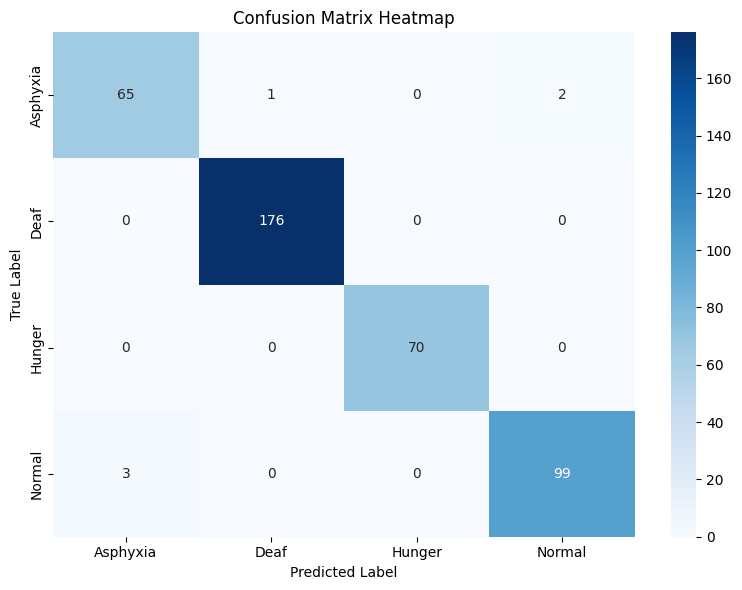

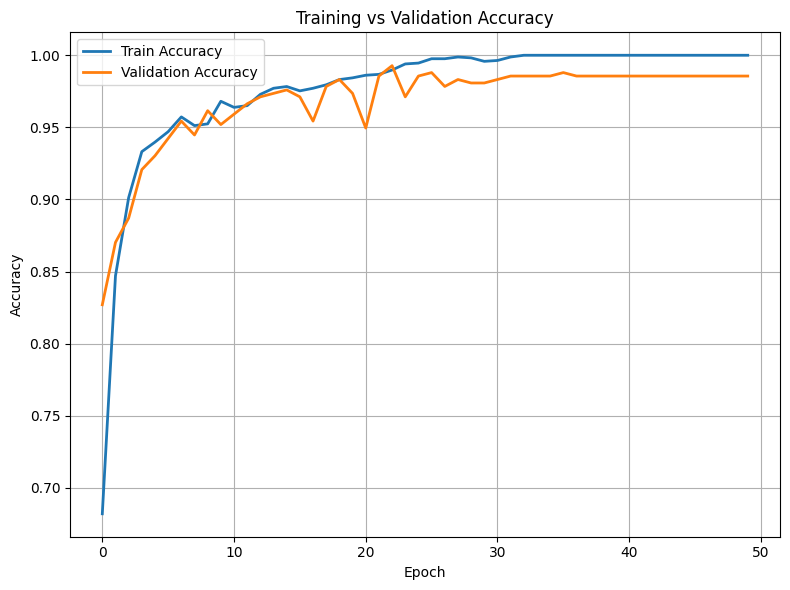

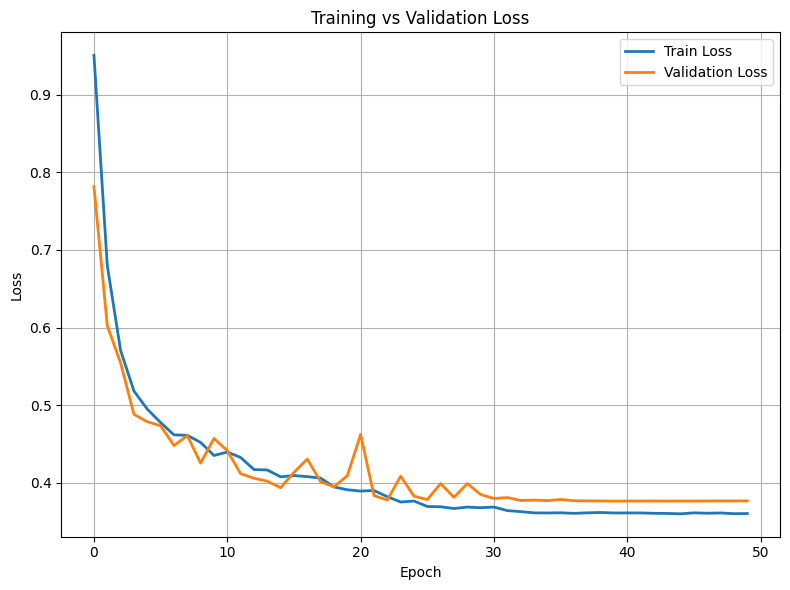

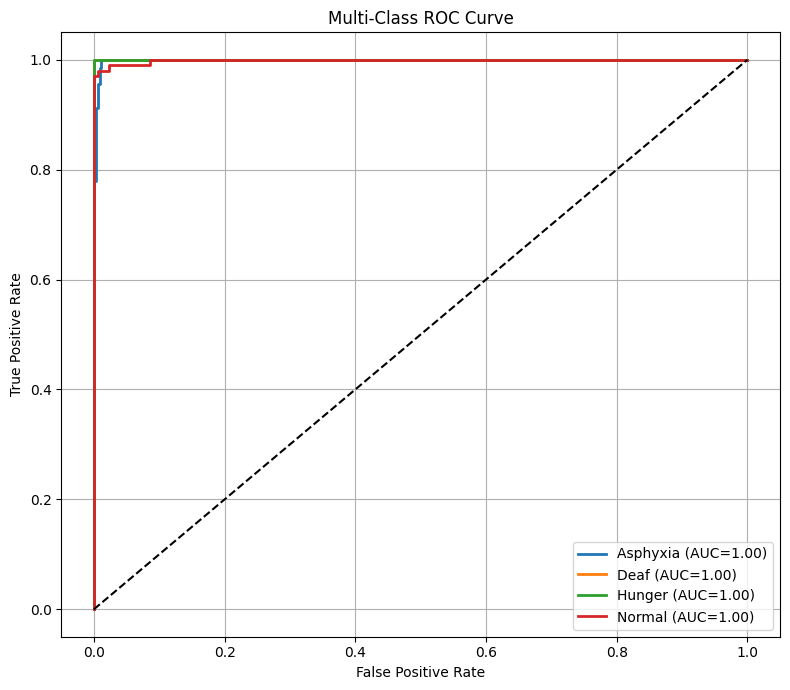


================ INFERENCE PERFORMANCE ================
Latency : 5.36 ms/image
FPS     : 186.42

================ TRAINING TIME ================
Epoch 01 : 18.68 sec
Epoch 02 : 18.33 sec
Epoch 03 : 18.37 sec
Epoch 04 : 18.39 sec
Epoch 05 : 18.53 sec
Epoch 06 : 18.46 sec
Epoch 07 : 18.49 sec
Epoch 08 : 18.39 sec
Epoch 09 : 18.41 sec
Epoch 10 : 18.47 sec
Epoch 11 : 18.47 sec
Epoch 12 : 18.43 sec
Epoch 13 : 18.39 sec
Epoch 14 : 18.39 sec
Epoch 15 : 18.36 sec
Epoch 16 : 18.38 sec
Epoch 17 : 18.30 sec
Epoch 18 : 18.35 sec
Epoch 19 : 18.30 sec
Epoch 20 : 18.30 sec
Epoch 21 : 18.34 sec
Epoch 22 : 18.39 sec
Epoch 23 : 18.40 sec
Epoch 24 : 18.38 sec
Epoch 25 : 18.41 sec
Epoch 26 : 18.36 sec
Epoch 27 : 18.41 sec
Epoch 28 : 18.43 sec
Epoch 29 : 18.47 sec
Epoch 30 : 18.47 sec
Epoch 31 : 18.49 sec
Epoch 32 : 18.45 sec
Epoch 33 : 18.39 sec
Epoch 34 : 18.41 sec
Epoch 35 : 18.48 sec
Epoch 36 : 18.37 sec
Epoch 37 : 18.45 sec
Epoch 38 : 18.48 sec
Epoch 39 : 18.42 sec
Epoch 40 : 18.37 sec
Epoch 41 : 18

In [4]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FULL FINAL)
# ============================================================

import os
import time
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-rgb/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ============================================================
# LOAD DATASET
# ============================================================

dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)

CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print("\nDetected Classes:")
print(CLASS_NAMES)

# ============================================================
# EXACT CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx = []
val_idx = []

for label, idxs in indices_by_class.items():

    np.random.shuffle(idxs)

    split = int(0.8 * len(idxs))

    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)

# Validation transform
val_ds.dataset.transform = val_tf

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"\nTrain Samples : {len(train_ds)}")
print(f"Validation Samples : {len(val_ds)}")

# ============================================================
# MODEL
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(self):
        super().__init__()

        self.proj = nn.Conv2d(
            in_channels=3,
            out_channels=192,
            kernel_size=16,
            stride=16
        )

    def forward(self, x):

        x = self.proj(x)

        x = x.flatten(2).transpose(1, 2)

        return x


class TransformerBlock(nn.Module):

    def __init__(self, dim=192, heads=6):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)

        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=heads,
            batch_first=True
        )

        self.norm2 = nn.LayerNorm(dim)

        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):

        x = x + self.attn(
            self.norm1(x),
            self.norm1(x),
            self.norm1(x)
        )[0]

        x = x + self.mlp(self.norm2(x))

        return x


class TinyCryViT(nn.Module):

    def __init__(self):
        super().__init__()

        self.patch = PatchEmbedding()

        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )

        self.bigru = nn.GRU(
            input_size=192,
            hidden_size=128,
            bidirectional=True,
            batch_first=True
        )

        self.fc = nn.Sequential(

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):

        x = self.patch(x)

        x = self.blocks(x)

        _, h = self.bigru(x)

        h = torch.cat([h[-2], h[-1]], dim=1)

        out = self.fc(h)

        return out


model = TinyCryViT().to(DEVICE)

# ============================================================
# MODEL COMPLEXITY
# ============================================================

dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)

flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = sum(
    p.numel() for p in model.parameters()
    if not p.requires_grad
)

# Model Size
torch.save(model.state_dict(), "temp_model.pth")
model_size_mb = os.path.getsize("temp_model.pth") / (1024 * 1024)

print("\n================ MODEL COMPLEXITY ================")

print(f"Total Parameters         : {params:,}")
print(f"Trainable Parameters     : {trainable_params:,}")
print(f"Non-Trainable Parameters : {non_trainable_params:,}")

print(f"FLOPs                    : {flops/1e9:.4f} GFLOPs")
print(f"Model Size               : {model_size_mb:.2f} MB")

# ============================================================
# LOSS & OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# ============================================================
# HISTORY
# ============================================================

history = {
    "train_acc": [],
    "val_acc": [],
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
}

# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(loader, train=True):

    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    correct = 0
    total = 0

    y_true = []
    y_pred = []
    y_score = []

    for x, y in loader:

        x = x.to(DEVICE)
        y = y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)

        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()

        preds = out.argmax(1)

        correct += (preds == y).sum().item()

        total += y.size(0)

        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())

        y_score.extend(
            torch.softmax(out, dim=1)
            .detach()
            .cpu()
            .numpy()
        )

    avg_loss = total_loss / len(loader)

    acc = correct / total

    return (
        avg_loss,
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )

# ============================================================
# TRAINING
# ============================================================

print("\n🚀 TRAINING STARTED 🚀")

training_start = time.time()

for epoch in range(EPOCHS):

    epoch_start = time.time()

    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, train=True)

    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(
        val_loader,
        train=False
    )

    scheduler.step()

    epoch_end = time.time()

    epoch_time = epoch_end - epoch_start

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    history["epoch_time"].append(epoch_time)

    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} |"
          f"\nEpoch Time         : {epoch_time:.2f} sec")


training_end = time.time()

total_training_time = training_end - training_start

# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(y_true, y_pred)

overall_prec, overall_rec, overall_f1, _ = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

overall_std = np.std(y_pred == y_true)

overall_rmse = math.sqrt(
    mean_squared_error(y_true, y_pred)
)

print("\n================ OVERALL METRICS ================")

print(f"Accuracy      : {overall_acc:.4f}")
print(f"Precision     : {overall_prec:.4f}")
print(f"Recall        : {overall_rec:.4f}")
print(f"F1-Score      : {overall_f1:.4f}")
print(f"Standard Dev  : {overall_std:.4f}")
print(f"RMSE          : {overall_rmse:.4f}")

# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average=None,
        zero_division=0
    )

print("\n================ CLASSWISE METRICS ================")

for i, name in enumerate(CLASS_NAMES):

    idx = (y_true == i)

    class_acc = np.mean(y_pred[idx] == i)

    class_std = np.std(y_pred[idx] == i)

    class_rmse = math.sqrt(
        mean_squared_error(
            y_true[idx],
            y_pred[idx]
        )
    )

    print(f"\nClass : {name}")

    print(f"Accuracy      : {class_acc:.4f}")
    print(f"Precision     : {class_prec[i]:.4f}")
    print(f"Recall        : {class_rec[i]:.4f}")
    print(f"F1-Score      : {class_f1[i]:.4f}")
    print(f"Standard Dev  : {class_std:.4f}")
    print(f"RMSE          : {class_rmse:.4f}")
    print(f"Samples       : {support[i]}")

# ============================================================
# CONFUSION MATRIX (NUMERIC)
# ============================================================

cm = confusion_matrix(y_true, y_pred)

print("\n================ CONFUSION MATRIX ================")
print(cm)

# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title("Confusion Matrix Heatmap")

plt.tight_layout()

plt.show()

# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    history["train_acc"],
    label="Train Accuracy",
    linewidth=2
)

plt.plot(
    history["val_acc"],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    history["train_loss"],
    label="Train Loss",
    linewidth=2
)

plt.plot(
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(
    y_true,
    classes=range(NUM_CLASSES)
)

plt.figure(figsize=(8, 7))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{CLASS_NAMES[i]} (AUC={roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Multi-Class ROC Curve")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# LATENCY & FPS
# ============================================================

model.eval()

start = time.time()

with torch.no_grad():

    for _ in range(30):
        _ = model(dummy)

end = time.time()

latency = (end - start) / 30

fps = 1 / latency

print("\n================ INFERENCE PERFORMANCE ================")

print(f"Latency : {latency * 1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ============================================================
# TOTAL TRAINING TIME
# ============================================================

print("\n================ TRAINING TIME ================")

for i, t in enumerate(history["epoch_time"]):

    print(f"Epoch {i+1:02d} : {t:.2f} sec")

print(f"\nTotal Training Time : {total_training_time:.2f} sec")

# ============================================================
# SAVE MODEL
# ============================================================

torch.save(
    model.state_dict(),
    "TinyCryViT_FinalNew.h5"
)

print("\n✅ Model saved as TinyCryViT_FinalNew.h5")

In [ ]:
Mobilenet


Detected Classes: ['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Train Samples      : 1660
Validation Samples : 416


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21.1M/21.1M [00:01<00:00, 11.6MB/s]



================ MODEL COMPLEXITY ================
Total Parameters         : 4,207,156.0
Trainable Parameters     : 4,207,156
Non-Trainable Parameters : 0
FLOPs                    : 0.2336 GFLOPs
Model Size               : 16.30 MB

🚀 TRAINING STARTED

Epoch [1/50]
Train Accuracy      : 0.7898
Validation Accuracy : 0.6803
Train Loss          : 0.7603
Validation Loss     : 1.0633
Epoch Time          : 21.93 sec

Epoch [2/50]
Train Accuracy      : 0.9717
Validation Accuracy : 0.7308
Train Loss          : 0.4406
Validation Loss     : 0.8725
Epoch Time          : 20.28 sec

Epoch [3/50]
Train Accuracy      : 0.9922
Validation Accuracy : 0.8462
Train Loss          : 0.3929
Validation Loss     : 0.6337
Epoch Time          : 20.25 sec

Epoch [4/50]
Train Accuracy      : 0.9952
Validation Accuracy : 0.9062
Train Loss          : 0.3824
Validation Loss     : 0.5366
Epoch Time          : 20.32 sec

Epoch [5/50]
Train Accuracy      : 0.9988
Validation Accuracy : 0.9567
Train Loss          : 0.37


Epoch [50/50]
Train Accuracy      : 1.0000
Validation Accuracy : 0.9784
Train Loss          : 0.3519
Validation Loss     : 0.3961
Epoch Time          : 20.30 sec

================ OVERALL METRICS ================
Accuracy      : 0.9784
Precision     : 0.9702
Recall        : 0.9767
F1 Score      : 0.9727
Std Dev       : 0.1455
RMSE          : 0.4189

================ CLASSWISE METRICS ================

Class : Asphyxia
Accuracy   : 0.9853
Precision  : 0.9054
Recall     : 0.9853
F1 Score   : 0.9437
Std Dev    : 0.1204
RMSE       : 0.3638
Samples    : 68

Class : Deaf
Accuracy   : 1.0000
Precision  : 1.0000
Recall     : 1.0000
F1 Score   : 1.0000
Std Dev    : 0.0000
RMSE       : 0.0000
Samples    : 176

Class : Hunger
Accuracy   : 1.0000
Precision  : 0.9859
Recall     : 1.0000
F1 Score   : 0.9929
Std Dev    : 0.0000
RMSE       : 0.0000
Samples    : 70

Class : Normal
Accuracy   : 0.9216
Precision  : 0.9895
Recall     : 0.9216
F1 Score   : 0.9543
Std Dev    : 0.2688
RMSE       : 0.7921
Sa

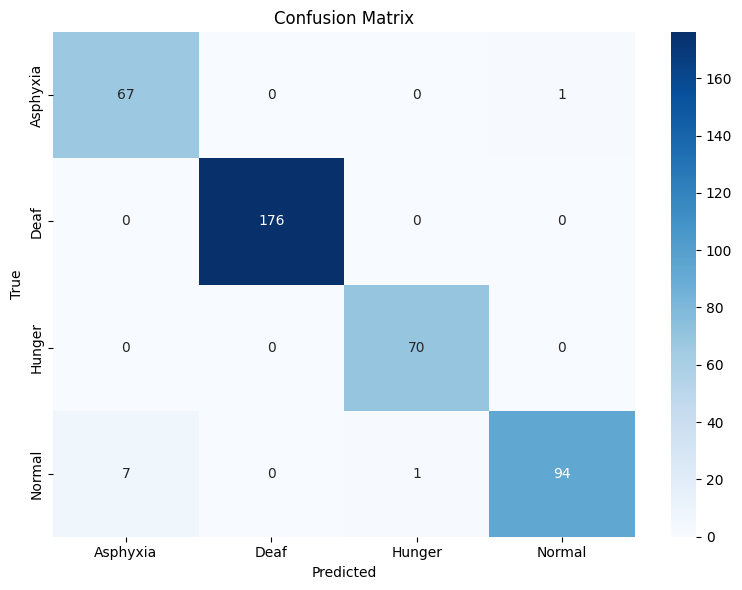

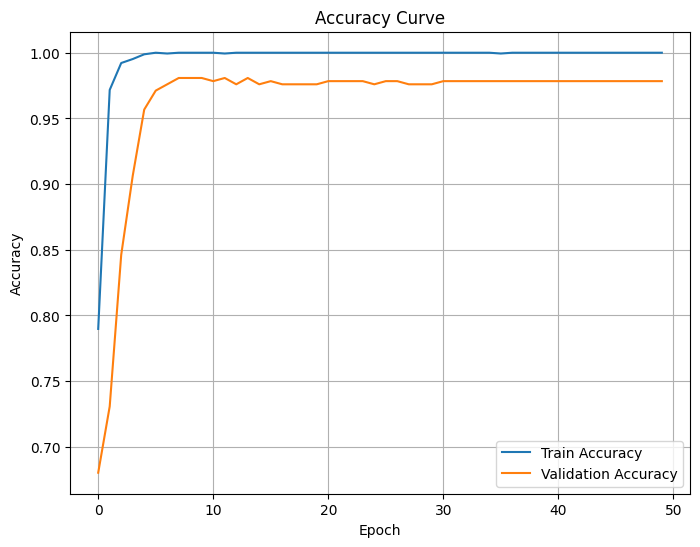

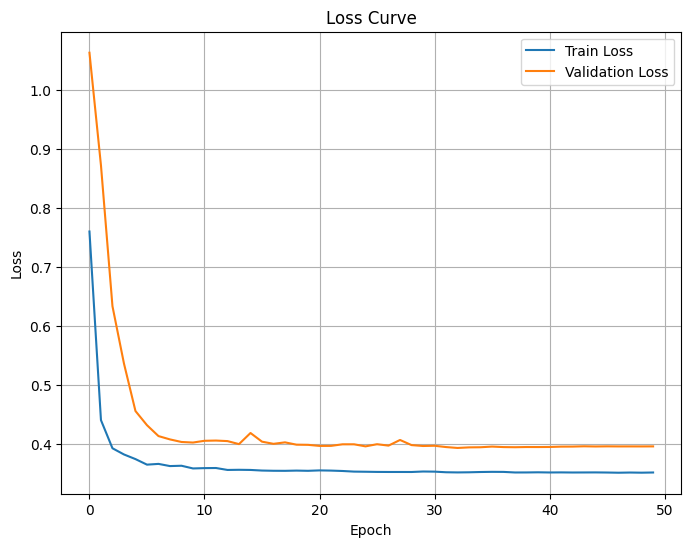

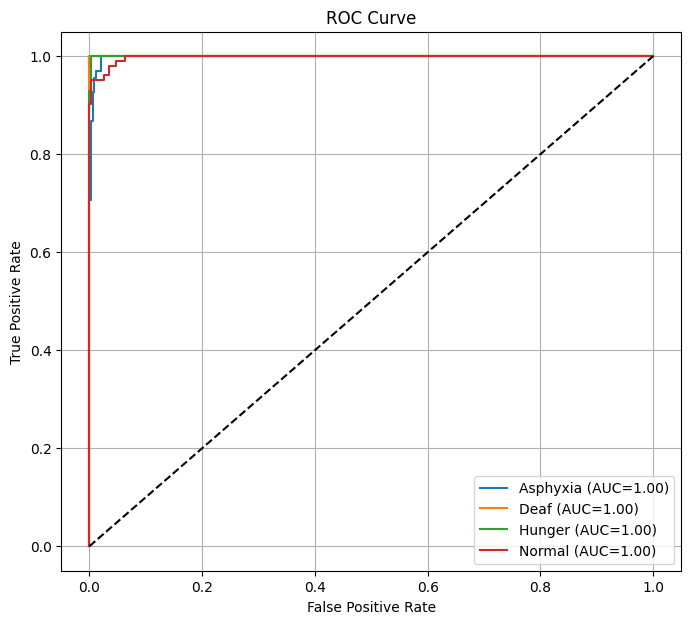


================ INFERENCE PERFORMANCE ================
Latency : 10.41 ms
FPS     : 96.08

================ TRAINING TIME ================
Epoch 01: 21.93 sec
Epoch 02: 20.28 sec
Epoch 03: 20.25 sec
Epoch 04: 20.32 sec
Epoch 05: 20.28 sec
Epoch 06: 20.27 sec
Epoch 07: 20.19 sec
Epoch 08: 20.21 sec
Epoch 09: 20.20 sec
Epoch 10: 20.24 sec
Epoch 11: 20.24 sec
Epoch 12: 20.22 sec
Epoch 13: 20.25 sec
Epoch 14: 20.25 sec
Epoch 15: 20.30 sec
Epoch 16: 20.26 sec
Epoch 17: 20.32 sec
Epoch 18: 20.28 sec
Epoch 19: 20.30 sec
Epoch 20: 20.25 sec
Epoch 21: 20.27 sec
Epoch 22: 20.29 sec
Epoch 23: 20.29 sec
Epoch 24: 20.28 sec
Epoch 25: 20.31 sec
Epoch 26: 20.31 sec
Epoch 27: 20.41 sec
Epoch 28: 20.30 sec
Epoch 29: 20.31 sec
Epoch 30: 20.27 sec
Epoch 31: 20.28 sec
Epoch 32: 20.27 sec
Epoch 33: 20.33 sec
Epoch 34: 20.30 sec
Epoch 35: 20.24 sec
Epoch 36: 20.30 sec
Epoch 37: 20.27 sec
Epoch 38: 20.27 sec
Epoch 39: 20.29 sec
Epoch 40: 20.26 sec
Epoch 41: 20.26 sec
Epoch 42: 20.26 sec
Epoch 43: 20.28 sec

In [5]:
# ============================================================
# MobileNetV3-Large – Baby Chillanto RGB Classification
# ============================================================

import os
import time
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ============================================================
# CONFIG
# ============================================================

DATA_ROOT = "/workspace/work2-rgb/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2,0.2,0.2,0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3,[0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3,[0.5]*3)
])

# ============================================================
# LOAD DATASET
# ============================================================

dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)

CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print("\nDetected Classes:", CLASS_NAMES)

# ============================================================
# EXACT 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx = []
val_idx = []

for label, idxs in indices_by_class.items():

    np.random.shuffle(idxs)

    split = int(0.8 * len(idxs))

    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)

val_ds.dataset.transform = val_tf

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Train Samples      : {len(train_ds)}")
print(f"Validation Samples : {len(val_ds)}")

# ============================================================
# MODEL - MobileNetV3 Large
# ============================================================

model = models.mobilenet_v3_large(weights="IMAGENET1K_V1")

# Replace classifier
model.classifier[3] = nn.Linear(
    in_features=model.classifier[3].in_features,
    out_features=NUM_CLASSES
)

model = model.to(DEVICE)

# ============================================================
# MODEL COMPLEXITY
# ============================================================

dummy = torch.randn(1,3,IMG_SIZE,IMG_SIZE).to(DEVICE)

flops, params = profile(
    model,
    inputs=(dummy,),
    verbose=False
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

torch.save(model.state_dict(), "temp_model.pth")
model_size_mb = os.path.getsize("temp_model.pth")/(1024*1024)

print("\n================ MODEL COMPLEXITY ================")
print(f"Total Parameters         : {params:,}")
print(f"Trainable Parameters     : {trainable_params:,}")
print(f"Non-Trainable Parameters : {non_trainable_params:,}")
print(f"FLOPs                    : {flops/1e9:.4f} GFLOPs")
print(f"Model Size               : {model_size_mb:.2f} MB")

# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# ============================================================
# HISTORY
# ============================================================

history = {
    "train_acc": [],
    "val_acc": [],
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
}

# ============================================================
# TRAIN / VALIDATE
# ============================================================

def run_epoch(loader, train=True):

    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    correct = 0
    total = 0

    y_true = []
    y_pred = []
    y_score = []

    for x,y in loader:

        x = x.to(DEVICE)
        y = y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)

        loss = criterion(out,y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()

        preds = out.argmax(1)

        correct += (preds==y).sum().item()
        total += y.size(0)

        y_true.extend(y.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

        y_score.extend(
            torch.softmax(out,1)
            .detach()
            .cpu()
            .numpy()
        )

    avg_loss = total_loss/len(loader)
    acc = correct/total

    return (
        avg_loss,
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )

# ============================================================
# TRAINING
# ============================================================

print("\n🚀 TRAINING STARTED")

training_start = time.time()

for epoch in range(EPOCHS):

    start_epoch = time.time()

    tr_loss,tr_acc,_,_,_ = run_epoch(train_loader,True)

    val_loss,val_acc,y_true,y_pred,y_score = run_epoch(
        val_loader,
        False
    )

    scheduler.step()

    epoch_time = time.time() - start_epoch

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)
    history["epoch_time"].append(epoch_time)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Accuracy      : {tr_acc:.4f}")
    print(f"Validation Accuracy : {val_acc:.4f}")
    print(f"Train Loss          : {tr_loss:.4f}")
    print(f"Validation Loss     : {val_loss:.4f}")
    print(f"Epoch Time          : {epoch_time:.2f} sec")

training_end = time.time()
total_training_time = training_end-training_start

# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(y_true,y_pred)

overall_prec,overall_rec,overall_f1,_ = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
)

overall_std = np.std(y_pred==y_true)

overall_rmse = math.sqrt(
    mean_squared_error(y_true,y_pred)
)

print("\n================ OVERALL METRICS ================")
print(f"Accuracy      : {overall_acc:.4f}")
print(f"Precision     : {overall_prec:.4f}")
print(f"Recall        : {overall_rec:.4f}")
print(f"F1 Score      : {overall_f1:.4f}")
print(f"Std Dev       : {overall_std:.4f}")
print(f"RMSE          : {overall_rmse:.4f}")

# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec,class_rec,class_f1,support = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average=None,
        zero_division=0
)

print("\n================ CLASSWISE METRICS ================")

for i,name in enumerate(CLASS_NAMES):

    idx = (y_true==i)

    class_acc = np.mean(y_pred[idx]==i)

    class_std = np.std(y_pred[idx]==i)

    class_rmse = math.sqrt(
        mean_squared_error(
            y_true[idx],
            y_pred[idx]
        )
    )

    print(f"\nClass : {name}")
    print(f"Accuracy   : {class_acc:.4f}")
    print(f"Precision  : {class_prec[i]:.4f}")
    print(f"Recall     : {class_rec[i]:.4f}")
    print(f"F1 Score   : {class_f1[i]:.4f}")
    print(f"Std Dev    : {class_std:.4f}")
    print(f"RMSE       : {class_rmse:.4f}")
    print(f"Samples    : {support[i]}")

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_true,y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(8,6))
plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(figsize=(8,6))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(
    y_true,
    classes=range(NUM_CLASSES)
)

plt.figure(figsize=(8,7))

for i in range(NUM_CLASSES):

    fpr,tpr,_ = roc_curve(
        y_bin[:,i],
        y_score[:,i]
    )

    roc_auc = auc(fpr,tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{CLASS_NAMES[i]} (AUC={roc_auc:.2f})"
    )

plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# LATENCY & FPS
# ============================================================

model.eval()

start = time.time()

with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)

end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n================ INFERENCE PERFORMANCE ================")
print(f"Latency : {latency*1000:.2f} ms")
print(f"FPS     : {fps:.2f}")

# ============================================================
# TRAINING TIME
# ============================================================

print("\n================ TRAINING TIME ================")

for i,t in enumerate(history["epoch_time"]):
    print(f"Epoch {i+1:02d}: {t:.2f} sec")

print(f"\nTotal Training Time: {total_training_time:.2f} sec")

# ============================================================
# SAVE MODEL
# ============================================================

torch.save(
    model.state_dict(),
    "MobileNet_BabyCry_Final.h5"
)

print("\n✅ Model saved as MobileNet_BabyCry_Final.h5")

In [ ]:
ResNet-50


Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']

Train Samples      : 1660
Validation Samples : 416


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [00:08<00:00, 11.7MB/s]



================ MODEL COMPLEXITY ================
Total Parameters         : 23,516,228.0
Trainable Parameters     : 23,516,228
Non-Trainable Parameters : 0
FLOPs                    : 4.1317 GFLOPs
Model Size               : 90.02 MB

🚀 TRAINING STARTED 🚀

Epoch [1/50]
Train Accuracy      : 0.8958
Validation Accuracy : 0.9639
Train Loss          : 0.5878
Validation Loss     : 0.4500
Epoch Time          : 25.16 sec

Epoch [2/50]
Train Accuracy      : 0.9898
Validation Accuracy : 0.9808
Train Loss          : 0.3938
Validation Loss     : 0.4170
Epoch Time          : 24.52 sec

Epoch [3/50]
Train Accuracy      : 0.9982
Validation Accuracy : 0.9760
Train Loss          : 0.3701
Validation Loss     : 0.4030
Epoch Time          : 24.34 sec

Epoch [4/50]
Train Accuracy      : 1.0000
Validation Accuracy : 0.9760
Train Loss          : 0.3620
Validation Loss     : 0.3918
Epoch Time          : 24.41 sec

Epoch [5/50]
Train Accuracy      : 1.0000
Validation Accuracy : 0.9784
Train Loss          : 


Epoch [50/50]
Train Accuracy      : 1.0000
Validation Accuracy : 0.9808
Train Loss          : 0.3491
Validation Loss     : 0.3869
Epoch Time          : 24.59 sec

================ OVERALL METRICS ================
Accuracy      : 0.9808
Precision     : 0.9730
Recall        : 0.9792
F1 Score      : 0.9757
Standard Dev  : 0.1373
RMSE          : 0.3397

================ CLASSWISE METRICS ================

Class : Asphyxia
Accuracy   : 0.9853
Precision  : 0.9437
Recall     : 0.9853
F1 Score   : 0.9640
Std Dev    : 0.1204
RMSE       : 0.3638
Samples    : 68

Class : Deaf
Accuracy   : 1.0000
Precision  : 1.0000
Recall     : 1.0000
F1 Score   : 1.0000
Std Dev    : 0.0000
RMSE       : 0.0000
Samples    : 176

Class : Hunger
Accuracy   : 1.0000
Precision  : 0.9589
Recall     : 1.0000
F1 Score   : 0.9790
Std Dev    : 0.0000
RMSE       : 0.0000
Samples    : 70

Class : Normal
Accuracy   : 0.9314
Precision  : 0.9896
Recall     : 0.9314
F1 Score   : 0.9596
Std Dev    : 0.2528
RMSE       : 0.6183
Sa

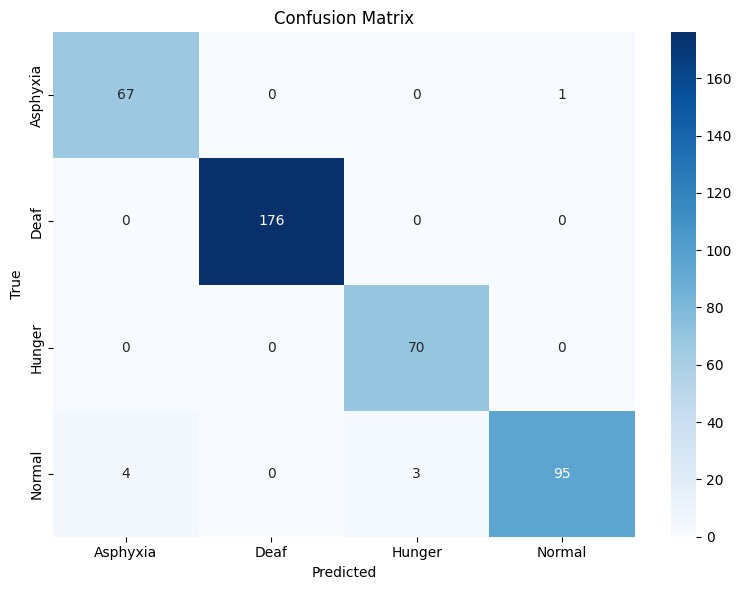

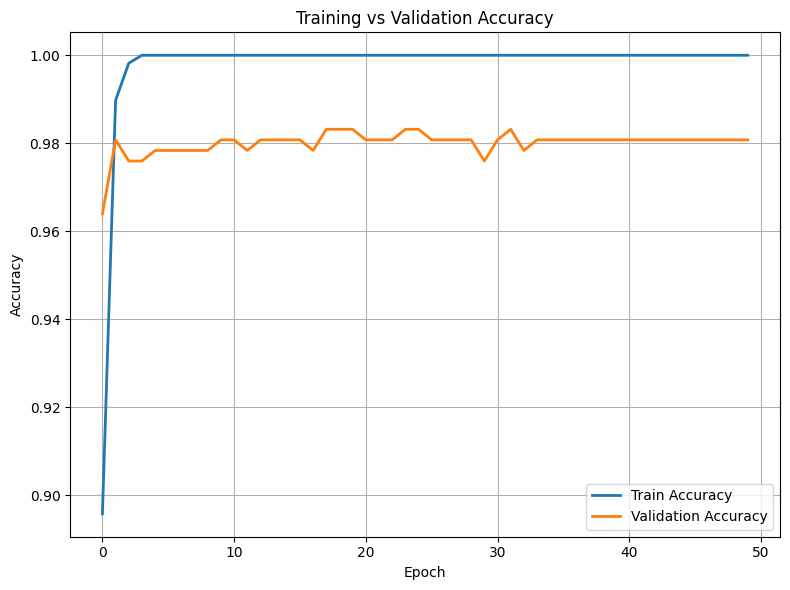

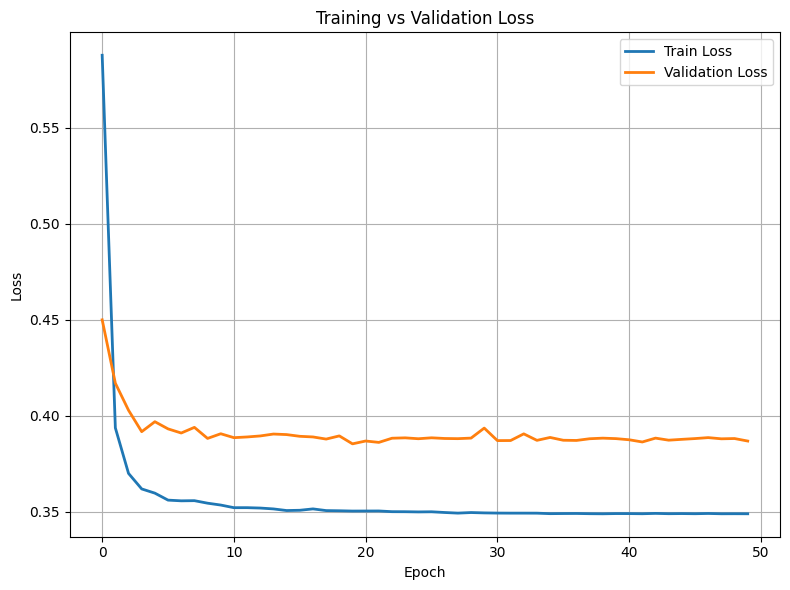

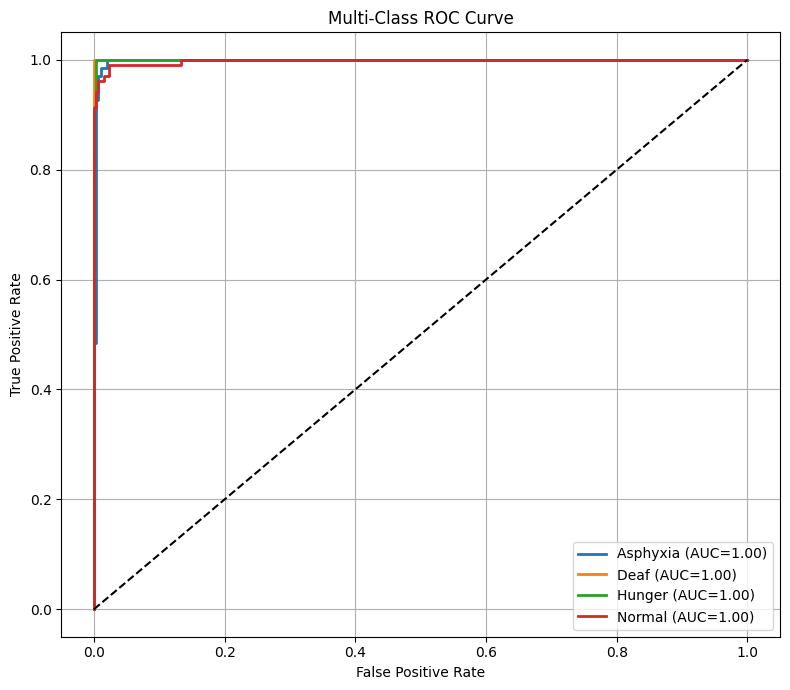


================ INFERENCE PERFORMANCE ================
Latency : 10.09 ms
FPS     : 99.12

================ TRAINING TIME ================
Epoch 01 : 25.16 sec
Epoch 02 : 24.52 sec
Epoch 03 : 24.34 sec
Epoch 04 : 24.41 sec
Epoch 05 : 24.42 sec
Epoch 06 : 24.58 sec
Epoch 07 : 24.56 sec
Epoch 08 : 24.51 sec
Epoch 09 : 24.52 sec
Epoch 10 : 24.53 sec
Epoch 11 : 24.33 sec
Epoch 12 : 24.41 sec
Epoch 13 : 24.23 sec
Epoch 14 : 24.38 sec
Epoch 15 : 24.42 sec
Epoch 16 : 24.28 sec
Epoch 17 : 24.29 sec
Epoch 18 : 24.50 sec
Epoch 19 : 24.50 sec
Epoch 20 : 24.57 sec
Epoch 21 : 24.48 sec
Epoch 22 : 24.64 sec
Epoch 23 : 24.51 sec
Epoch 24 : 24.69 sec
Epoch 25 : 24.66 sec
Epoch 26 : 24.28 sec
Epoch 27 : 24.44 sec
Epoch 28 : 24.46 sec
Epoch 29 : 24.57 sec
Epoch 30 : 24.49 sec
Epoch 31 : 24.38 sec
Epoch 32 : 24.59 sec
Epoch 33 : 24.43 sec
Epoch 34 : 24.35 sec
Epoch 35 : 24.39 sec
Epoch 36 : 24.45 sec
Epoch 37 : 24.41 sec
Epoch 38 : 24.17 sec
Epoch 39 : 24.35 sec
Epoch 40 : 24.46 sec
Epoch 41 : 24.58 se

In [6]:
# ============================================================
# ResNet50 – Baby Chillanto RGB Classification
# ============================================================

import os
import time
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ============================================================
# CONFIG
# ============================================================

DATA_ROOT = "/workspace/work2-rgb/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2,0.2,0.2,0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3,[0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3,[0.5]*3)
])

# ============================================================
# LOAD DATASET
# ============================================================

dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)

CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print("\nDetected Classes:")
print(CLASS_NAMES)

# ============================================================
# EXACT 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx = []
val_idx = []

for label, idxs in indices_by_class.items():

    np.random.shuffle(idxs)

    split = int(0.8 * len(idxs))

    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)

val_ds.dataset.transform = val_tf

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"\nTrain Samples      : {len(train_ds)}")
print(f"Validation Samples : {len(val_ds)}")

# ============================================================
# MODEL - RESNET50
# ============================================================

model = models.resnet50(weights="IMAGENET1K_V1")

# Replace Final Fully Connected Layer
model.fc = nn.Linear(
    in_features=model.fc.in_features,
    out_features=NUM_CLASSES
)

model = model.to(DEVICE)

# ============================================================
# MODEL COMPLEXITY
# ============================================================

dummy = torch.randn(1,3,IMG_SIZE,IMG_SIZE).to(DEVICE)

flops, params = profile(
    model,
    inputs=(dummy,),
    verbose=False
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

# Model Size
torch.save(model.state_dict(), "temp_model.pth")

model_size_mb = os.path.getsize(
    "temp_model.pth"
)/(1024*1024)

print("\n================ MODEL COMPLEXITY ================")

print(f"Total Parameters         : {params:,}")
print(f"Trainable Parameters     : {trainable_params:,}")
print(f"Non-Trainable Parameters : {non_trainable_params:,}")

print(f"FLOPs                    : {flops/1e9:.4f} GFLOPs")
print(f"Model Size               : {model_size_mb:.2f} MB")

# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# ============================================================
# HISTORY
# ============================================================

history = {
    "train_acc": [],
    "val_acc": [],
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
}

# ============================================================
# TRAIN / VALIDATE FUNCTION
# ============================================================

def run_epoch(loader, train=True):

    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    correct = 0
    total = 0

    y_true = []
    y_pred = []
    y_score = []

    for x, y in loader:

        x = x.to(DEVICE)
        y = y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)

        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()

        preds = out.argmax(1)

        correct += (preds == y).sum().item()

        total += y.size(0)

        y_true.extend(
            y.detach().cpu().numpy()
        )

        y_pred.extend(
            preds.detach().cpu().numpy()
        )

        y_score.extend(
            torch.softmax(out, dim=1)
            .detach()
            .cpu()
            .numpy()
        )

    avg_loss = total_loss / len(loader)

    acc = correct / total

    return (
        avg_loss,
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )

# ============================================================
# TRAINING
# ============================================================

print("\n🚀 TRAINING STARTED 🚀")

training_start = time.time()

for epoch in range(EPOCHS):

    epoch_start = time.time()

    tr_loss, tr_acc, _, _, _ = run_epoch(
        train_loader,
        train=True
    )

    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(
        val_loader,
        train=False
    )

    scheduler.step()

    epoch_time = time.time() - epoch_start

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    history["epoch_time"].append(epoch_time)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")

    print(f"Train Accuracy      : {tr_acc:.4f}")
    print(f"Validation Accuracy : {val_acc:.4f}")

    print(f"Train Loss          : {tr_loss:.4f}")
    print(f"Validation Loss     : {val_loss:.4f}")

    print(f"Epoch Time          : {epoch_time:.2f} sec")

training_end = time.time()

total_training_time = (
    training_end - training_start
)

# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(
    y_true,
    y_pred
)

overall_prec, overall_rec, overall_f1, _ = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
)

overall_std = np.std(
    y_pred == y_true
)

overall_rmse = math.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

print("\n================ OVERALL METRICS ================")

print(f"Accuracy      : {overall_acc:.4f}")
print(f"Precision     : {overall_prec:.4f}")
print(f"Recall        : {overall_rec:.4f}")
print(f"F1 Score      : {overall_f1:.4f}")

print(f"Standard Dev  : {overall_std:.4f}")
print(f"RMSE          : {overall_rmse:.4f}")

# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average=None,
        zero_division=0
)

print("\n================ CLASSWISE METRICS ================")

for i, name in enumerate(CLASS_NAMES):

    idx = (y_true == i)

    class_acc = np.mean(
        y_pred[idx] == i
    )

    class_std = np.std(
        y_pred[idx] == i
    )

    class_rmse = math.sqrt(
        mean_squared_error(
            y_true[idx],
            y_pred[idx]
        )
    )

    print(f"\nClass : {name}")

    print(f"Accuracy   : {class_acc:.4f}")
    print(f"Precision  : {class_prec[i]:.4f}")
    print(f"Recall     : {class_rec[i]:.4f}")
    print(f"F1 Score   : {class_f1[i]:.4f}")

    print(f"Std Dev    : {class_std:.4f}")
    print(f"RMSE       : {class_rmse:.4f}")

    print(f"Samples    : {support[i]}")

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n================ CONFUSION MATRIX ================")
print(cm)

# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("True")

plt.tight_layout()

plt.show()

# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(8,6))

plt.plot(
    history["train_acc"],
    label="Train Accuracy",
    linewidth=2
)

plt.plot(
    history["val_acc"],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(figsize=(8,6))

plt.plot(
    history["train_loss"],
    label="Train Loss",
    linewidth=2
)

plt.plot(
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(
    y_true,
    classes=range(NUM_CLASSES)
)

plt.figure(figsize=(8,7))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{CLASS_NAMES[i]} (AUC={roc_auc:.2f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Multi-Class ROC Curve")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# LATENCY & FPS
# ============================================================

model.eval()

start = time.time()

with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)

end = time.time()

latency = (end - start) / 30

fps = 1 / latency

print("\n================ INFERENCE PERFORMANCE ================")

print(f"Latency : {latency*1000:.2f} ms")
print(f"FPS     : {fps:.2f}")

# ============================================================
# TRAINING TIME
# ============================================================

print("\n================ TRAINING TIME ================")

for i, t in enumerate(history["epoch_time"]):

    print(f"Epoch {i+1:02d} : {t:.2f} sec")

print(f"\nTotal Training Time : {total_training_time:.2f} sec")

# ============================================================
# SAVE MODEL
# ============================================================

torch.save(
    model.state_dict(),
    "ResNet50_BabyCry_Final.h5"
)

print("\n✅ Model saved as ResNet50_BabyCry_Final.h5")

In [ ]:
3Class

Detected classes: ['Asphyxia', 'Deaf', 'Normal']
Train samples: 1380 | Val samples: 346

--- Model Complexity ---
Total Params      : 1,318,147.0
Trainable Params  : 1,762,819
Non-Trainable     : 0
FLOPs             : 0.25 GFLOPs

🚀 Training Started
Epoch [1/50] | Train Acc: 0.7899 | Val Acc: 0.9393 | Train Loss: 0.6697 | Val Loss: 0.4846
Epoch [2/50] | Train Acc: 0.9283 | Val Acc: 0.9538 | Train Loss: 0.4498 | Val Loss: 0.3863
Epoch [3/50] | Train Acc: 0.9478 | Val Acc: 0.9682 | Train Loss: 0.3942 | Val Loss: 0.3644
Epoch [4/50] | Train Acc: 0.9594 | Val Acc: 0.9653 | Train Loss: 0.3790 | Val Loss: 0.3547
Epoch [5/50] | Train Acc: 0.9594 | Val Acc: 0.9682 | Train Loss: 0.3731 | Val Loss: 0.3510
Epoch [6/50] | Train Acc: 0.9623 | Val Acc: 0.9740 | Train Loss: 0.3648 | Val Loss: 0.3582
Epoch [7/50] | Train Acc: 0.9674 | Val Acc: 0.9740 | Train Loss: 0.3581 | Val Loss: 0.3506
Epoch [8/50] | Train Acc: 0.9688 | Val Acc: 0.9740 | Train Loss: 0.3534 | Val Loss: 0.3437
Epoch [9/50] | Train A

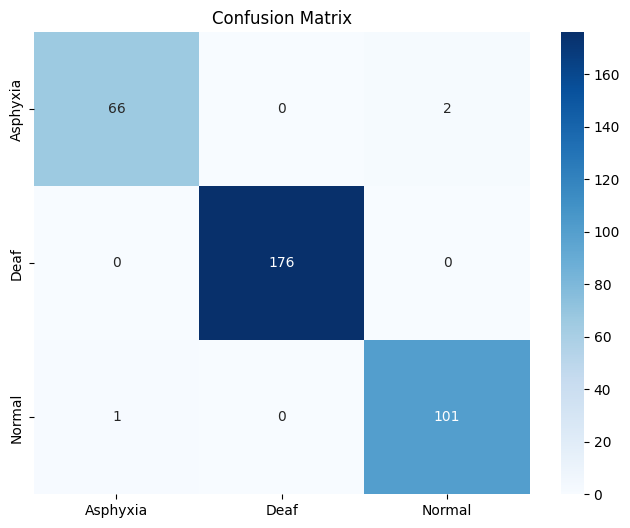

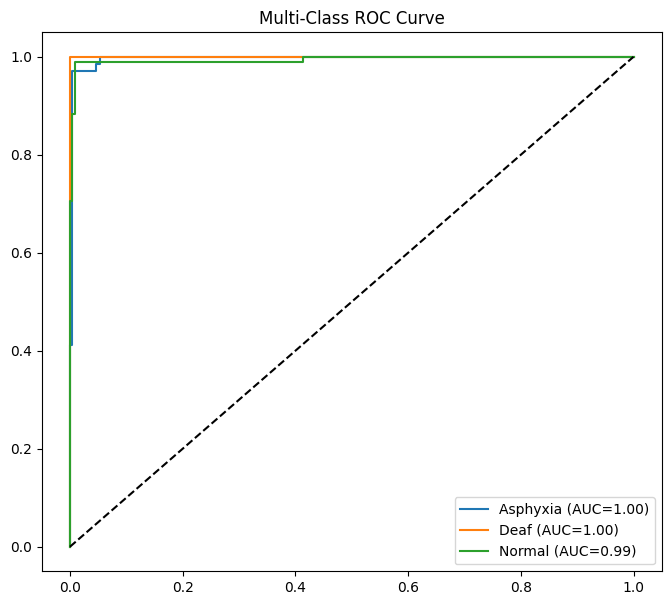


--- Inference Performance ---
Latency : 5.16 ms/image
FPS     : 193.66

✅ Model saved as TinyCryViT_3Class_Final.h5


In [15]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FINAL)
# ============================================================

import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-3class/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# =========================================

# ================= TRANSFORMS =================
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ================= LOAD DATA =================
dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Detected classes: {CLASS_NAMES}")

# ================= EXACT CLASS-WISE 80:20 SPLIT =================
indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx, val_idx = [], []
for label, idxs in indices_by_class.items():
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
val_ds.dataset.transform = val_tf

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

# ================= MODEL =================
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(3, 192, 16, 16)

    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class TransformerBlock(nn.Module):
    def __init__(self, dim=192, heads=6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class TinyCryViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )
        self.bigru = nn.GRU(192, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.patch(x)
        x = self.blocks(x)
        _, h = self.bigru(x)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h)

model = TinyCryViT().to(DEVICE)

# ================= MODEL COMPLEXITY =================
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)

print("\n--- Model Complexity ---")
print(f"Total Params      : {params:,}")
print(f"Trainable Params  : {trainable:,}")
print(f"Non-Trainable     : {non_trainable:,}")
print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")

# ================= TRAINING =================
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

history = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    y_true, y_pred, y_score = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)
        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        # ✅ SAFE DETACH
        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        y_score.extend(torch.softmax(out, 1).detach().cpu().numpy())

    acc = correct / total
    return (
        total_loss / len(loader),
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


print("\n🚀 Training Started")
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(val_loader, False)
    scheduler.step()

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

# ================= OVERALL METRICS =================
overall_acc = accuracy_score(y_true, y_pred)
overall_prec, overall_rec, overall_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n--- Overall Metrics ---")
print(f"Accuracy : {overall_acc:.4f}")
print(f"Precision: {overall_prec:.4f}")
print(f"Recall   : {overall_rec:.4f}")
print(f"F1-score : {overall_f1:.4f}")

# ================= CLASS-WISE METRICS =================
class_prec, class_rec, class_f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

print("\n--- Class-wise Metrics ---")
for i, name in enumerate(CLASS_NAMES):
    class_acc = np.mean(y_pred[y_true == i] == i)
    print(f"\n{name}")
    print(f"  Accuracy : {class_acc:.4f}")
    print(f"  Precision: {class_prec[i]:.4f}")
    print(f"  Recall   : {class_rec[i]:.4f}")
    print(f"  F1-score : {class_f1[i]:.4f}")
    print(f"  Samples  : {support[i]}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ================= ROC CURVE =================
y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
plt.figure(figsize=(8,7))
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={auc(fpr,tpr):.2f})")
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("Multi-Class ROC Curve")
plt.show()

# ================= LATENCY & FPS =================
model.eval()
start = time.time()
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)
end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n--- Inference Performance ---")
print(f"Latency : {latency*1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ================= SAVE MODEL (.h5) =================
torch.save(model.state_dict(), "TinyCryViT_3Class_Final.h5")
print("\n✅ Model saved as TinyCryViT_3Class_Final.h5")


In [ ]:
2Class

Detected classes: ['Asphyxia', 'Hunger']
Train samples: 552 | Val samples: 138

--- Model Complexity ---
Total Params      : 1,318,018.0
Trainable Params  : 1,762,690
Non-Trainable     : 0
FLOPs             : 0.25 GFLOPs

🚀 Training Started
Epoch [1/50] | Train Acc: 0.7645 | Val Acc: 0.9420 | Train Loss: 0.5756 | Val Loss: 0.4280
Epoch [2/50] | Train Acc: 0.9529 | Val Acc: 0.9928 | Train Loss: 0.3215 | Val Loss: 0.2294
Epoch [3/50] | Train Acc: 0.9638 | Val Acc: 1.0000 | Train Loss: 0.2579 | Val Loss: 0.2136
Epoch [4/50] | Train Acc: 0.9728 | Val Acc: 0.9928 | Train Loss: 0.2493 | Val Loss: 0.2203
Epoch [5/50] | Train Acc: 0.9873 | Val Acc: 1.0000 | Train Loss: 0.2350 | Val Loss: 0.2047
Epoch [6/50] | Train Acc: 0.9819 | Val Acc: 1.0000 | Train Loss: 0.2325 | Val Loss: 0.2026
Epoch [7/50] | Train Acc: 0.9855 | Val Acc: 1.0000 | Train Loss: 0.2260 | Val Loss: 0.2031
Epoch [8/50] | Train Acc: 0.9891 | Val Acc: 0.9928 | Train Loss: 0.2238 | Val Loss: 0.2277
Epoch [9/50] | Train Acc: 0.992

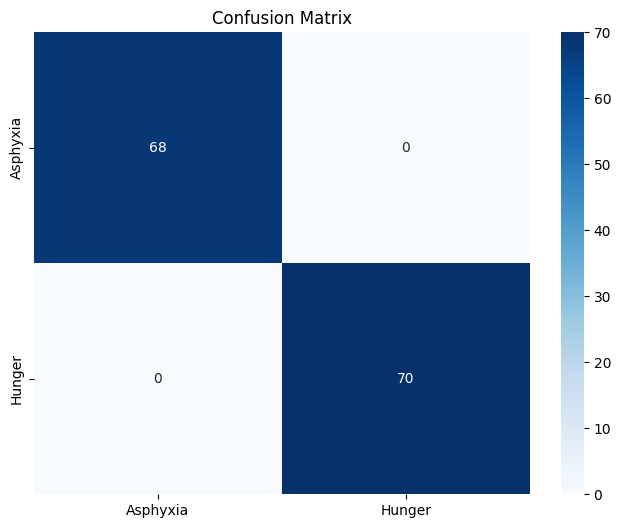

IndexError: index 1 is out of bounds for axis 1 with size 1

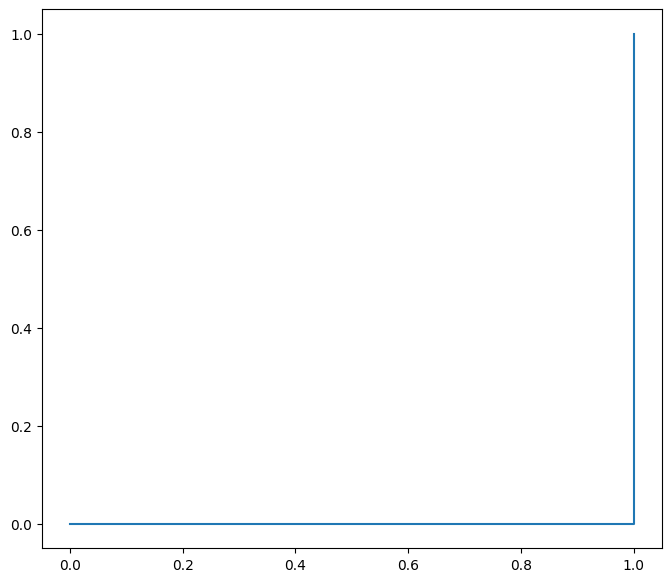

In [22]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FINAL)
# ============================================================

import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-2class/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# =========================================

# ================= TRANSFORMS =================
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ================= LOAD DATA =================
dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Detected classes: {CLASS_NAMES}")

# ================= EXACT CLASS-WISE 80:20 SPLIT =================
indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx, val_idx = [], []
for label, idxs in indices_by_class.items():
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
val_ds.dataset.transform = val_tf

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

# ================= MODEL =================
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(3, 192, 16, 16)

    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class TransformerBlock(nn.Module):
    def __init__(self, dim=192, heads=6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class TinyCryViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )
        self.bigru = nn.GRU(192, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.patch(x)
        x = self.blocks(x)
        _, h = self.bigru(x)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h)

model = TinyCryViT().to(DEVICE)

# ================= MODEL COMPLEXITY =================
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)

print("\n--- Model Complexity ---")
print(f"Total Params      : {params:,}")
print(f"Trainable Params  : {trainable:,}")
print(f"Non-Trainable     : {non_trainable:,}")
print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")

# ================= TRAINING =================
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

history = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    y_true, y_pred, y_score = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)
        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        # ✅ SAFE DETACH
        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        y_score.extend(torch.softmax(out, 1).detach().cpu().numpy())

    acc = correct / total
    return (
        total_loss / len(loader),
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


print("\n🚀 Training Started")
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(val_loader, False)
    scheduler.step()

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

# ================= OVERALL METRICS =================
overall_acc = accuracy_score(y_true, y_pred)
overall_prec, overall_rec, overall_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n--- Overall Metrics ---")
print(f"Accuracy : {overall_acc:.4f}")
print(f"Precision: {overall_prec:.4f}")
print(f"Recall   : {overall_rec:.4f}")
print(f"F1-score : {overall_f1:.4f}")

# ================= CLASS-WISE METRICS =================
class_prec, class_rec, class_f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

print("\n--- Class-wise Metrics ---")
for i, name in enumerate(CLASS_NAMES):
    class_acc = np.mean(y_pred[y_true == i] == i)
    print(f"\n{name}")
    print(f"  Accuracy : {class_acc:.4f}")
    print(f"  Precision: {class_prec[i]:.4f}")
    print(f"  Recall   : {class_rec[i]:.4f}")
    print(f"  F1-score : {class_f1[i]:.4f}")
    print(f"  Samples  : {support[i]}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ================= ROC CURVE =================
y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
plt.figure(figsize=(8,7))
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={auc(fpr,tpr):.2f})")
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("Multi-Class ROC Curve")
plt.show()

# ================= LATENCY & FPS =================
model.eval()
start = time.time()
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)
end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n--- Inference Performance ---")
print(f"Latency : {latency*1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ================= SAVE MODEL (.h5) =================
torch.save(model.state_dict(), "TinyCryViT_2ClassNew.h5")
print("\n✅ Model saved as TinyCryViT_2Class_New.h5")


In [ ]:
2Class-Deaf&Normal

Detected classes: ['Deaf', 'Normal']
Train samples: 1108 | Val samples: 278

--- Model Complexity ---
Total Params      : 1,318,018.0
Trainable Params  : 1,762,690
Non-Trainable     : 0
FLOPs             : 0.25 GFLOPs

🚀 Training Started
Epoch [1/50] | Train Acc: 0.9449 | Val Acc: 0.9676 | Train Loss: 0.3585 | Val Loss: 0.2465
Epoch [2/50] | Train Acc: 0.9847 | Val Acc: 0.9856 | Train Loss: 0.2309 | Val Loss: 0.2231
Epoch [3/50] | Train Acc: 0.9973 | Val Acc: 0.9928 | Train Loss: 0.2129 | Val Loss: 0.2119
Epoch [4/50] | Train Acc: 0.9973 | Val Acc: 0.9964 | Train Loss: 0.2074 | Val Loss: 0.2087
Epoch [5/50] | Train Acc: 0.9991 | Val Acc: 0.9964 | Train Loss: 0.2064 | Val Loss: 0.2069
Epoch [6/50] | Train Acc: 0.9991 | Val Acc: 0.9964 | Train Loss: 0.2056 | Val Loss: 0.2073
Epoch [7/50] | Train Acc: 0.9991 | Val Acc: 0.9964 | Train Loss: 0.2057 | Val Loss: 0.2077
Epoch [8/50] | Train Acc: 0.9991 | Val Acc: 0.9928 | Train Loss: 0.2047 | Val Loss: 0.2105
Epoch [9/50] | Train Acc: 0.9991 |

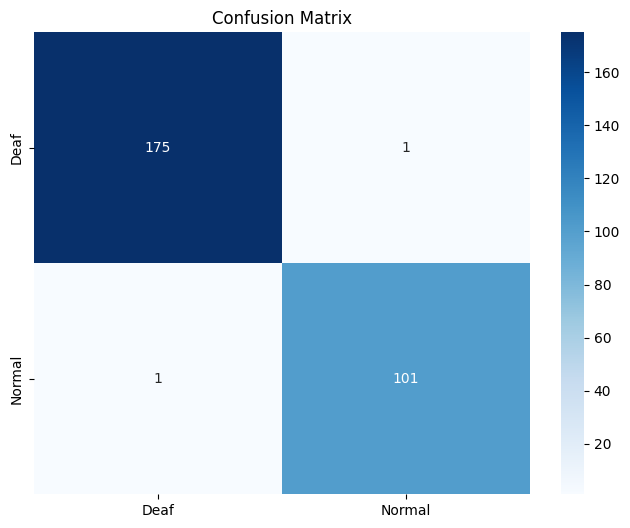

IndexError: index 1 is out of bounds for axis 1 with size 1

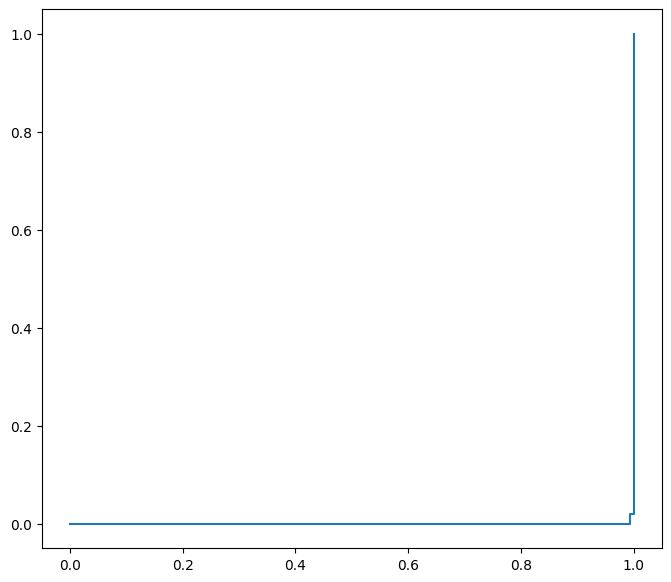

In [25]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FINAL)
# ============================================================

import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-2class-DN/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# =========================================

# ================= TRANSFORMS =================
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ================= LOAD DATA =================
dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Detected classes: {CLASS_NAMES}")

# ================= EXACT CLASS-WISE 80:20 SPLIT =================
indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx, val_idx = [], []
for label, idxs in indices_by_class.items():
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
val_ds.dataset.transform = val_tf

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

# ================= MODEL =================
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(3, 192, 16, 16)

    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class TransformerBlock(nn.Module):
    def __init__(self, dim=192, heads=6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class TinyCryViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )
        self.bigru = nn.GRU(192, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.patch(x)
        x = self.blocks(x)
        _, h = self.bigru(x)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h)

model = TinyCryViT().to(DEVICE)

# ================= MODEL COMPLEXITY =================
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)

print("\n--- Model Complexity ---")
print(f"Total Params      : {params:,}")
print(f"Trainable Params  : {trainable:,}")
print(f"Non-Trainable     : {non_trainable:,}")
print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")

# ================= TRAINING =================
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

history = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    y_true, y_pred, y_score = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)
        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        # ✅ SAFE DETACH
        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        y_score.extend(torch.softmax(out, 1).detach().cpu().numpy())

    acc = correct / total
    return (
        total_loss / len(loader),
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


print("\n🚀 Training Started")
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(val_loader, False)
    scheduler.step()

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

# ================= OVERALL METRICS =================
overall_acc = accuracy_score(y_true, y_pred)
overall_prec, overall_rec, overall_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n--- Overall Metrics ---")
print(f"Accuracy : {overall_acc:.4f}")
print(f"Precision: {overall_prec:.4f}")
print(f"Recall   : {overall_rec:.4f}")
print(f"F1-score : {overall_f1:.4f}")

# ================= CLASS-WISE METRICS =================
class_prec, class_rec, class_f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

print("\n--- Class-wise Metrics ---")
for i, name in enumerate(CLASS_NAMES):
    class_acc = np.mean(y_pred[y_true == i] == i)
    print(f"\n{name}")
    print(f"  Accuracy : {class_acc:.4f}")
    print(f"  Precision: {class_prec[i]:.4f}")
    print(f"  Recall   : {class_rec[i]:.4f}")
    print(f"  F1-score : {class_f1[i]:.4f}")
    print(f"  Samples  : {support[i]}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ================= ROC CURVE =================
y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
plt.figure(figsize=(8,7))
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={auc(fpr,tpr):.2f})")
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("Multi-Class ROC Curve")
plt.show()

# ================= LATENCY & FPS =================
model.eval()
start = time.time()
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)
end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n--- Inference Performance ---")
print(f"Latency : {latency*1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ================= SAVE MODEL (.h5) =================
torch.save(model.state_dict(), "TinyCryViT_2ClassDN.h5")
print("\n✅ Model saved as TinyCryViT_2Class_DN.h5")


In [ ]:
2class

Detected classes: ['Asphyxia', 'Hunger']
Train samples: 552 | Val samples: 138

--- Model Complexity ---
Total Params      : 1,318,018.0
Trainable Params  : 1,762,690
Non-Trainable     : 0
FLOPs             : 0.25 GFLOPs

🚀 Training Started
Epoch [1/50] | Train Acc: 0.8551 | Val Acc: 0.9203 | Train Loss: 0.5230 | Val Loss: 0.3400
Epoch [2/50] | Train Acc: 0.9565 | Val Acc: 0.9420 | Train Loss: 0.3128 | Val Loss: 0.2889
Epoch [3/50] | Train Acc: 0.9674 | Val Acc: 0.9710 | Train Loss: 0.2523 | Val Loss: 0.2521
Epoch [4/50] | Train Acc: 0.9801 | Val Acc: 0.9638 | Train Loss: 0.2395 | Val Loss: 0.2512
Epoch [5/50] | Train Acc: 0.9855 | Val Acc: 0.9710 | Train Loss: 0.2293 | Val Loss: 0.2315
Epoch [6/50] | Train Acc: 0.9909 | Val Acc: 0.9783 | Train Loss: 0.2188 | Val Loss: 0.2276
Epoch [7/50] | Train Acc: 0.9964 | Val Acc: 0.9783 | Train Loss: 0.2133 | Val Loss: 0.2202
Epoch [8/50] | Train Acc: 0.9982 | Val Acc: 0.9928 | Train Loss: 0.2110 | Val Loss: 0.2161
Epoch [9/50] | Train Acc: 1.000

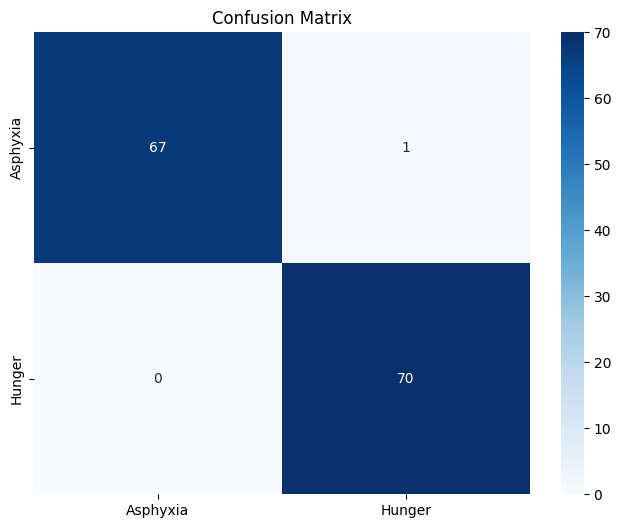

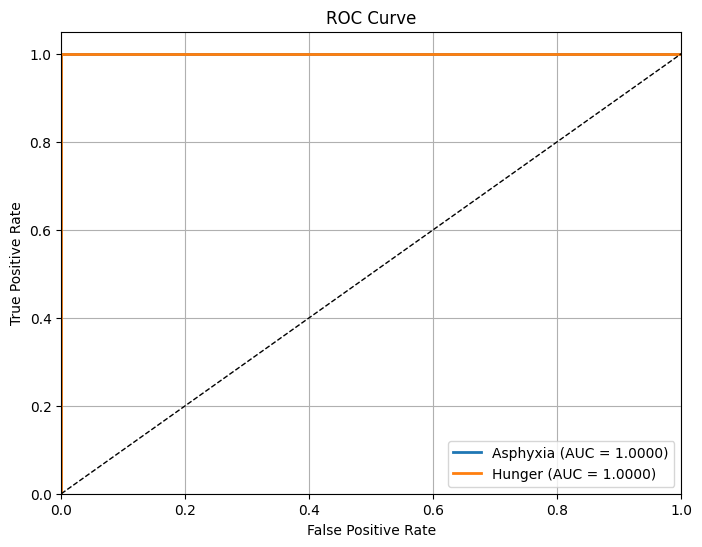


========== ROC-AUC Scores ==========
Asphyxia : 1.0000
Hunger : 1.0000

--- Inference Performance ---
Latency : 5.51 ms/image
FPS     : 181.51

✅ Model saved as TinyCryViT_2Class_Final.h5


In [9]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FINAL)
# ============================================================

import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc
)
#from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-2class/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# =========================================

# ================= TRANSFORMS =================
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ================= LOAD DATA =================
dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Detected classes: {CLASS_NAMES}")

# ================= EXACT CLASS-WISE 80:20 SPLIT =================
indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx, val_idx = [], []
for label, idxs in indices_by_class.items():
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
val_ds.dataset.transform = val_tf

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

# ================= MODEL =================
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(3, 192, 16, 16)

    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class TransformerBlock(nn.Module):
    def __init__(self, dim=192, heads=6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class TinyCryViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )
        self.bigru = nn.GRU(192, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.patch(x)
        x = self.blocks(x)
        _, h = self.bigru(x)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h)

model = TinyCryViT().to(DEVICE)

# ================= MODEL COMPLEXITY =================
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)

print("\n--- Model Complexity ---")
print(f"Total Params      : {params:,}")
print(f"Trainable Params  : {trainable:,}")
print(f"Non-Trainable     : {non_trainable:,}")
print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")

# ================= TRAINING =================
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

history = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    y_true, y_pred, y_score = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)
        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        # ✅ SAFE DETACH
        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        y_score.extend(torch.softmax(out, 1).detach().cpu().numpy())

    acc = correct / total
    return (
        total_loss / len(loader),
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


print("\n🚀 Training Started")
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(val_loader, False)
    scheduler.step()

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

# ================= OVERALL METRICS =================
overall_acc = accuracy_score(y_true, y_pred)
overall_prec, overall_rec, overall_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n--- Overall Metrics ---")
print(f"Accuracy : {overall_acc:.4f}")
print(f"Precision: {overall_prec:.4f}")
print(f"Recall   : {overall_rec:.4f}")
print(f"F1-score : {overall_f1:.4f}")

# ================= CLASS-WISE METRICS =================
class_prec, class_rec, class_f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

print("\n--- Class-wise Metrics ---")
for i, name in enumerate(CLASS_NAMES):
    class_acc = np.mean(y_pred[y_true == i] == i)
    print(f"\n{name}")
    print(f"  Accuracy : {class_acc:.4f}")
    print(f"  Precision: {class_prec[i]:.4f}")
    print(f"  Recall   : {class_rec[i]:.4f}")
    print(f"  F1-score : {class_f1[i]:.4f}")
    print(f"  Samples  : {support[i]}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ================= ROC CURVE (Binary Classification) =================

# Probability of positive class
'''positive_scores = y_score[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_true,
    positive_scores
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

print(f"\nROC-AUC Score: {roc_auc:.4f}")'''

# ================= ROC CURVE (2-CLASS) =================

# ================= ROC CURVE (2-CLASS) =================

from sklearn.metrics import roc_curve, auc

# Convert to numpy arrays
y_true = np.array(y_true)
y_score = np.array(y_score)

plt.figure(figsize=(8,6))

roc_auc = {}

# Plot ROC for each class
for i in range(NUM_CLASSES):

    # Create binary ground truth for current class
    y_true_binary = (y_true == i).astype(int)

    # Probability of current class
    y_score_binary = y_score[:, i]

    # ROC
    fpr, tpr, _ = roc_curve(y_true_binary, y_score_binary)
    roc_auc[i] = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{CLASS_NAMES[i]} (AUC = {roc_auc[i]:.4f})"
    )

# Random classifier
plt.plot([0,1],[0,1],'k--',linewidth=1)

plt.xlim([0,1])
plt.ylim([0,1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

print("\n========== ROC-AUC Scores ==========")
for i in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[i]} : {roc_auc[i]:.4f}")

# ================= LATENCY & FPS =================
model.eval()
start = time.time()
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)
end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n--- Inference Performance ---")
print(f"Latency : {latency*1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ================= SAVE MODEL (.h5) =================
torch.save(model.state_dict(), "TinyCryViT_2Class_Final.h5")
print("\n✅ Model saved as TinyCryViT_2Class_Final.h5")


Detected classes: ['Deaf', 'Normal']
Train samples: 1108 | Val samples: 278

--- Model Complexity ---
Total Params      : 1,318,018.0
Trainable Params  : 1,762,690
Non-Trainable     : 0
FLOPs             : 0.25 GFLOPs

🚀 Training Started
Epoch [1/50] | Train Acc: 0.9341 | Val Acc: 0.9964 | Train Loss: 0.3391 | Val Loss: 0.2115
Epoch [2/50] | Train Acc: 0.9946 | Val Acc: 1.0000 | Train Loss: 0.2155 | Val Loss: 0.1991
Epoch [3/50] | Train Acc: 0.9964 | Val Acc: 1.0000 | Train Loss: 0.2109 | Val Loss: 0.1989
Epoch [4/50] | Train Acc: 0.9955 | Val Acc: 1.0000 | Train Loss: 0.2090 | Val Loss: 0.1994
Epoch [5/50] | Train Acc: 0.9973 | Val Acc: 1.0000 | Train Loss: 0.2066 | Val Loss: 0.1991
Epoch [6/50] | Train Acc: 0.9991 | Val Acc: 1.0000 | Train Loss: 0.2047 | Val Loss: 0.1990
Epoch [7/50] | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.2035 | Val Loss: 0.1988
Epoch [8/50] | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.2034 | Val Loss: 0.1988
Epoch [9/50] | Train Acc: 1.0000 |

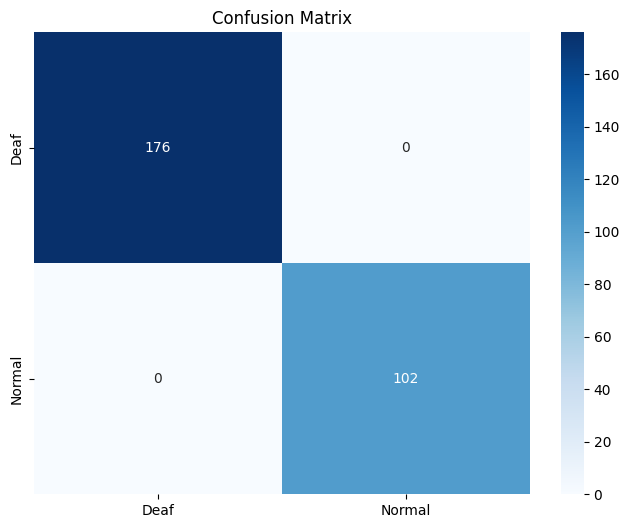

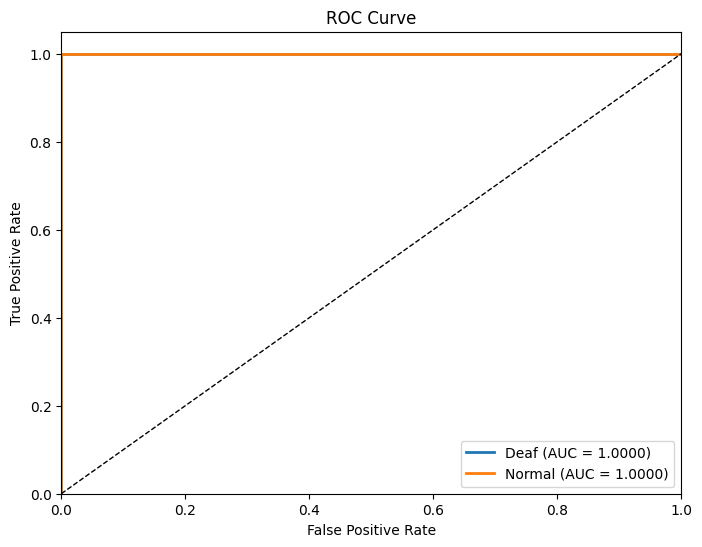


========== ROC-AUC Scores ==========
Deaf : 1.0000
Normal : 1.0000

--- Inference Performance ---
Latency : 5.51 ms/image
FPS     : 181.65

✅ Model saved as TinyCryViT_2Class_Final.h5


In [11]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FINAL)
# ============================================================

import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc
)
#from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-2class-DN/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# =========================================

# ================= TRANSFORMS =================
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ================= LOAD DATA =================
dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Detected classes: {CLASS_NAMES}")

# ================= EXACT CLASS-WISE 80:20 SPLIT =================
indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx, val_idx = [], []
for label, idxs in indices_by_class.items():
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
val_ds.dataset.transform = val_tf

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

# ================= MODEL =================
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(3, 192, 16, 16)

    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class TransformerBlock(nn.Module):
    def __init__(self, dim=192, heads=6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class TinyCryViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )
        self.bigru = nn.GRU(192, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.patch(x)
        x = self.blocks(x)
        _, h = self.bigru(x)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h)

model = TinyCryViT().to(DEVICE)

# ================= MODEL COMPLEXITY =================
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)

print("\n--- Model Complexity ---")
print(f"Total Params      : {params:,}")
print(f"Trainable Params  : {trainable:,}")
print(f"Non-Trainable     : {non_trainable:,}")
print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")

# ================= TRAINING =================
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

history = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    y_true, y_pred, y_score = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)
        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        # ✅ SAFE DETACH
        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        y_score.extend(torch.softmax(out, 1).detach().cpu().numpy())

    acc = correct / total
    return (
        total_loss / len(loader),
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


print("\n🚀 Training Started")
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(val_loader, False)
    scheduler.step()

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

# ================= OVERALL METRICS =================
overall_acc = accuracy_score(y_true, y_pred)
overall_prec, overall_rec, overall_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n--- Overall Metrics ---")
print(f"Accuracy : {overall_acc:.4f}")
print(f"Precision: {overall_prec:.4f}")
print(f"Recall   : {overall_rec:.4f}")
print(f"F1-score : {overall_f1:.4f}")

# ================= CLASS-WISE METRICS =================
class_prec, class_rec, class_f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

print("\n--- Class-wise Metrics ---")
for i, name in enumerate(CLASS_NAMES):
    class_acc = np.mean(y_pred[y_true == i] == i)
    print(f"\n{name}")
    print(f"  Accuracy : {class_acc:.4f}")
    print(f"  Precision: {class_prec[i]:.4f}")
    print(f"  Recall   : {class_rec[i]:.4f}")
    print(f"  F1-score : {class_f1[i]:.4f}")
    print(f"  Samples  : {support[i]}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ================= ROC CURVE (Binary Classification) =================

# Probability of positive class
'''positive_scores = y_score[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_true,
    positive_scores
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

print(f"\nROC-AUC Score: {roc_auc:.4f}")'''

# ================= ROC CURVE (2-CLASS) =================

# ================= ROC CURVE (2-CLASS) =================

from sklearn.metrics import roc_curve, auc

# Convert to numpy arrays
y_true = np.array(y_true)
y_score = np.array(y_score)

plt.figure(figsize=(8,6))

roc_auc = {}

# Plot ROC for each class
for i in range(NUM_CLASSES):

    # Create binary ground truth for current class
    y_true_binary = (y_true == i).astype(int)

    # Probability of current class
    y_score_binary = y_score[:, i]

    # ROC
    fpr, tpr, _ = roc_curve(y_true_binary, y_score_binary)
    roc_auc[i] = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{CLASS_NAMES[i]} (AUC = {roc_auc[i]:.4f})"
    )

# Random classifier
plt.plot([0,1],[0,1],'k--',linewidth=1)

plt.xlim([0,1])
plt.ylim([0,1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
#plt.grid(True)

plt.show()

print("\n========== ROC-AUC Scores ==========")
for i in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[i]} : {roc_auc[i]:.4f}")

# ================= LATENCY & FPS =================
model.eval()
start = time.time()
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)
end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n--- Inference Performance ---")
print(f"Latency : {latency*1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ================= SAVE MODEL (.h5) =================
torch.save(model.state_dict(), "TinyCryViT_2Class_Final.h5")
print("\n✅ Model saved as TinyCryViT_2Class_Final.h5")


Detected classes: ['Asphyxia', 'Hunger']
Train samples: 552 | Val samples: 138

--- Model Complexity ---
Total Params      : 1,318,018.0
Trainable Params  : 1,762,690
Non-Trainable     : 0
FLOPs             : 0.25 GFLOPs

🚀 Training Started
Epoch [1/50] | Train Acc: 0.7627 | Val Acc: 0.8986 | Train Loss: 0.5702 | Val Loss: 0.4146
Epoch [2/50] | Train Acc: 0.9438 | Val Acc: 0.9638 | Train Loss: 0.3410 | Val Loss: 0.2701
Epoch [3/50] | Train Acc: 0.9728 | Val Acc: 0.9710 | Train Loss: 0.2539 | Val Loss: 0.2446
Epoch [4/50] | Train Acc: 0.9710 | Val Acc: 0.9710 | Train Loss: 0.2461 | Val Loss: 0.2377
Epoch [5/50] | Train Acc: 0.9909 | Val Acc: 0.9783 | Train Loss: 0.2230 | Val Loss: 0.2325
Epoch [6/50] | Train Acc: 0.9982 | Val Acc: 0.9855 | Train Loss: 0.2172 | Val Loss: 0.2246
Epoch [7/50] | Train Acc: 1.0000 | Val Acc: 0.9783 | Train Loss: 0.2154 | Val Loss: 0.2228
Epoch [8/50] | Train Acc: 0.9982 | Val Acc: 0.9855 | Train Loss: 0.2116 | Val Loss: 0.2156
Epoch [9/50] | Train Acc: 1.000

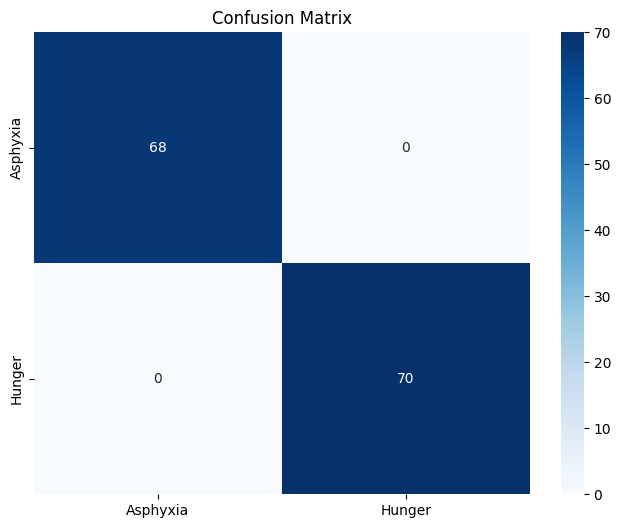

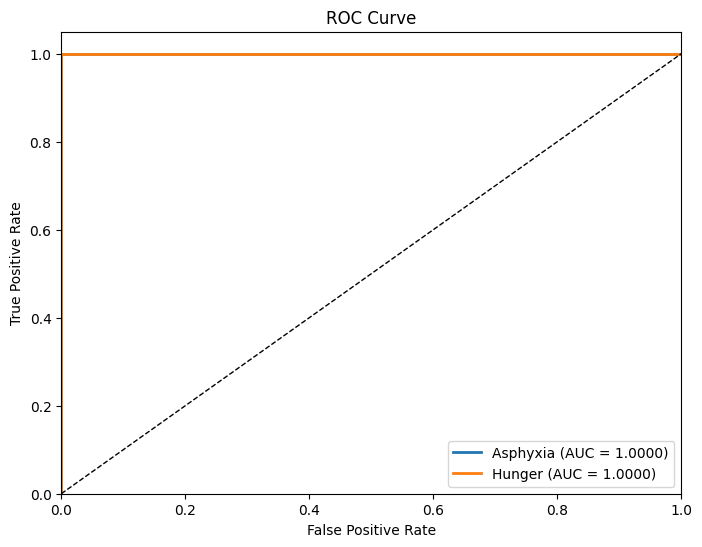


========== ROC-AUC Scores ==========
Asphyxia : 1.0000
Hunger : 1.0000

--- Inference Performance ---
Latency : 5.48 ms/image
FPS     : 182.44

✅ Model saved as TinyCryViT_2Class_Final.h5


In [13]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FINAL)
# ============================================================

import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc
)
#from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-2class/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# =========================================

# ================= TRANSFORMS =================
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ================= LOAD DATA =================
dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Detected classes: {CLASS_NAMES}")

# ================= EXACT CLASS-WISE 80:20 SPLIT =================
indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx, val_idx = [], []
for label, idxs in indices_by_class.items():
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
val_ds.dataset.transform = val_tf

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

# ================= MODEL =================
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(3, 192, 16, 16)

    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class TransformerBlock(nn.Module):
    def __init__(self, dim=192, heads=6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class TinyCryViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )
        self.bigru = nn.GRU(192, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.patch(x)
        x = self.blocks(x)
        _, h = self.bigru(x)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h)

model = TinyCryViT().to(DEVICE)

# ================= MODEL COMPLEXITY =================
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)

print("\n--- Model Complexity ---")
print(f"Total Params      : {params:,}")
print(f"Trainable Params  : {trainable:,}")
print(f"Non-Trainable     : {non_trainable:,}")
print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")

# ================= TRAINING =================
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

history = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    y_true, y_pred, y_score = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)
        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        # ✅ SAFE DETACH
        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        y_score.extend(torch.softmax(out, 1).detach().cpu().numpy())

    acc = correct / total
    return (
        total_loss / len(loader),
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


print("\n🚀 Training Started")
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(val_loader, False)
    scheduler.step()

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

# ================= OVERALL METRICS =================
overall_acc = accuracy_score(y_true, y_pred)
overall_prec, overall_rec, overall_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n--- Overall Metrics ---")
print(f"Accuracy : {overall_acc:.4f}")
print(f"Precision: {overall_prec:.4f}")
print(f"Recall   : {overall_rec:.4f}")
print(f"F1-score : {overall_f1:.4f}")

# ================= CLASS-WISE METRICS =================
class_prec, class_rec, class_f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

print("\n--- Class-wise Metrics ---")
for i, name in enumerate(CLASS_NAMES):
    class_acc = np.mean(y_pred[y_true == i] == i)
    print(f"\n{name}")
    print(f"  Accuracy : {class_acc:.4f}")
    print(f"  Precision: {class_prec[i]:.4f}")
    print(f"  Recall   : {class_rec[i]:.4f}")
    print(f"  F1-score : {class_f1[i]:.4f}")
    print(f"  Samples  : {support[i]}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ================= ROC CURVE (Binary Classification) =================

# Probability of positive class
'''positive_scores = y_score[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_true,
    positive_scores
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

print(f"\nROC-AUC Score: {roc_auc:.4f}")'''

# ================= ROC CURVE (2-CLASS) =================

# ================= ROC CURVE (2-CLASS) =================

from sklearn.metrics import roc_curve, auc

# Convert to numpy arrays
y_true = np.array(y_true)
y_score = np.array(y_score)

plt.figure(figsize=(8,6))

roc_auc = {}

# Plot ROC for each class
for i in range(NUM_CLASSES):

    # Create binary ground truth for current class
    y_true_binary = (y_true == i).astype(int)

    # Probability of current class
    y_score_binary = y_score[:, i]

    # ROC
    fpr, tpr, _ = roc_curve(y_true_binary, y_score_binary)
    roc_auc[i] = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{CLASS_NAMES[i]} (AUC = {roc_auc[i]:.4f})"
    )

# Random classifier
plt.plot([0,1],[0,1],'k--',linewidth=1)

plt.xlim([0,1])
plt.ylim([0,1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
#plt.grid(True)

plt.show()

print("\n========== ROC-AUC Scores ==========")
for i in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[i]} : {roc_auc[i]:.4f}")

# ================= LATENCY & FPS =================
model.eval()
start = time.time()
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)
end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n--- Inference Performance ---")
print(f"Latency : {latency*1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ================= SAVE MODEL (.h5) =================
torch.save(model.state_dict(), "TinyCryViT_2Class_Final.h5")
print("\n✅ Model saved as TinyCryViT_2Class_Final.h5")


Detected classes: ['Asphyxia', 'Deaf', 'Normal']
Train samples: 1380 | Val samples: 346

--- Model Complexity ---
Total Params      : 1,318,147.0
Trainable Params  : 1,762,819
Non-Trainable     : 0
FLOPs             : 0.25 GFLOPs

🚀 Training Started
Epoch [1/50] | Train Acc: 0.8152 | Val Acc: 0.9220 | Train Loss: 0.6528 | Val Loss: 0.4783
Epoch [2/50] | Train Acc: 0.9348 | Val Acc: 0.9595 | Train Loss: 0.4354 | Val Loss: 0.3766
Epoch [3/50] | Train Acc: 0.9486 | Val Acc: 0.9306 | Train Loss: 0.3928 | Val Loss: 0.4156
Epoch [4/50] | Train Acc: 0.9565 | Val Acc: 0.9451 | Train Loss: 0.3719 | Val Loss: 0.4027
Epoch [5/50] | Train Acc: 0.9543 | Val Acc: 0.9451 | Train Loss: 0.3810 | Val Loss: 0.4074
Epoch [6/50] | Train Acc: 0.9616 | Val Acc: 0.9653 | Train Loss: 0.3665 | Val Loss: 0.3565
Epoch [7/50] | Train Acc: 0.9674 | Val Acc: 0.9653 | Train Loss: 0.3561 | Val Loss: 0.3527
Epoch [8/50] | Train Acc: 0.9688 | Val Acc: 0.9653 | Train Loss: 0.3558 | Val Loss: 0.3656
Epoch [9/50] | Train A

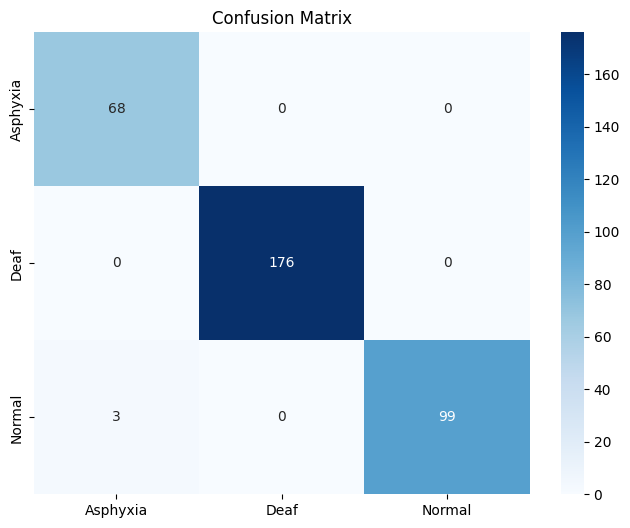

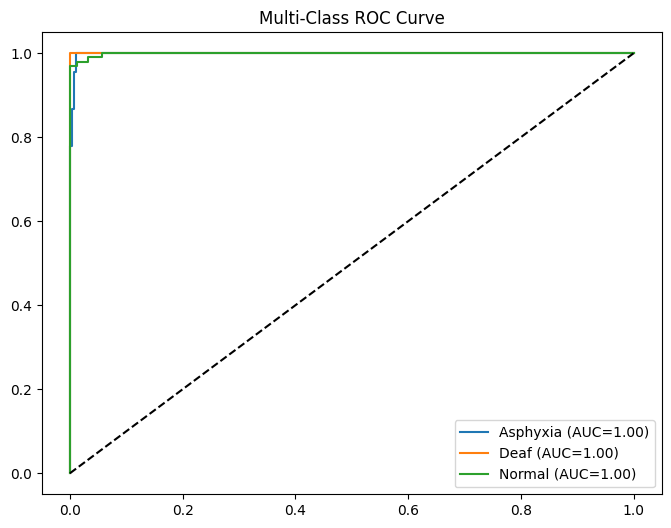


--- Inference Performance ---
Latency : 5.61 ms/image
FPS     : 178.19

✅ Model saved as TinyCryViT_3Class_Final.h5


In [14]:
# ============================================================
# TinyCryViT – Baby Chillanto RGB Classification (FINAL)
# ============================================================

import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile

# ================= CONFIG =================
DATA_ROOT = "/workspace/work2-3class/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# =========================================

# ================= TRANSFORMS =================
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# ================= LOAD DATA =================
dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
CLASS_NAMES = dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Detected classes: {CLASS_NAMES}")

# ================= EXACT CLASS-WISE 80:20 SPLIT =================
indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.targets):
    indices_by_class[label].append(idx)

train_idx, val_idx = [], []
for label, idxs in indices_by_class.items():
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
val_ds.dataset.transform = val_tf

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

# ================= MODEL =================
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(3, 192, 16, 16)

    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class TransformerBlock(nn.Module):
    def __init__(self, dim=192, heads=6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class TinyCryViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(
            TransformerBlock(),
            TransformerBlock(),
            TransformerBlock()
        )
        self.bigru = nn.GRU(192, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.patch(x)
        x = self.blocks(x)
        _, h = self.bigru(x)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h)

model = TinyCryViT().to(DEVICE)

# ================= MODEL COMPLEXITY =================
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
flops, params = profile(model, inputs=(dummy,), verbose=False)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)

print("\n--- Model Complexity ---")
print(f"Total Params      : {params:,}")
print(f"Trainable Params  : {trainable:,}")
print(f"Non-Trainable     : {non_trainable:,}")
print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")

# ================= TRAINING =================
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

history = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    y_true, y_pred, y_score = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if train:
            optimizer.zero_grad()

        out = model(x)
        loss = criterion(out, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        # ✅ SAFE DETACH
        y_true.extend(y.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        y_score.extend(torch.softmax(out, 1).detach().cpu().numpy())

    acc = correct / total
    return (
        total_loss / len(loader),
        acc,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


print("\n🚀 Training Started")
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(val_loader, False)
    scheduler.step()

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f} | "
          f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

# ================= OVERALL METRICS =================
overall_acc = accuracy_score(y_true, y_pred)
overall_prec, overall_rec, overall_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n--- Overall Metrics ---")
print(f"Accuracy : {overall_acc:.4f}")
print(f"Precision: {overall_prec:.4f}")
print(f"Recall   : {overall_rec:.4f}")
print(f"F1-score : {overall_f1:.4f}")

# ================= CLASS-WISE METRICS =================
class_prec, class_rec, class_f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

print("\n--- Class-wise Metrics ---")
for i, name in enumerate(CLASS_NAMES):
    class_acc = np.mean(y_pred[y_true == i] == i)
    print(f"\n{name}")
    print(f"  Accuracy : {class_acc:.4f}")
    print(f"  Precision: {class_prec[i]:.4f}")
    print(f"  Recall   : {class_rec[i]:.4f}")
    print(f"  F1-score : {class_f1[i]:.4f}")
    print(f"  Samples  : {support[i]}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ================= ROC CURVE =================
y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
plt.figure(figsize=(8,6))
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={auc(fpr,tpr):.2f})")
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("Multi-Class ROC Curve")
plt.show()

# ================= LATENCY & FPS =================
model.eval()
start = time.time()
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy)
end = time.time()

latency = (end-start)/30
fps = 1/latency

print("\n--- Inference Performance ---")
print(f"Latency : {latency*1000:.2f} ms/image")
print(f"FPS     : {fps:.2f}")

# ================= SAVE MODEL (.h5) =================
torch.save(model.state_dict(), "TinyCryViT_3Class_Final.h5")
print("\n✅ Model saved as TinyCryViT_3Class_Final.h5")


In [2]:
pip install thop

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 23.3.2 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
pip install seaborn

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 4.1 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 23.3.2 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
pip install psutil

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 23.3.2 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
RGB Fusion + classifier without Tiny-ViT/GRU

Device: cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']

Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

================ MODEL ================
RGBFusionClassifier(
  (rgb_fusion): RGBFusion(
    (red_branch): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU(inplace=True)
    )
    (green_branch): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool

Epoch [48/50] | Train Acc: 0.9530 | Val Acc: 0.9639 | Train Loss: 0.4857 | Val Loss: 0.4387 | Epoch Time: 22.50 sec
Epoch [49/50] | Train Acc: 0.9542 | Val Acc: 0.9591 | Train Loss: 0.4851 | Val Loss: 0.4418 | Epoch Time: 22.51 sec
Epoch [50/50] | Train Acc: 0.9608 | Val Acc: 0.9615 | Train Loss: 0.4759 | Val Loss: 0.4416 | Epoch Time: 22.58 sec

================ OVERALL METRICS ================
Accuracy      : 0.9615
Precision     : 0.9477
Recall        : 0.9583
F1-Score      : 0.9513
Standard Dev  : 0.1923
RMSE          : 0.4804

================ CLASSWISE METRICS ================

Class : Asphyxia
Accuracy      : 0.9706
Precision     : 0.8919
Recall        : 0.9706
F1-Score      : 0.9296
Standard Dev  : 0.1690
RMSE          : 0.5145
Samples       : 68

Class : Deaf
Accuracy      : 1.0000
Precision     : 1.0000
Recall        : 1.0000
F1-Score      : 1.0000
Standard Dev  : 0.0000
RMSE          : 0.0000
Samples       : 176

Class : Hunger
Accuracy      : 1.0000
Precision     : 0.9211
R

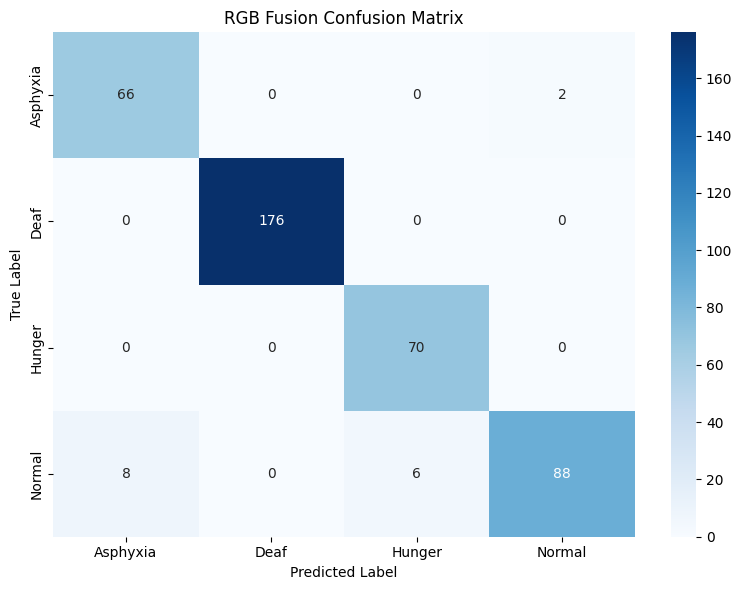

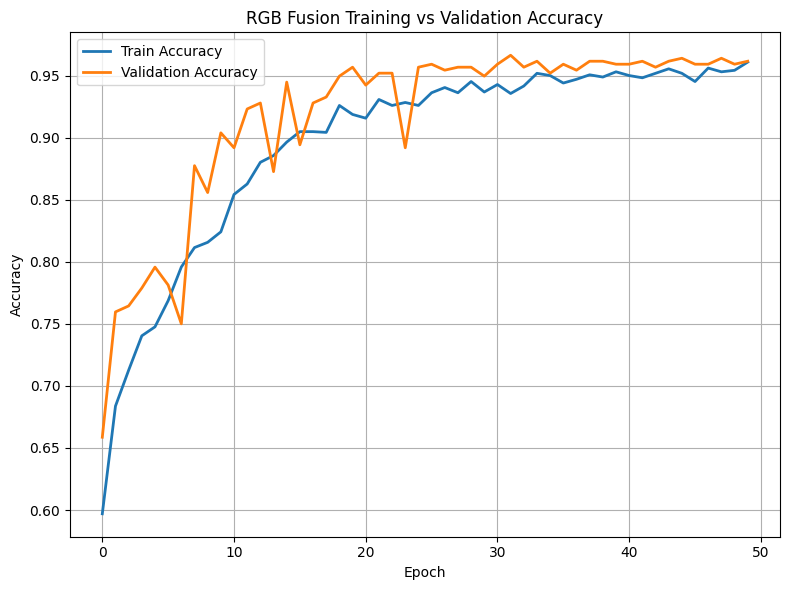

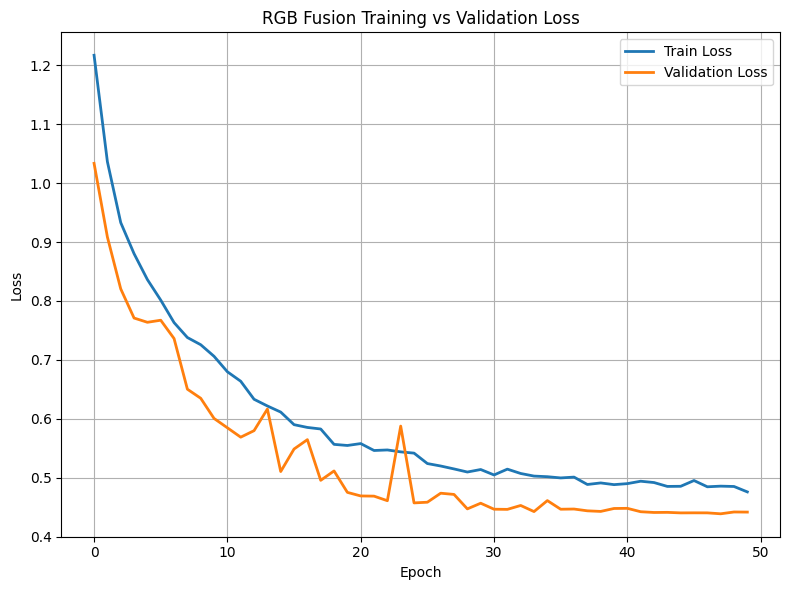

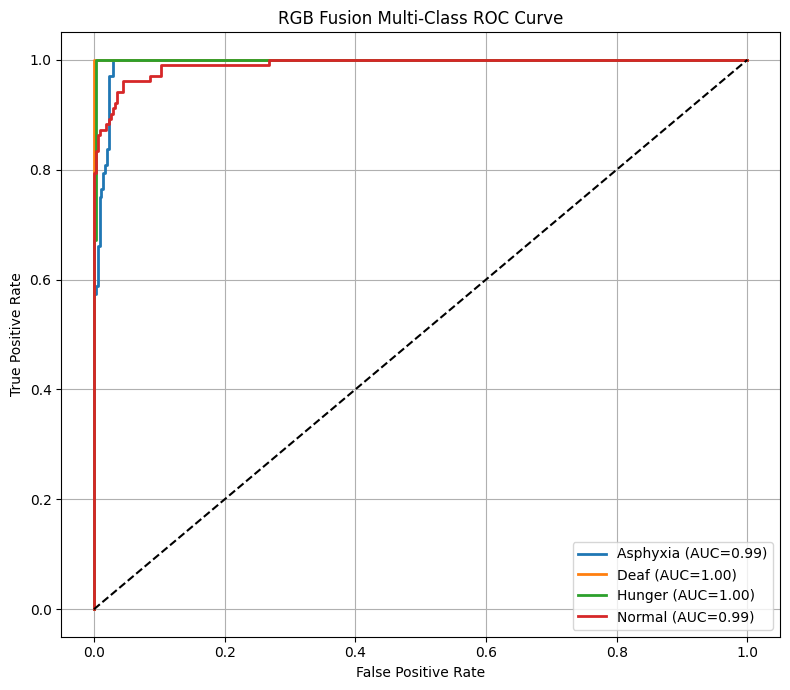


================ INFERENCE PERFORMANCE ================
Latency : 2.13 ms/image
FPS     : 469.47

================ TRAINING TIME ================
Epoch 01 : 22.80 sec
Epoch 02 : 22.56 sec
Epoch 03 : 22.59 sec
Epoch 04 : 22.62 sec
Epoch 05 : 22.65 sec
Epoch 06 : 22.53 sec
Epoch 07 : 22.57 sec
Epoch 08 : 22.58 sec
Epoch 09 : 22.56 sec
Epoch 10 : 22.63 sec
Epoch 11 : 22.64 sec
Epoch 12 : 22.56 sec
Epoch 13 : 22.50 sec
Epoch 14 : 22.48 sec
Epoch 15 : 22.55 sec
Epoch 16 : 22.61 sec
Epoch 17 : 22.57 sec
Epoch 18 : 22.57 sec
Epoch 19 : 22.57 sec
Epoch 20 : 22.47 sec
Epoch 21 : 22.61 sec
Epoch 22 : 22.51 sec
Epoch 23 : 22.55 sec
Epoch 24 : 22.56 sec
Epoch 25 : 22.69 sec
Epoch 26 : 22.51 sec
Epoch 27 : 22.49 sec
Epoch 28 : 22.62 sec
Epoch 29 : 22.48 sec
Epoch 30 : 22.59 sec
Epoch 31 : 22.59 sec
Epoch 32 : 22.50 sec
Epoch 33 : 22.59 sec
Epoch 34 : 22.55 sec
Epoch 35 : 22.51 sec
Epoch 36 : 22.53 sec
Epoch 37 : 22.61 sec
Epoch 38 : 22.53 sec
Epoch 39 : 22.54 sec
Epoch 40 : 22.64 sec
Epoch 41 : 22

In [21]:
# ============================================================
# RGB Fusion + Classifier – Baby Chillanto RGB Classification
# ============================================================

import os
import time
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize
from collections import defaultdict
from thop import profile


# ============================================================
# CONFIG
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================
# IMPORTANT:
# Create TWO ImageFolder objects so that changing the validation
# transform does not also change the training transform.

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)

CLASS_NAMES = train_dataset_full.classes
NUM_CLASSES = len(CLASS_NAMES)

print("\nDetected Classes:")
print(CLASS_NAMES)

print("\nNumber of Classes:", NUM_CLASSES)


# ============================================================
# EXACT CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(train_dataset_full.targets):

    indices_by_class[label].append(idx)


train_idx = []
val_idx = []

for label, idxs in indices_by_class.items():

    idxs = np.array(idxs)

    np.random.shuffle(idxs)

    split = int(0.8 * len(idxs))

    train_idx.extend(
        idxs[:split].tolist()
    )

    val_idx.extend(
        idxs[split:].tolist()
    )


train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("\nTrain Samples      :", len(train_ds))
print("Validation Samples :", len(val_ds))


# ============================================================
# RGB FUSION MODULE
# ============================================================

class RGBFusion(nn.Module):

    def __init__(self):

        super().__init__()

        # ----------------------------------------------------
        # RED CHANNEL BRANCH
        # ----------------------------------------------------

        self.red_branch = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                stride=1,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True)
        )


        # ----------------------------------------------------
        # GREEN CHANNEL BRANCH
        # ----------------------------------------------------

        self.green_branch = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                stride=1,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True)
        )


        # ----------------------------------------------------
        # BLUE CHANNEL BRANCH
        # ----------------------------------------------------

        self.blue_branch = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                stride=1,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True)
        )


        # ----------------------------------------------------
        # RGB FEATURE FUSION
        # ----------------------------------------------------
        # 64 + 64 + 64 = 192 channels

        self.fusion = nn.Sequential(

            nn.Conv2d(
                192,
                128,
                kernel_size=3,
                stride=1,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                stride=1,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(inplace=True)
        )


        # ----------------------------------------------------
        # GLOBAL FEATURE EXTRACTION
        # ----------------------------------------------------

        self.global_pool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )


    def forward(self, x):

        # ----------------------------------------------------
        # Separate RGB channels
        # ----------------------------------------------------

        r = x[:, 0:1, :, :]
        g = x[:, 1:2, :, :]
        b = x[:, 2:3, :, :]


        # ----------------------------------------------------
        # Extract channel-specific features
        # ----------------------------------------------------

        r_features = self.red_branch(r)

        g_features = self.green_branch(g)

        b_features = self.blue_branch(b)


        # ----------------------------------------------------
        # RGB FEATURE FUSION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                r_features,
                g_features,
                b_features
            ],
            dim=1
        )


        fused = self.fusion(fused)


        # ----------------------------------------------------
        # GLOBAL AVERAGE POOLING
        # ----------------------------------------------------

        fused = self.global_pool(fused)


        # ----------------------------------------------------
        # Flatten
        # ----------------------------------------------------

        fused = torch.flatten(
            fused,
            start_dim=1
        )


        return fused


# ============================================================
# RGB FUSION CLASSIFIER
# ============================================================

class RGBFusionClassifier(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.rgb_fusion = RGBFusion()


        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                128,
                128
            ),

            nn.ReLU(inplace=True),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(self, x):

        features = self.rgb_fusion(x)

        output = self.classifier(features)

        return output


# ============================================================
# CREATE MODEL
# ============================================================

model = RGBFusionClassifier(
    num_classes=NUM_CLASSES
).to(DEVICE)


print("\n================ MODEL ================")

print(model)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

dummy = torch.randn(
    1,
    3,
    IMG_SIZE,
    IMG_SIZE
).to(DEVICE)


model.eval()

flops, params = profile(
    model,
    inputs=(dummy,),
    verbose=False
)


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


non_trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_path = "temp_rgb_fusion_model.pth"

torch.save(
    model.state_dict(),
    temp_model_path
)

model_size_mb = (
    os.path.getsize(temp_model_path)
    / (1024 * 1024)
)


# ============================================================
# PRINT COMPLEXITY
# ============================================================

print("\n================ MODEL COMPLEXITY ================")

print(
    f"Total Parameters         : {params:,}"
)

print(
    f"Trainable Parameters     : {trainable_params:,}"
)

print(
    f"Non-Trainable Parameters : {non_trainable_params:,}"
)

print(
    f"FLOPs                    : {flops / 1e9:.4f} GFLOPs"
)

print(
    f"Model Size               : {model_size_mb:.2f} MB"
)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)


# ============================================================
# LR SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)


# ============================================================
# HISTORY
# ============================================================

history = {

    "train_acc": [],

    "val_acc": [],

    "train_loss": [],

    "val_loss": [],

    "epoch_time": []
}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(loader, train=True):

    if train:

        model.train()

    else:

        model.eval()


    total_loss = 0.0

    correct = 0

    total = 0


    y_true = []

    y_pred = []

    y_score = []


    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )


        if train:

            optimizer.zero_grad(
                set_to_none=True
            )


        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        with torch.set_grad_enabled(train):

            out = model(x)

            loss = criterion(
                out,
                y
            )


            if train:

                loss.backward()

                optimizer.step()


        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        total_loss += loss.item()


        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        preds = out.argmax(
            dim=1
        )


        correct += (
            preds == y
        ).sum().item()


        total += y.size(0)


        # ----------------------------------------------------
        # Store predictions
        # ----------------------------------------------------

        y_true.extend(
            y.detach()
            .cpu()
            .numpy()
        )


        y_pred.extend(
            preds.detach()
            .cpu()
            .numpy()
        )


        probabilities = torch.softmax(
            out,
            dim=1
        )


        y_score.extend(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )


    avg_loss = (
        total_loss
        / len(loader)
    )


    acc = (
        correct
        / total
    )


    return (

        avg_loss,

        acc,

        np.array(y_true),

        np.array(y_pred),

        np.array(y_score)

    )


# ============================================================
# TRAINING
# ============================================================

print("\n🚀 RGB FUSION TRAINING STARTED 🚀")


training_start = time.time()


for epoch in range(EPOCHS):

    epoch_start = time.time()


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    tr_loss, tr_acc, _, _, _ = run_epoch(
        train_loader,
        train=True
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_acc, y_true, y_pred, y_score = run_epoch(
        val_loader,
        train=False
    )


    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step()


    epoch_end = time.time()


    epoch_time = (
        epoch_end
        - epoch_start
    )


    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history["train_acc"].append(
        tr_acc
    )

    history["val_acc"].append(
        val_acc
    )

    history["train_loss"].append(
        tr_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["epoch_time"].append(
        epoch_time
    )


    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Acc: {tr_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Train Loss: {tr_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Epoch Time: {epoch_time:.2f} sec"
    )


# ============================================================
# TOTAL TRAINING TIME
# ============================================================

training_end = time.time()


total_training_time = (
    training_end
    - training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(
    y_true,
    y_pred
)


overall_prec, overall_rec, overall_f1, _ = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


# ------------------------------------------------------------
# Prediction correctness standard deviation
# ------------------------------------------------------------

overall_std = np.std(
    y_pred == y_true
)


# ------------------------------------------------------------
# RMSE
# ------------------------------------------------------------

overall_rmse = math.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)


print(
    "\n================ OVERALL METRICS ================"
)


print(
    f"Accuracy      : {overall_acc:.4f}"
)

print(
    f"Precision     : {overall_prec:.4f}"
)

print(
    f"Recall        : {overall_rec:.4f}"
)

print(
    f"F1-Score      : {overall_f1:.4f}"
)

print(
    f"Standard Dev  : {overall_std:.4f}"
)

print(
    f"RMSE          : {overall_rmse:.4f}"
)


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average=None,
        zero_division=0
    )


print(
    "\n================ CLASSWISE METRICS ================"
)


for i, name in enumerate(CLASS_NAMES):

    idx = (
        y_true == i
    )


    # --------------------------------------------------------
    # Class accuracy
    # --------------------------------------------------------

    if np.sum(idx) > 0:

        class_acc = np.mean(
            y_pred[idx] == i
        )

        class_std = np.std(
            y_pred[idx] == i
        )

        class_rmse = math.sqrt(
            mean_squared_error(
                y_true[idx],
                y_pred[idx]
            )
        )

    else:

        class_acc = 0.0

        class_std = 0.0

        class_rmse = 0.0


    print(
        f"\nClass : {name}"
    )


    print(
        f"Accuracy      : {class_acc:.4f}"
    )

    print(
        f"Precision     : {class_prec[i]:.4f}"
    )

    print(
        f"Recall        : {class_rec[i]:.4f}"
    )

    print(
        f"F1-Score      : {class_f1[i]:.4f}"
    )

    print(
        f"Standard Dev  : {class_std:.4f}"
    )

    print(
        f"RMSE          : {class_rmse:.4f}"
    )

    print(
        f"Samples       : {support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


print(
    "\n================ CONFUSION MATRIX ================"
)

print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "RGB Fusion Confusion Matrix"
)

plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(
    history["train_acc"],
    label="Train Accuracy",
    linewidth=2
)


plt.plot(
    history["val_acc"],
    label="Validation Accuracy",
    linewidth=2
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "RGB Fusion Training vs Validation Accuracy"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(
    history["train_loss"],
    label="Train Loss",
    linewidth=2
)


plt.plot(
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "RGB Fusion Training vs Validation Loss"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(
    y_true,
    classes=np.arange(NUM_CLASSES)
)


plt.figure(
    figsize=(8, 7)
)


for i in range(NUM_CLASSES):

    # --------------------------------------------------------
    # Handle binary case
    # --------------------------------------------------------

    if NUM_CLASSES == 2:

        if y_bin.ndim == 1:

            target = y_bin

        elif y_bin.shape[1] == 1:

            target = y_bin[:, 0]

        else:

            target = y_bin[:, i]

    else:

        target = y_bin[:, i]


    fpr, tpr, _ = roc_curve(
        target,
        y_score[:, i]
    )


    roc_auc = auc(
        fpr,
        tpr
    )


    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"
        )
    )


plt.plot(
    [0, 1],
    [0, 1],
    "k--"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "RGB Fusion Multi-Class ROC Curve"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LATENCY & FPS
# ============================================================

model.eval()


# ------------------------------------------------------------
# Warm-up
# ------------------------------------------------------------

with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


# ------------------------------------------------------------
# Synchronize GPU before timing
# ------------------------------------------------------------

if DEVICE == "cuda":

    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


end = time.time()


latency = (
    end - start
) / 30


fps = 1 / latency


print(
    "\n================ INFERENCE PERFORMANCE ================"
)


print(
    f"Latency : {latency * 1000:.2f} ms/image"
)

print(
    f"FPS     : {fps:.2f}"
)


# ============================================================
# TRAINING TIME
# ============================================================

print(
    "\n================ TRAINING TIME ================"
)


for i, t in enumerate(
    history["epoch_time"]
):

    print(
        f"Epoch {i + 1:02d} : {t:.2f} sec"
    )


print(
    f"\nTotal Training Time : "
    f"{total_training_time:.2f} sec"
)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_PATH = (
    "RGBFusion_Classifier_Final.pth"
)


torch.save(
    model.state_dict(),
    MODEL_PATH
)


print(
    f"\n✅ RGB Fusion model saved as "
    f"{MODEL_PATH}"
)


# ============================================================
# DELETE TEMP MODEL
# ============================================================

if os.path.exists(
    temp_model_path
):

    os.remove(
        temp_model_path
    )


print(
    "\n✅ RGB Fusion + Classifier pipeline completed."
)


TinyCryViT Configuration
Embedding Dimension : 96
Attention Heads     : 3
Transformer Blocks  : 3
GRU Hidden Dimension: 128
Device              : cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

Model created successfully.

MODEL COMPLEXITY
Embedding Dimension     : 96
Attention Heads         : 3
Transformer Blocks      : 3
GRU Hidden Dimension    : 128
Total Parameters        : 616324
Trainable Parameters    : 616324
Non-Trainable Parameters: 0
GFLOPs                  : 0.0927
Model Size              : 2.37 MB

TRAINING STARTED
Epoch [1/50] | Train Acc: 0.6006 | Val Acc: 0.7139 | Train Loss: 1.1017 | Val Loss: 0.8666 | Time: 22.54 sec
Epoch [2/50] | Train Acc: 0.6825 | Val Acc: 0.6923 | Train Loss: 0.8945 | Val Loss: 0.8175 | Time: 22.57 sec
Epoch [3/50] | Train Acc: 0.7325 | Val Acc: 0.6947 | Train Loss: 0.8121 | Val Loss: 0.8054 | Time: 22.61 sec
Epoch [4/50] | Train Acc: 0.7620 | Val Acc: 0.77

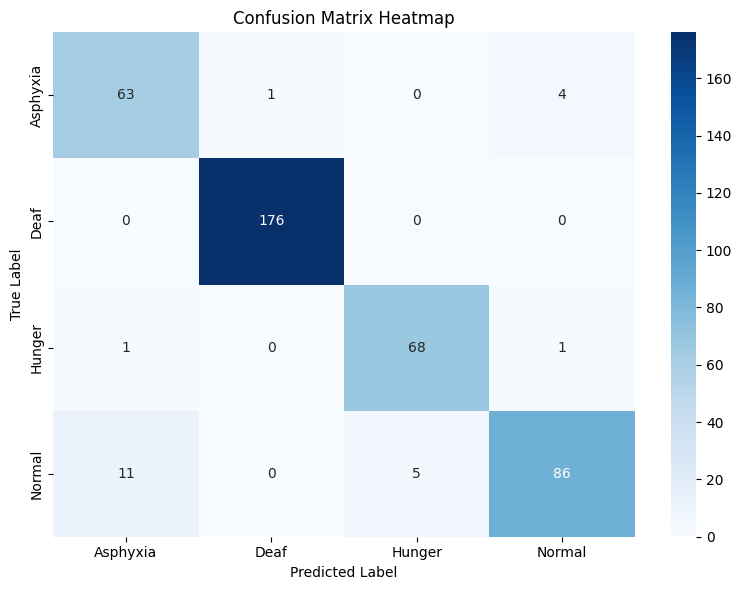

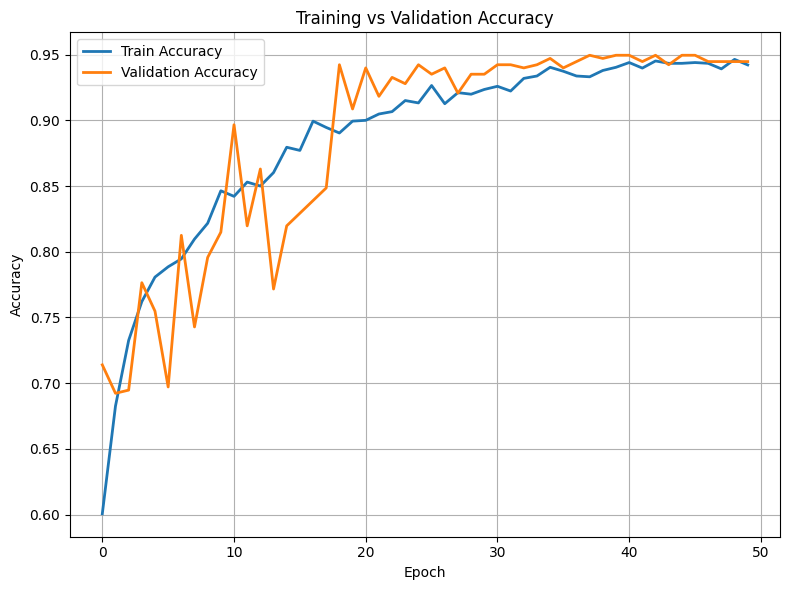

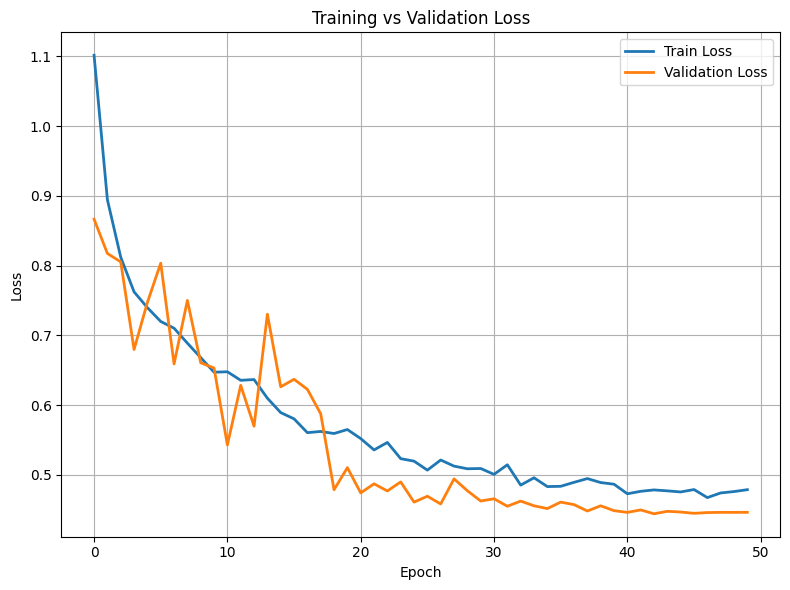

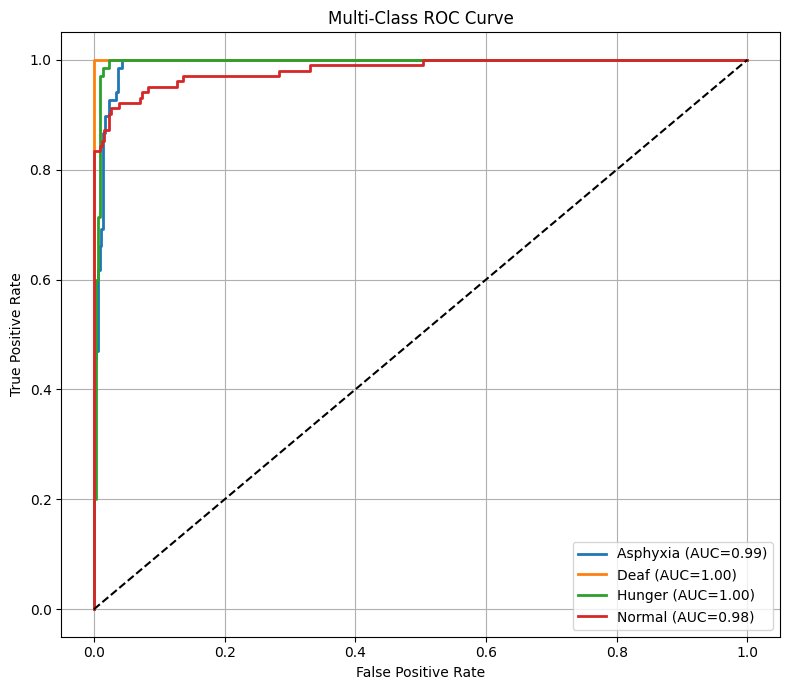


INFERENCE PERFORMANCE
Latency : 4.67 ms/image
FPS     : 214.02

MODEL SAVED
File: TinyCryViT_E96_H3_B3_GRU128.pth

ABLATION SUMMARY
Embedding Dimension : 96
Attention Heads     : 3
Transformer Blocks  : 3
GRU Hidden Dimension: 128
Accuracy            : 94.47%
Parameters          : 616,324
GFLOPs              : 0.0927


In [31]:
# ============================================================
# TinyCryViT - Baby Chillanto RGB Classification
# Ablation Configuration
#
# Embedding Dimension = 96
# Attention Heads     = 3
# Transformer Blocks  = 3
# GRU Hidden Dimension= 128
# ============================================================

import os
import time
import math
import random

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize

from collections import defaultdict

from thop import profile


# ============================================================
# CONFIGURATION
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# TinyCryViT ablation configuration
EMBED_DIM = 96
NUM_HEADS = 3
NUM_BLOCKS = 3
GRU_HIDDEN = 128

print("==============================================")
print("TinyCryViT Configuration")
print("==============================================")
print("Embedding Dimension :", EMBED_DIM)
print("Attention Heads     :", NUM_HEADS)
print("Transformer Blocks  :", NUM_BLOCKS)
print("GRU Hidden Dimension:", GRU_HIDDEN)
print("Device              :", DEVICE)
print("==============================================")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)

CLASS_NAMES = train_dataset_full.classes
NUM_CLASSES = len(CLASS_NAMES)

print("\nDetected Classes:")
print(CLASS_NAMES)

print("Number of Classes:", NUM_CLASSES)


# ============================================================
# CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(train_dataset_full.targets):
    indices_by_class[label].append(idx)


train_idx = []
val_idx = []


for label, idxs in indices_by_class.items():

    idxs = idxs.copy()

    np.random.shuffle(idxs)

    split = int(0.8 * len(idxs))

    train_idx.extend(idxs[:split])
    val_idx.extend(idxs[split:])


# ============================================================
# DATASET SUBSETS
# ============================================================

train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("\nTrain Samples      :", len(train_ds))
print("Validation Samples :", len(val_ds))


# ============================================================
# PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(self, embed_dim=96):
        super().__init__()

        self.proj = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=16,
            stride=16
        )

    def forward(self, x):

        x = self.proj(x)

        # [B, 96, 14, 14]

        x = x.flatten(2)

        # [B, 96, 196]

        x = x.transpose(1, 2)

        # [B, 196, 96]

        return x


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self, dim=96, heads=3):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)

        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=heads,
            batch_first=True
        )

        self.norm2 = nn.LayerNorm(dim)

        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):

        normalized_x = self.norm1(x)

        attn_output, _ = self.attn(
            normalized_x,
            normalized_x,
            normalized_x
        )

        x = x + attn_output

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ============================================================
# TinyCryViT
# ============================================================

class TinyCryViT(nn.Module):

    def __init__(
        self,
        embed_dim=96,
        num_blocks=3,
        num_heads=3,
        gru_hidden=128,
        num_classes=NUM_CLASSES
    ):

        super().__init__()

        # Patch embedding
        self.patch = PatchEmbedding(
            embed_dim=embed_dim
        )

        # Transformer blocks
        transformer_layers = []

        for _ in range(num_blocks):

            transformer_layers.append(
                TransformerBlock(
                    dim=embed_dim,
                    heads=num_heads
                )
            )

        self.blocks = nn.Sequential(
            *transformer_layers
        )

        # Bidirectional GRU
        self.bigru = nn.GRU(
            input_size=embed_dim,
            hidden_size=gru_hidden,
            bidirectional=True,
            batch_first=True
        )

        # Classification head
        self.fc = nn.Sequential(

            nn.Linear(
                gru_hidden * 2,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        x = self.patch(x)

        x = self.blocks(x)

        _, h = self.bigru(x)

        # Forward and backward hidden states
        h = torch.cat(
            [h[-2], h[-1]],
            dim=1
        )

        out = self.fc(h)

        return out


# ============================================================
# CREATE MODEL
# ============================================================

model = TinyCryViT(
    embed_dim=EMBED_DIM,
    num_blocks=NUM_BLOCKS,
    num_heads=NUM_HEADS,
    gru_hidden=GRU_HIDDEN,
    num_classes=NUM_CLASSES
).to(DEVICE)


print("\nModel created successfully.")


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = (
    total_params - trainable_params
)


# ============================================================
# GFLOPs
# ============================================================

dummy = torch.randn(
    1,
    3,
    IMG_SIZE,
    IMG_SIZE
).to(DEVICE)

model.eval()

flops, params = profile(
    model,
    inputs=(dummy,),
    verbose=False
)

gflops = flops / 1e9


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_file = "temp_model.pth"

torch.save(
    model.state_dict(),
    temp_model_file
)

model_size_mb = (
    os.path.getsize(temp_model_file)
    / (1024 * 1024)
)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

print("\n==============================================")
print("MODEL COMPLEXITY")
print("==============================================")

print(
    "Embedding Dimension     :",
    EMBED_DIM
)

print(
    "Attention Heads         :",
    NUM_HEADS
)

print(
    "Transformer Blocks      :",
    NUM_BLOCKS
)

print(
    "GRU Hidden Dimension    :",
    GRU_HIDDEN
)

print(
    "Total Parameters        :",
    total_params
)

print(
    "Trainable Parameters    :",
    trainable_params
)

print(
    "Non-Trainable Parameters:",
    non_trainable_params
)

print(
    "GFLOPs                  :",
    f"{gflops:.4f}"
)

print(
    "Model Size              :",
    f"{model_size_mb:.2f} MB"
)

print("==============================================")


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)


# ============================================================
# SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)


# ============================================================
# HISTORY
# ============================================================

history = {
    "train_acc": [],
    "val_acc": [],
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(loader, train=True):

    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    y_true = []
    y_pred = []
    y_score = []

    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):

            out = model(x)

            loss = criterion(
                out,
                y
            )

            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item()

        preds = out.argmax(dim=1)

        correct += (
            preds == y
        ).sum().item()

        total += y.size(0)

        y_true.extend(
            y.detach().cpu().numpy()
        )

        y_pred.extend(
            preds.detach().cpu().numpy()
        )

        probabilities = torch.softmax(
            out,
            dim=1
        )

        y_score.extend(
            probabilities.detach()
            .cpu()
            .numpy()
        )

    avg_loss = total_loss / len(loader)

    accuracy = correct / total

    return (
        avg_loss,
        accuracy,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


# ============================================================
# TRAINING
# ============================================================

print("\n==============================================")
print("TRAINING STARTED")
print("==============================================")


training_start = time.time()


for epoch in range(EPOCHS):

    epoch_start = time.time()

    (
        train_loss,
        train_acc,
        _,
        _,
        _
    ) = run_epoch(
        train_loader,
        train=True
    )

    (
        val_loss,
        val_acc,
        y_true,
        y_pred,
        y_score
    ) = run_epoch(
        val_loader,
        train=False
    )

    scheduler.step()

    epoch_time = (
        time.time() - epoch_start
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_acc"].append(
        val_acc
    )

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["epoch_time"].append(
        epoch_time
    )

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {epoch_time:.2f} sec"
    )


training_end = time.time()

total_training_time = (
    training_end - training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(
    y_true,
    y_pred
)

overall_prec, overall_rec, overall_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

overall_std = np.std(
    y_pred == y_true
)

overall_rmse = math.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")

print(
    f"Embedding Dimension : {EMBED_DIM}"
)

print(
    f"Attention Heads     : {NUM_HEADS}"
)

print(
    f"Transformer Blocks  : {NUM_BLOCKS}"
)

print(
    f"GRU Hidden Dimension: {GRU_HIDDEN}"
)

print(
    f"Accuracy            : {overall_acc:.4f}"
)

print(
    f"Accuracy (%)        : {overall_acc * 100:.2f}%"
)

print(
    f"Precision           : {overall_prec:.4f}"
)

print(
    f"Recall              : {overall_rec:.4f}"
)

print(
    f"F1-Score            : {overall_f1:.4f}"
)

print(
    f"Standard Deviation  : {overall_std:.4f}"
)

print(
    f"RMSE               : {overall_rmse:.4f}"
)

print(
    f"Total Parameters    : {total_params:,}"
)

print(
    f"Trainable Parameters: {trainable_params:,}"
)

print(
    f"GFLOPs              : {gflops:.4f}"
)

print(
    f"Model Size          : {model_size_mb:.2f} MB"
)

print(
    f"Training Time       : {total_training_time:.2f} sec"
)

print("==============================================")


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average=None,
        zero_division=0
    )
)


print("\n==============================================")
print("CLASSWISE METRICS")
print("==============================================")


for i, name in enumerate(CLASS_NAMES):

    idx = (
        y_true == i
    )

    class_acc = np.mean(
        y_pred[idx] == i
    )

    class_std = np.std(
        y_pred[idx] == i
    )

    class_rmse = math.sqrt(
        mean_squared_error(
            y_true[idx],
            y_pred[idx]
        )
    )

    print(
        f"\nClass: {name}"
    )

    print(
        f"Accuracy     : {class_acc:.4f}"
    )

    print(
        f"Precision    : {class_prec[i]:.4f}"
    )

    print(
        f"Recall       : {class_rec[i]:.4f}"
    )

    print(
        f"F1-Score     : {class_f1[i]:.4f}"
    )

    print(
        f"Standard Dev : {class_std:.4f}"
    )

    print(
        f"RMSE         : {class_rmse:.4f}"
    )

    print(
        f"Samples      : {support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")

print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(
    figsize=(8, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix Heatmap")

plt.tight_layout()
plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    history["train_acc"],
    label="Train Accuracy",
    linewidth=2
)

plt.plot(
    history["val_acc"],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    history["train_loss"],
    label="Train Loss",
    linewidth=2
)

plt.plot(
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training vs Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(
    y_true,
    classes=range(NUM_CLASSES)
)

plt.figure(
    figsize=(8, 7)
)


for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"
        )
    )


plt.plot(
    [0, 1],
    [0, 1],
    "k--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Multi-Class ROC Curve"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# INFERENCE LATENCY
# ============================================================

model.eval()


# Warm-up
with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


if DEVICE == "cuda":
    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":
    torch.cuda.synchronize()


end = time.time()


latency = (
    end - start
) / 30


fps = 1 / latency


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")

print(
    f"Latency : {latency * 1000:.2f} ms/image"
)

print(
    f"FPS     : {fps:.2f}"
)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_NAME = (
    "TinyCryViT_E96_H3_B3_GRU128.pth"
)

torch.save(
    model.state_dict(),
    MODEL_NAME
)


print("\n==============================================")
print("MODEL SAVED")
print("==============================================")

print(
    "File:",
    MODEL_NAME
)


# ============================================================
# FINAL ABLATION SUMMARY
# ============================================================

print("\n==============================================")
print("ABLATION SUMMARY")
print("==============================================")

print(
    f"Embedding Dimension : {EMBED_DIM}"
)

print(
    f"Attention Heads     : {NUM_HEADS}"
)

print(
    f"Transformer Blocks  : {NUM_BLOCKS}"
)

print(
    f"GRU Hidden Dimension: {GRU_HIDDEN}"
)

print(
    f"Accuracy            : "
    f"{overall_acc * 100:.2f}%"
)

print(
    f"Parameters          : "
    f"{total_params:,}"
)

print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)

print("==============================================")



TinyCryViT Configuration
Embedding Dimension : 128
Attention Heads     : 4
Transformer Blocks  : 3
GRU Hidden Dimension: 128
Device              : cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

Model created successfully.

MODEL COMPLEXITY
Embedding Dimension     : 128
Attention Heads         : 4
Transformer Blocks      : 3
GRU Hidden Dimension    : 128
Total Parameters        : 924,804
Trainable Parameters    : 924,804
Non-Trainable Parameters: 0
GFLOPs                  : 0.1362
Model Size              : 3.55 MB

TRAINING STARTED
Epoch [1/50] | Train Acc: 0.5855 | Val Acc: 0.7644 | Train Loss: 1.0825 | Val Loss: 0.8497 | Time: 22.68 sec
Epoch [2/50] | Train Acc: 0.6765 | Val Acc: 0.7091 | Train Loss: 0.8667 | Val Loss: 0.7797 | Time: 22.62 sec
Epoch [3/50] | Train Acc: 0.7410 | Val Acc: 0.7091 | Train Loss: 0.7795 | Val Loss: 0.7607 | Time: 22.53 sec
Epoch [4/50] | Train Acc: 0.7627 | Val Acc:

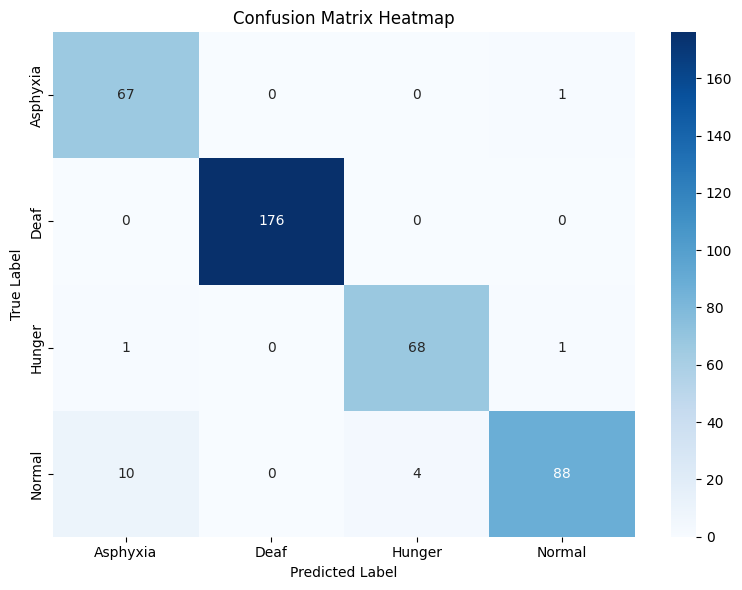

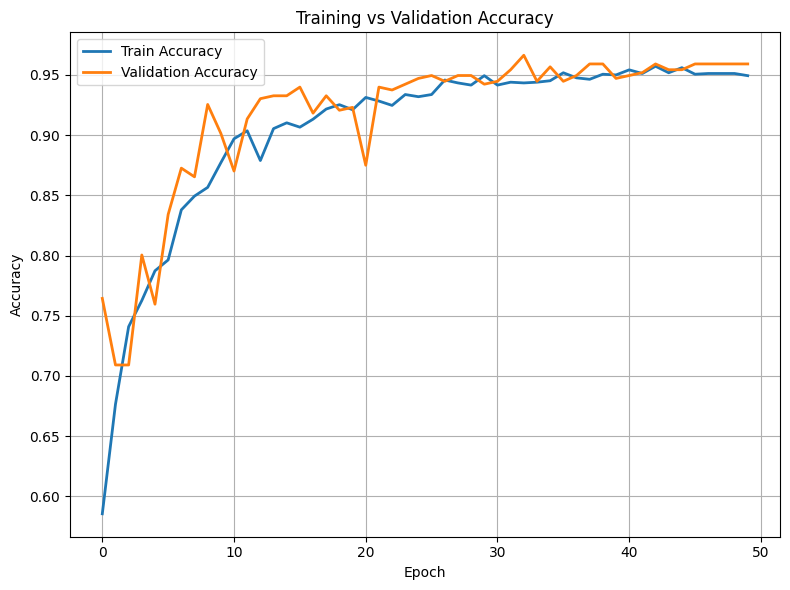

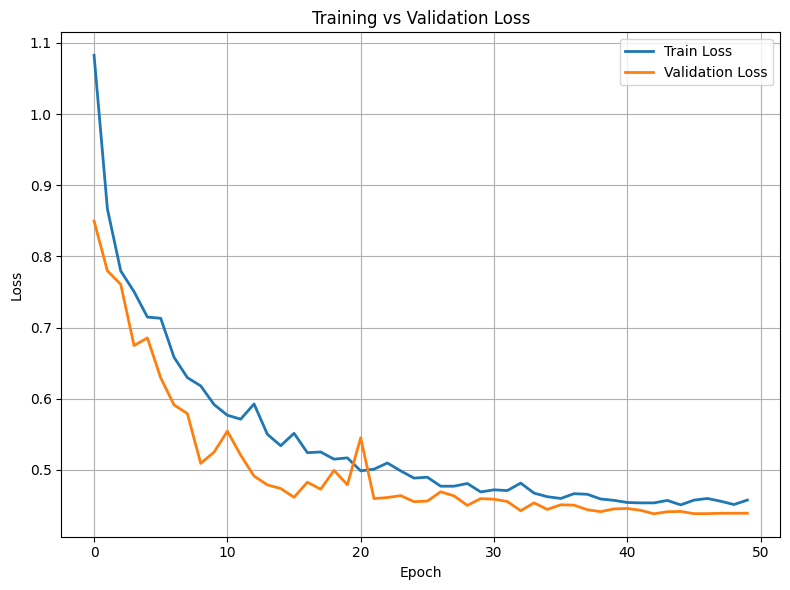

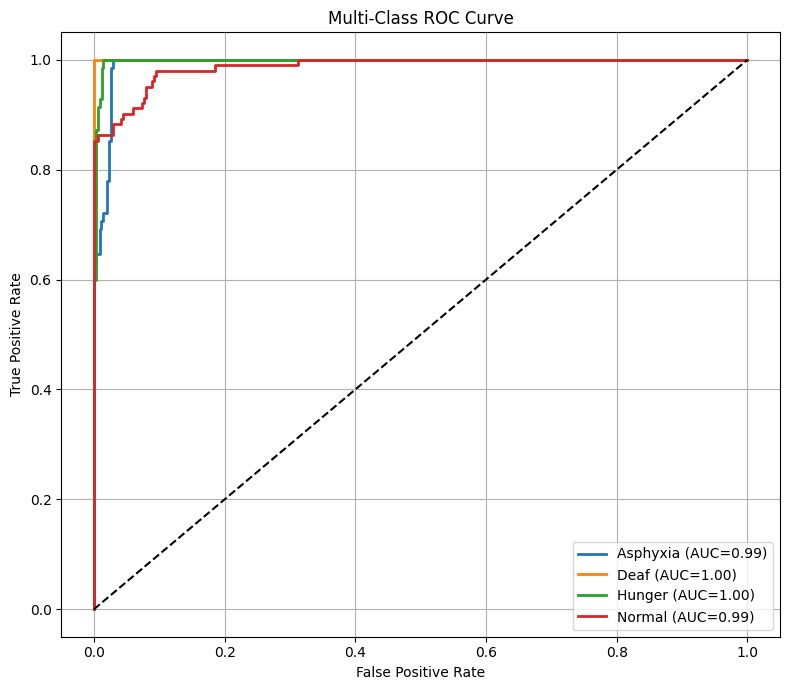


INFERENCE PERFORMANCE
Latency : 4.20 ms/image
FPS     : 238.00

TRAINING TIME
Epoch 01: 22.68 sec
Epoch 02: 22.62 sec
Epoch 03: 22.53 sec
Epoch 04: 22.49 sec
Epoch 05: 22.57 sec
Epoch 06: 22.46 sec
Epoch 07: 22.53 sec
Epoch 08: 22.51 sec
Epoch 09: 22.56 sec
Epoch 10: 22.43 sec
Epoch 11: 22.61 sec
Epoch 12: 22.58 sec
Epoch 13: 22.54 sec
Epoch 14: 22.51 sec
Epoch 15: 22.54 sec
Epoch 16: 22.50 sec
Epoch 17: 22.55 sec
Epoch 18: 22.62 sec
Epoch 19: 22.47 sec
Epoch 20: 22.56 sec
Epoch 21: 22.61 sec
Epoch 22: 22.58 sec
Epoch 23: 22.58 sec
Epoch 24: 22.51 sec
Epoch 25: 22.64 sec
Epoch 26: 22.58 sec
Epoch 27: 22.56 sec
Epoch 28: 22.62 sec
Epoch 29: 22.59 sec
Epoch 30: 22.59 sec
Epoch 31: 22.61 sec
Epoch 32: 22.63 sec
Epoch 33: 22.53 sec
Epoch 34: 22.46 sec
Epoch 35: 22.60 sec
Epoch 36: 22.58 sec
Epoch 37: 22.52 sec
Epoch 38: 22.51 sec
Epoch 39: 22.51 sec
Epoch 40: 22.49 sec
Epoch 41: 22.53 sec
Epoch 42: 22.56 sec
Epoch 43: 22.62 sec
Epoch 44: 22.52 sec
Epoch 45: 22.57 sec
Epoch 46: 22.60 sec
E

In [32]:
# ============================================================
# TinyCryViT - Baby Chillanto RGB Classification
#
# ABLATION CONFIGURATION
#
# Embedding Dimension = 128
# Attention Heads     = 4
# Transformer Blocks  = 3
# GRU Hidden Dimension= 128
# ============================================================

import os
import time
import math
import random

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize

from collections import defaultdict

from thop import profile


# ============================================================
# CONFIGURATION
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# TINYCRYVIT ABLATION CONFIGURATION
# ============================================================

EMBED_DIM = 128
NUM_HEADS = 4
NUM_BLOCKS = 3
GRU_HIDDEN = 128


print("\n==============================================")
print("TinyCryViT Configuration")
print("==============================================")

print("Embedding Dimension :", EMBED_DIM)
print("Attention Heads     :", NUM_HEADS)
print("Transformer Blocks  :", NUM_BLOCKS)
print("GRU Hidden Dimension:", GRU_HIDDEN)
print("Device              :", DEVICE)

print("==============================================")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================

# Separate datasets are used so that the training transform
# and validation transform remain independent.

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)


CLASS_NAMES = train_dataset_full.classes

NUM_CLASSES = len(CLASS_NAMES)


print("\nDetected Classes:")
print(CLASS_NAMES)

print(
    "Number of Classes:",
    NUM_CLASSES
)


# ============================================================
# CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)


for idx, label in enumerate(
    train_dataset_full.targets
):

    indices_by_class[label].append(idx)


train_idx = []

val_idx = []


for label, idxs in indices_by_class.items():

    idxs = idxs.copy()

    np.random.shuffle(idxs)

    split = int(
        0.8 * len(idxs)
    )

    train_idx.extend(
        idxs[:split]
    )

    val_idx.extend(
        idxs[split:]
    )


# ============================================================
# DATASET SUBSETS
# ============================================================

train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(

    train_ds,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)


val_loader = DataLoader(

    val_ds,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


print(
    "\nTrain Samples      :",
    len(train_ds)
)

print(
    "Validation Samples :",
    len(val_ds)
)


# ============================================================
# PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        embed_dim=128
    ):

        super().__init__()


        self.proj = nn.Conv2d(

            in_channels=3,

            out_channels=embed_dim,

            kernel_size=16,

            stride=16
        )


    def forward(self, x):

        # Input:
        # [B, 3, 224, 224]

        x = self.proj(x)

        # [B, 128, 14, 14]

        x = x.flatten(2)

        # [B, 128, 196]

        x = x.transpose(1, 2)

        # [B, 196, 128]

        return x


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim=128,
        heads=4
    ):

        super().__init__()


        self.norm1 = nn.LayerNorm(
            dim
        )


        self.attn = nn.MultiheadAttention(

            embed_dim=dim,

            num_heads=heads,

            batch_first=True
        )


        self.norm2 = nn.LayerNorm(
            dim
        )


        self.mlp = nn.Sequential(

            nn.Linear(
                dim,
                dim * 4
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                dim * 4,
                dim
            )
        )


    def forward(self, x):

        # ----------------------------------------
        # Self Attention
        # ----------------------------------------

        normalized_x = self.norm1(x)


        attn_output, _ = self.attn(

            normalized_x,

            normalized_x,

            normalized_x
        )


        x = x + attn_output


        # ----------------------------------------
        # MLP
        # ----------------------------------------

        x = x + self.mlp(
            self.norm2(x)
        )


        return x


# ============================================================
# TinyCryViT
# ============================================================

class TinyCryViT(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_blocks=3,
        num_heads=4,
        gru_hidden=128,
        num_classes=NUM_CLASSES
    ):

        super().__init__()


        # ----------------------------------------
        # Patch Embedding
        # ----------------------------------------

        self.patch = PatchEmbedding(

            embed_dim=embed_dim
        )


        # ----------------------------------------
        # Transformer Blocks
        # ----------------------------------------

        transformer_layers = []


        for _ in range(num_blocks):

            transformer_layers.append(

                TransformerBlock(

                    dim=embed_dim,

                    heads=num_heads
                )
            )


        self.blocks = nn.Sequential(

            *transformer_layers
        )


        # ----------------------------------------
        # Bidirectional GRU
        # ----------------------------------------

        self.bigru = nn.GRU(

            input_size=embed_dim,

            hidden_size=gru_hidden,

            bidirectional=True,

            batch_first=True
        )


        # ----------------------------------------
        # Classification Head
        # ----------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(

                gru_hidden * 2,

                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(

                128,

                num_classes
            )
        )


    def forward(self, x):

        # Patch embedding

        x = self.patch(x)


        # Transformer

        x = self.blocks(x)


        # BiGRU

        _, h = self.bigru(x)


        # Forward + backward hidden states

        h = torch.cat(

            [
                h[-2],
                h[-1]
            ],

            dim=1
        )


        # Classification

        out = self.fc(h)


        return out


# ============================================================
# CREATE MODEL
# ============================================================

model = TinyCryViT(

    embed_dim=EMBED_DIM,

    num_blocks=NUM_BLOCKS,

    num_heads=NUM_HEADS,

    gru_hidden=GRU_HIDDEN,

    num_classes=NUM_CLASSES

).to(DEVICE)


print("\nModel created successfully.")


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(

    p.numel()

    for p in model.parameters()
)


trainable_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad
)


non_trainable_params = (

    total_params -

    trainable_params
)


# ============================================================
# GFLOPs
# ============================================================

dummy = torch.randn(

    1,

    3,

    IMG_SIZE,

    IMG_SIZE

).to(DEVICE)


model.eval()


flops, params = profile(

    model,

    inputs=(dummy,),

    verbose=False
)


gflops = flops / 1e9


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_file = (
    "temp_model.pth"
)


torch.save(

    model.state_dict(),

    temp_model_file
)


model_size_mb = (

    os.path.getsize(
        temp_model_file
    )

    /

    (1024 * 1024)
)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

print("\n==============================================")
print("MODEL COMPLEXITY")
print("==============================================")


print(
    "Embedding Dimension     :",
    EMBED_DIM
)

print(
    "Attention Heads         :",
    NUM_HEADS
)

print(
    "Transformer Blocks      :",
    NUM_BLOCKS
)

print(
    "GRU Hidden Dimension    :",
    GRU_HIDDEN
)

print(
    "Total Parameters        :",
    f"{total_params:,}"
)

print(
    "Trainable Parameters    :",
    f"{trainable_params:,}"
)

print(
    "Non-Trainable Parameters:",
    f"{non_trainable_params:,}"
)

print(
    "GFLOPs                  :",
    f"{gflops:.4f}"
)

print(
    "Model Size              :",
    f"{model_size_mb:.2f} MB"
)

print("==============================================")


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(

    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LR,

    weight_decay=1e-4
)


# ============================================================
# SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS
)


# ============================================================
# HISTORY
# ============================================================

history = {

    "train_acc": [],

    "val_acc": [],

    "train_loss": [],

    "val_loss": [],

    "epoch_time": []
}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(

    loader,

    train=True

):

    if train:

        model.train()

    else:

        model.eval()


    total_loss = 0.0

    correct = 0

    total = 0


    y_true = []

    y_pred = []

    y_score = []


    for x, y in loader:


        x = x.to(

            DEVICE,

            non_blocking=True
        )


        y = y.to(

            DEVICE,

            non_blocking=True
        )


        if train:

            optimizer.zero_grad()


        with torch.set_grad_enabled(train):


            out = model(x)


            loss = criterion(

                out,

                y
            )


            if train:

                loss.backward()

                optimizer.step()


        total_loss += loss.item()


        preds = out.argmax(

            dim=1
        )


        correct += (

            preds == y

        ).sum().item()


        total += y.size(0)


        y_true.extend(

            y.detach()
            .cpu()
            .numpy()
        )


        y_pred.extend(

            preds.detach()
            .cpu()
            .numpy()
        )


        probabilities = torch.softmax(

            out,

            dim=1
        )


        y_score.extend(

            probabilities.detach()
            .cpu()
            .numpy()
        )


    avg_loss = (

        total_loss /

        len(loader)
    )


    accuracy = (

        correct /

        total
    )


    return (

        avg_loss,

        accuracy,

        np.array(y_true),

        np.array(y_pred),

        np.array(y_score)
    )


# ============================================================
# TRAINING
# ============================================================

print("\n==============================================")
print("TRAINING STARTED")
print("==============================================")


training_start = time.time()


for epoch in range(EPOCHS):


    epoch_start = time.time()


    # Training

    (

        train_loss,

        train_acc,

        _,

        _,

        _

    ) = run_epoch(

        train_loader,

        train=True
    )


    # Validation

    (

        val_loss,

        val_acc,

        y_true,

        y_pred,

        y_score

    ) = run_epoch(

        val_loader,

        train=False
    )


    # Scheduler

    scheduler.step()


    epoch_time = (

        time.time() -

        epoch_start
    )


    # Save history

    history[
        "train_acc"
    ].append(

        train_acc
    )


    history[
        "val_acc"
    ].append(

        val_acc
    )


    history[
        "train_loss"
    ].append(

        train_loss
    )


    history[
        "val_loss"
    ].append(

        val_loss
    )


    history[
        "epoch_time"
    ].append(

        epoch_time
    )


    print(

        f"Epoch [{epoch + 1}/{EPOCHS}] | "

        f"Train Acc: {train_acc:.4f} | "

        f"Val Acc: {val_acc:.4f} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Time: {epoch_time:.2f} sec"
    )


training_end = time.time()


total_training_time = (

    training_end -

    training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(

    y_true,

    y_pred
)


overall_prec, overall_rec, overall_f1, _ = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average="macro",

        zero_division=0
    )
)


overall_std = np.std(

    y_pred == y_true
)


overall_rmse = math.sqrt(

    mean_squared_error(

        y_true,

        y_pred
    )
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")


print(
    f"Embedding Dimension : {EMBED_DIM}"
)

print(
    f"Attention Heads     : {NUM_HEADS}"
)

print(
    f"Transformer Blocks  : {NUM_BLOCKS}"
)

print(
    f"GRU Hidden Dimension: {GRU_HIDDEN}"
)


print(
    f"Accuracy            : {overall_acc:.4f}"
)

print(
    f"Accuracy (%)        : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Precision           : "
    f"{overall_prec:.4f}"
)


print(
    f"Recall              : "
    f"{overall_rec:.4f}"
)


print(
    f"F1-Score            : "
    f"{overall_f1:.4f}"
)


print(
    f"Standard Deviation  : "
    f"{overall_std:.4f}"
)


print(
    f"RMSE                : "
    f"{overall_rmse:.4f}"
)


print(
    f"Total Parameters    : "
    f"{total_params:,}"
)


print(
    f"Trainable Parameters: "
    f"{trainable_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print(
    f"Model Size          : "
    f"{model_size_mb:.2f} MB"
)


print(
    f"Training Time       : "
    f"{total_training_time:.2f} sec"
)


print("==============================================")


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average=None,

        zero_division=0
    )
)


print("\n==============================================")
print("CLASSWISE METRICS")
print("==============================================")


for i, name in enumerate(

    CLASS_NAMES

):


    idx = (

        y_true == i
    )


    class_acc = np.mean(

        y_pred[idx] == i
    )


    class_std = np.std(

        y_pred[idx] == i
    )


    class_rmse = math.sqrt(

        mean_squared_error(

            y_true[idx],

            y_pred[idx]
        )
    )


    print(
        f"\nClass: {name}"
    )


    print(
        f"Accuracy     : "
        f"{class_acc:.4f}"
    )


    print(
        f"Precision    : "
        f"{class_prec[i]:.4f}"
    )


    print(
        f"Recall       : "
        f"{class_rec[i]:.4f}"
    )


    print(
        f"F1-Score     : "
        f"{class_f1[i]:.4f}"
    )


    print(
        f"Standard Dev : "
        f"{class_std:.4f}"
    )


    print(
        f"RMSE         : "
        f"{class_rmse:.4f}"
    )


    print(
        f"Samples      : "
        f"{support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    y_true,

    y_pred
)


print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")

print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(

    figsize=(8, 6)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Confusion Matrix Heatmap"
)

plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(

    figsize=(8, 6)
)


plt.plot(

    history["train_acc"],

    label="Train Accuracy",

    linewidth=2
)


plt.plot(

    history["val_acc"],

    label="Validation Accuracy",

    linewidth=2
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(

    figsize=(8, 6)
)


plt.plot(

    history["train_loss"],

    label="Train Loss",

    linewidth=2
)


plt.plot(

    history["val_loss"],

    label="Validation Loss",

    linewidth=2
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training vs Validation Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(

    y_true,

    classes=range(NUM_CLASSES)
)


plt.figure(

    figsize=(8, 7)
)


for i in range(

    NUM_CLASSES

):


    fpr, tpr, _ = roc_curve(

        y_bin[:, i],

        y_score[:, i]
    )


    roc_auc = auc(

        fpr,

        tpr
    )


    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=(

            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"
        )
    )


plt.plot(

    [0, 1],

    [0, 1],

    "k--"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Multi-Class ROC Curve"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# INFERENCE LATENCY AND FPS
# ============================================================

model.eval()


# Warm-up

with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


end = time.time()


latency = (

    end - start

) / 30


fps = 1 / latency


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")


print(
    f"Latency : "
    f"{latency * 1000:.2f} ms/image"
)


print(
    f"FPS     : "
    f"{fps:.2f}"
)


# ============================================================
# TRAINING TIME
# ============================================================

print("\n==============================================")
print("TRAINING TIME")
print("==============================================")


for i, t in enumerate(

    history["epoch_time"]

):

    print(

        f"Epoch {i + 1:02d}: "
        f"{t:.2f} sec"
    )


print(

    f"\nTotal Training Time: "
    f"{total_training_time:.2f} sec"
)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_NAME = (

    "TinyCryViT_E128_H4_B3_GRU128.pth"
)


torch.save(

    model.state_dict(),

    MODEL_NAME
)


print("\n==============================================")
print("MODEL SAVED")
print("==============================================")


print(
    "File:",
    MODEL_NAME
)


# ============================================================
# FINAL ABLATION SUMMARY
# ============================================================

print("\n==============================================")
print("ABLATION SUMMARY")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Parameters          : "
    f"{total_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print("==============================================")


In [26]:
# ============================================================
# TinyCryViT - Baby Chillanto RGB Classification
#
# ABLATION CONFIGURATION
#
# Embedding Dimension = 192
# Attention Heads     = 6
# Transformer Blocks  = 3
# GRU Hidden Dimension= 128
# ============================================================

import os
import time
import math
import random

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize

from collections import defaultdict

from thop import profile


# ============================================================
# CONFIGURATION
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# TINYCRYVIT ABLATION CONFIGURATION
# ============================================================

EMBED_DIM = 192
NUM_HEADS = 6
NUM_BLOCKS = 3
GRU_HIDDEN = 128


print("\n==============================================")
print("TinyCryViT Configuration")
print("==============================================")

print("Embedding Dimension :", EMBED_DIM)
print("Attention Heads     :", NUM_HEADS)
print("Transformer Blocks  :", NUM_BLOCKS)
print("GRU Hidden Dimension:", GRU_HIDDEN)
print("Device              :", DEVICE)

print("==============================================")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)


CLASS_NAMES = train_dataset_full.classes

NUM_CLASSES = len(CLASS_NAMES)


print("\nDetected Classes:")
print(CLASS_NAMES)

print(
    "Number of Classes:",
    NUM_CLASSES
)


# ============================================================
# CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)


for idx, label in enumerate(
    train_dataset_full.targets
):

    indices_by_class[label].append(idx)


train_idx = []

val_idx = []


for label, idxs in indices_by_class.items():

    idxs = idxs.copy()

    np.random.shuffle(idxs)

    split = int(
        0.8 * len(idxs)
    )

    train_idx.extend(
        idxs[:split]
    )

    val_idx.extend(
        idxs[split:]
    )


# ============================================================
# DATASET SUBSETS
# ============================================================

train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(

    train_ds,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)


val_loader = DataLoader(

    val_ds,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


print(
    "\nTrain Samples      :",
    len(train_ds)
)

print(
    "Validation Samples :",
    len(val_ds)
)


# ============================================================
# PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        embed_dim=192
    ):

        super().__init__()

        self.proj = nn.Conv2d(

            in_channels=3,

            out_channels=embed_dim,

            kernel_size=16,

            stride=16
        )


    def forward(self, x):

        # Input:
        # [B, 3, 224, 224]

        x = self.proj(x)

        # [B, 192, 14, 14]

        x = x.flatten(2)

        # [B, 192, 196]

        x = x.transpose(1, 2)

        # [B, 196, 192]

        return x


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim=192,
        heads=6
    ):

        super().__init__()


        self.norm1 = nn.LayerNorm(
            dim
        )


        self.attn = nn.MultiheadAttention(

            embed_dim=dim,

            num_heads=heads,

            batch_first=True
        )


        self.norm2 = nn.LayerNorm(
            dim
        )


        self.mlp = nn.Sequential(

            nn.Linear(
                dim,
                dim * 4
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                dim * 4,
                dim
            )
        )


    def forward(self, x):

        # ----------------------------------------
        # Self Attention
        # ----------------------------------------

        normalized_x = self.norm1(x)


        attn_output, _ = self.attn(

            normalized_x,

            normalized_x,

            normalized_x
        )


        x = x + attn_output


        # ----------------------------------------
        # MLP
        # ----------------------------------------

        x = x + self.mlp(
            self.norm2(x)
        )


        return x


# ============================================================
# TinyCryViT
# ============================================================

class TinyCryViT(nn.Module):

    def __init__(
        self,
        embed_dim=192,
        num_blocks=3,
        num_heads=6,
        gru_hidden=128,
        num_classes=NUM_CLASSES
    ):

        super().__init__()


        # ----------------------------------------
        # Patch Embedding
        # ----------------------------------------

        self.patch = PatchEmbedding(

            embed_dim=embed_dim
        )


        # ----------------------------------------
        # Transformer Blocks
        # ----------------------------------------

        transformer_layers = []


        for _ in range(num_blocks):

            transformer_layers.append(

                TransformerBlock(

                    dim=embed_dim,

                    heads=num_heads
                )
            )


        self.blocks = nn.Sequential(

            *transformer_layers
        )


        # ----------------------------------------
        # Bidirectional GRU
        # ----------------------------------------

        self.bigru = nn.GRU(

            input_size=embed_dim,

            hidden_size=gru_hidden,

            bidirectional=True,

            batch_first=True
        )


        # ----------------------------------------
        # Classification Head
        # ----------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(

                gru_hidden * 2,

                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(

                128,

                num_classes
            )
        )


    def forward(self, x):

        # Patch embedding

        x = self.patch(x)


        # Transformer blocks

        x = self.blocks(x)


        # BiGRU

        _, h = self.bigru(x)


        # Forward + backward hidden states

        h = torch.cat(

            [
                h[-2],
                h[-1]
            ],

            dim=1
        )


        # Classification

        out = self.fc(h)


        return out


# ============================================================
# CREATE MODEL
# ============================================================

model = TinyCryViT(

    embed_dim=EMBED_DIM,

    num_blocks=NUM_BLOCKS,

    num_heads=NUM_HEADS,

    gru_hidden=GRU_HIDDEN,

    num_classes=NUM_CLASSES

).to(DEVICE)


print("\nModel created successfully.")


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(

    p.numel()

    for p in model.parameters()
)


trainable_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad
)


non_trainable_params = (

    total_params -

    trainable_params
)


# ============================================================
# GFLOPs
# ============================================================

dummy = torch.randn(

    1,

    3,

    IMG_SIZE,

    IMG_SIZE

).to(DEVICE)


model.eval()


flops, params = profile(

    model,

    inputs=(dummy,),

    verbose=False
)


gflops = flops / 1e9


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_file = "temp_model.pth"


torch.save(

    model.state_dict(),

    temp_model_file
)


model_size_mb = (

    os.path.getsize(
        temp_model_file
    )

    /

    (1024 * 1024)
)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

print("\n==============================================")
print("MODEL COMPLEXITY")
print("==============================================")


print(
    "Embedding Dimension     :",
    EMBED_DIM
)

print(
    "Attention Heads         :",
    NUM_HEADS
)

print(
    "Transformer Blocks      :",
    NUM_BLOCKS
)

print(
    "GRU Hidden Dimension    :",
    GRU_HIDDEN
)

print(
    "Total Parameters        :",
    f"{total_params:,}"
)

print(
    "Trainable Parameters    :",
    f"{trainable_params:,}"
)

print(
    "Non-Trainable Parameters:",
    f"{non_trainable_params:,}"
)

print(
    "GFLOPs                  :",
    f"{gflops:.4f}"
)

print(
    "Model Size              :",
    f"{model_size_mb:.2f} MB"
)

print("==============================================")


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LR,

    weight_decay=1e-4
)


# ============================================================
# SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS
)


# ============================================================
# HISTORY
# ============================================================

history = {

    "train_acc": [],

    "val_acc": [],

    "train_loss": [],

    "val_loss": [],

    "epoch_time": []
}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(
    loader,
    train=True
):

    if train:

        model.train()

    else:

        model.eval()


    total_loss = 0.0

    correct = 0

    total = 0


    y_true = []

    y_pred = []

    y_score = []


    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )


        if train:

            optimizer.zero_grad()


        with torch.set_grad_enabled(train):

            out = model(x)

            loss = criterion(
                out,
                y
            )


            if train:

                loss.backward()

                optimizer.step()


        total_loss += loss.item()


        preds = out.argmax(
            dim=1
        )


        correct += (
            preds == y
        ).sum().item()


        total += y.size(0)


        y_true.extend(
            y.detach()
            .cpu()
            .numpy()
        )


        y_pred.extend(
            preds.detach()
            .cpu()
            .numpy()
        )


        probabilities = torch.softmax(
            out,
            dim=1
        )


        y_score.extend(
            probabilities.detach()
            .cpu()
            .numpy()
        )


    avg_loss = (
        total_loss /
        len(loader)
    )


    accuracy = (
        correct /
        total
    )


    return (
        avg_loss,
        accuracy,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


# ============================================================
# TRAINING
# ============================================================

print("\n==============================================")
print("TRAINING STARTED")
print("==============================================")


training_start = time.time()


for epoch in range(EPOCHS):

    epoch_start = time.time()


    # Training

    (
        train_loss,
        train_acc,
        _,
        _,
        _
    ) = run_epoch(
        train_loader,
        train=True
    )


    # Validation

    (
        val_loss,
        val_acc,
        y_true,
        y_pred,
        y_score
    ) = run_epoch(
        val_loader,
        train=False
    )


    scheduler.step()


    epoch_time = (
        time.time() -
        epoch_start
    )


    history["train_acc"].append(
        train_acc
    )

    history["val_acc"].append(
        val_acc
    )

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["epoch_time"].append(
        epoch_time
    )


    print(

        f"Epoch [{epoch + 1}/{EPOCHS}] | "

        f"Train Acc: {train_acc:.4f} | "

        f"Val Acc: {val_acc:.4f} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Time: {epoch_time:.2f} sec"
    )


training_end = time.time()


total_training_time = (

    training_end -

    training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(
    y_true,
    y_pred
)


overall_prec, overall_rec, overall_f1, _ = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average="macro",

        zero_division=0
    )
)


overall_std = np.std(
    y_pred == y_true
)


overall_rmse = math.sqrt(

    mean_squared_error(

        y_true,

        y_pred
    )
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc:.4f}"
)


print(
    f"Accuracy (%)        : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Precision           : "
    f"{overall_prec:.4f}"
)


print(
    f"Recall              : "
    f"{overall_rec:.4f}"
)


print(
    f"F1-Score            : "
    f"{overall_f1:.4f}"
)


print(
    f"Standard Deviation  : "
    f"{overall_std:.4f}"
)


print(
    f"RMSE                : "
    f"{overall_rmse:.4f}"
)


print(
    f"Total Parameters    : "
    f"{total_params:,}"
)


print(
    f"Trainable Parameters: "
    f"{trainable_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print(
    f"Model Size          : "
    f"{model_size_mb:.2f} MB"
)


print(
    f"Training Time       : "
    f"{total_training_time:.2f} sec"
)


print("==============================================")


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average=None,

        zero_division=0
    )
)


print("\n==============================================")
print("CLASSWISE METRICS")
print("==============================================")


for i, name in enumerate(CLASS_NAMES):

    idx = (
        y_true == i
    )


    class_acc = np.mean(
        y_pred[idx] == i
    )


    class_std = np.std(
        y_pred[idx] == i
    )


    class_rmse = math.sqrt(

        mean_squared_error(

            y_true[idx],

            y_pred[idx]
        )
    )


    print(
        f"\nClass: {name}"
    )


    print(
        f"Accuracy     : "
        f"{class_acc:.4f}"
    )


    print(
        f"Precision    : "
        f"{class_prec[i]:.4f}"
    )


    print(
        f"Recall       : "
        f"{class_rec[i]:.4f}"
    )


    print(
        f"F1-Score     : "
        f"{class_f1[i]:.4f}"
    )


    print(
        f"Standard Dev : "
        f"{class_std:.4f}"
    )


    print(
        f"RMSE         : "
        f"{class_rmse:.4f}"
    )


    print(
        f"Samples      : "
        f"{support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")


print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Confusion Matrix Heatmap"
)


plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_acc"],

    label="Train Accuracy",

    linewidth=2
)


plt.plot(

    history["val_acc"],

    label="Validation Accuracy",

    linewidth=2
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_loss"],

    label="Train Loss",

    linewidth=2
)


plt.plot(

    history["val_loss"],

    label="Validation Loss",

    linewidth=2
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training vs Validation Loss"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(

    y_true,

    classes=range(NUM_CLASSES)
)


plt.figure(
    figsize=(8, 7)
)


for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(

        y_bin[:, i],

        y_score[:, i]
    )


    roc_auc = auc(

        fpr,

        tpr
    )


    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=(

            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"
        )
    )


plt.plot(

    [0, 1],

    [0, 1],

    "k--"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "Multi-Class ROC Curve"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# INFERENCE LATENCY AND FPS
# ============================================================

model.eval()


# Warm-up

with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


end = time.time()


latency = (

    end - start

) / 30


fps = 1 / latency


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")


print(
    f"Latency : "
    f"{latency * 1000:.2f} ms/image"
)


print(
    f"FPS     : "
    f"{fps:.2f}"
)


# ============================================================
# TRAINING TIME
# ============================================================

print("\n==============================================")
print("TRAINING TIME")
print("==============================================")


for i, t in enumerate(
    history["epoch_time"]
):

    print(

        f"Epoch {i + 1:02d}: "
        f"{t:.2f} sec"
    )


print(

    f"\nTotal Training Time: "
    f"{total_training_time:.2f} sec"
)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_NAME = (
    "TinyCryViT_E192_H6_B3_GRU128.pth"
)


torch.save(

    model.state_dict(),

    MODEL_NAME
)


print("\n==============================================")
print("MODEL SAVED")
print("==============================================")


print(
    "File:",
    MODEL_NAME
)


# ============================================================
# FINAL ABLATION SUMMARY
# ============================================================

print("\n==============================================")
print("ABLATION SUMMARY")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Parameters          : "
    f"{total_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print("==============================================")



TinyCryViT Configuration
Embedding Dimension : 192
Attention Heads     : 6
Transformer Blocks  : 3
GRU Hidden Dimension: 128
Device              : cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

Model created successfully.

MODEL COMPLEXITY
Embedding Dimension     : 192
Attention Heads         : 6
Transformer Blocks      : 3
GRU Hidden Dimension    : 128
Total Parameters        : 1,762,948
Trainable Parameters    : 1,762,948
Non-Trainable Parameters: 0
GFLOPs                  : 0.2521
Model Size              : 6.75 MB

TRAINING STARTED
Epoch [1/50] | Train Acc: 0.6012 | Val Acc: 0.7139 | Train Loss: 1.0502 | Val Loss: 0.8147 | Time: 22.71 sec
Epoch [2/50] | Train Acc: 0.7078 | Val Acc: 0.7380 | Train Loss: 0.8367 | Val Loss: 0.7265 | Time: 22.67 sec
Epoch [3/50] | Train Acc: 0.7627 | Val Acc: 0.8005 | Train Loss: 0.7681 | Val Loss: 0.6761 | Time: 22.62 sec
Epoch [4/50] | Train Acc: 0.7765 | Val 

KeyboardInterrupt: 


TinyCryViT Configuration
Embedding Dimension : 192
Attention Heads     : 6
Transformer Blocks  : 1
GRU Hidden Dimension: 128
Device              : cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

Model created successfully.

MODEL COMPLEXITY
Embedding Dimension     : 192
Attention Heads         : 6
Transformer Blocks      : 1
GRU Hidden Dimension    : 128
Total Parameters        : 873,220
Trainable Parameters    : 873,220
Non-Trainable Parameters: 0
GFLOPs                  : 0.1359
Model Size              : 3.34 MB

TRAINING STARTED
Epoch [1/50] | Train Acc: 0.5717 | Val Acc: 0.6851 | Train Loss: 1.0907 | Val Loss: 0.8820 | Time: 22.52 sec
Epoch [2/50] | Train Acc: 0.6789 | Val Acc: 0.7115 | Train Loss: 0.8860 | Val Loss: 0.8285 | Time: 22.50 sec
Epoch [3/50] | Train Acc: 0.7373 | Val Acc: 0.7644 | Train Loss: 0.7958 | Val Loss: 0.7185 | Time: 22.52 sec
Epoch [4/50] | Train Acc: 0.7566 | Val Acc:

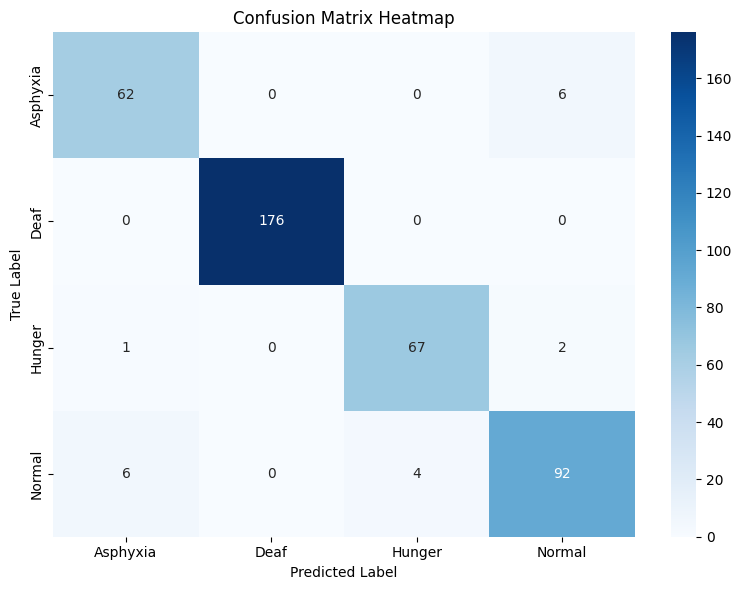

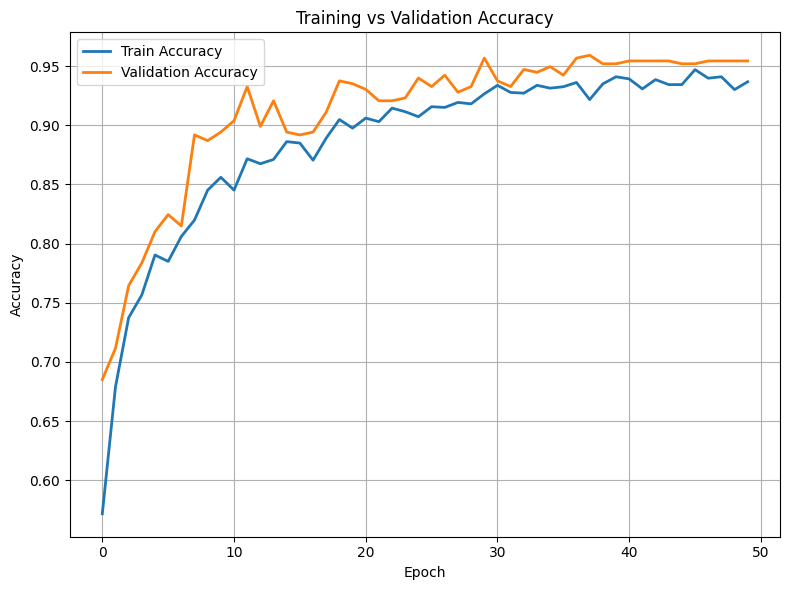

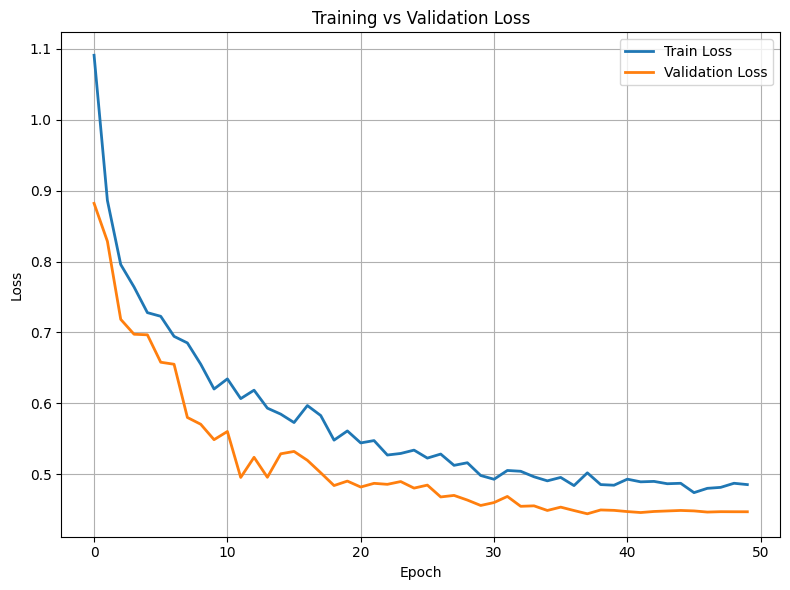

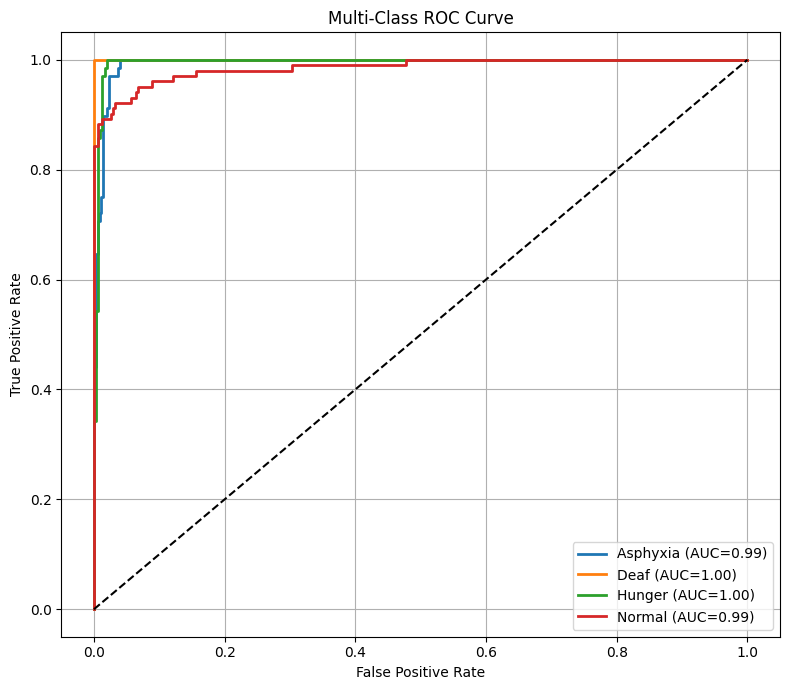


INFERENCE PERFORMANCE
Latency : 2.68 ms/image
FPS     : 373.22

TRAINING TIME
Epoch 01: 22.52 sec
Epoch 02: 22.50 sec
Epoch 03: 22.52 sec
Epoch 04: 22.40 sec
Epoch 05: 22.59 sec
Epoch 06: 22.47 sec
Epoch 07: 22.58 sec
Epoch 08: 22.56 sec
Epoch 09: 22.58 sec
Epoch 10: 22.52 sec
Epoch 11: 22.43 sec
Epoch 12: 22.62 sec
Epoch 13: 22.54 sec
Epoch 14: 22.45 sec
Epoch 15: 22.47 sec
Epoch 16: 22.43 sec
Epoch 17: 22.44 sec
Epoch 18: 22.51 sec
Epoch 19: 22.40 sec
Epoch 20: 22.47 sec
Epoch 21: 22.55 sec
Epoch 22: 22.46 sec
Epoch 23: 22.51 sec
Epoch 24: 22.42 sec
Epoch 25: 22.54 sec
Epoch 26: 22.54 sec
Epoch 27: 22.47 sec
Epoch 28: 22.42 sec
Epoch 29: 22.47 sec
Epoch 30: 22.49 sec
Epoch 31: 22.47 sec
Epoch 32: 22.44 sec
Epoch 33: 22.51 sec
Epoch 34: 22.53 sec
Epoch 35: 22.44 sec
Epoch 36: 22.55 sec
Epoch 37: 22.47 sec
Epoch 38: 22.52 sec
Epoch 39: 22.54 sec
Epoch 40: 22.42 sec
Epoch 41: 22.53 sec
Epoch 42: 22.45 sec
Epoch 43: 22.44 sec
Epoch 44: 22.55 sec
Epoch 45: 22.42 sec
Epoch 46: 22.49 sec
E

In [27]:
# ============================================================
# TinyCryViT - Baby Chillanto RGB Classification
#
# ABLATION CONFIGURATION
#
# Embedding Dimension = 192
# Attention Heads     = 6
# Transformer Blocks  = 1
# GRU Hidden Dimension= 128
# ============================================================

import os
import time
import math
import random

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize

from collections import defaultdict

from thop import profile


# ============================================================
# CONFIGURATION
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# TINYCRYVIT ABLATION CONFIGURATION
# ============================================================

EMBED_DIM = 192
NUM_HEADS = 6
NUM_BLOCKS = 1
GRU_HIDDEN = 128


print("\n==============================================")
print("TinyCryViT Configuration")
print("==============================================")

print("Embedding Dimension :", EMBED_DIM)
print("Attention Heads     :", NUM_HEADS)
print("Transformer Blocks  :", NUM_BLOCKS)
print("GRU Hidden Dimension:", GRU_HIDDEN)
print("Device              :", DEVICE)

print("==============================================")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)


CLASS_NAMES = train_dataset_full.classes
NUM_CLASSES = len(CLASS_NAMES)


print("\nDetected Classes:")
print(CLASS_NAMES)

print(
    "Number of Classes:",
    NUM_CLASSES
)


# ============================================================
# CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)


for idx, label in enumerate(
    train_dataset_full.targets
):

    indices_by_class[label].append(idx)


train_idx = []
val_idx = []


for label, idxs in indices_by_class.items():

    idxs = idxs.copy()

    np.random.shuffle(idxs)

    split = int(
        0.8 * len(idxs)
    )

    train_idx.extend(
        idxs[:split]
    )

    val_idx.extend(
        idxs[split:]
    )


# ============================================================
# DATASET SUBSETS
# ============================================================

train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(

    train_ds,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)


val_loader = DataLoader(

    val_ds,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


print(
    "\nTrain Samples      :",
    len(train_ds)
)

print(
    "Validation Samples :",
    len(val_ds)
)


# ============================================================
# PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        embed_dim=192
    ):

        super().__init__()

        self.proj = nn.Conv2d(

            in_channels=3,

            out_channels=embed_dim,

            kernel_size=16,

            stride=16
        )


    def forward(self, x):

        # [B, 3, 224, 224]
        x = self.proj(x)

        # [B, 192, 14, 14]
        x = x.flatten(2)

        # [B, 192, 196]
        x = x.transpose(1, 2)

        # [B, 196, 192]
        return x


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim=192,
        heads=6
    ):

        super().__init__()

        self.norm1 = nn.LayerNorm(
            dim
        )

        self.attn = nn.MultiheadAttention(

            embed_dim=dim,

            num_heads=heads,

            batch_first=True
        )

        self.norm2 = nn.LayerNorm(
            dim
        )

        self.mlp = nn.Sequential(

            nn.Linear(
                dim,
                dim * 4
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                dim * 4,
                dim
            )
        )


    def forward(self, x):

        # Self-attention

        normalized_x = self.norm1(x)

        attn_output, _ = self.attn(

            normalized_x,

            normalized_x,

            normalized_x
        )

        x = x + attn_output

        # MLP

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ============================================================
# TinyCryViT
# ============================================================

class TinyCryViT(nn.Module):

    def __init__(
        self,
        embed_dim=192,
        num_blocks=1,
        num_heads=6,
        gru_hidden=128,
        num_classes=NUM_CLASSES
    ):

        super().__init__()


        # ----------------------------------------
        # Patch Embedding
        # ----------------------------------------

        self.patch = PatchEmbedding(
            embed_dim=embed_dim
        )


        # ----------------------------------------
        # Transformer Blocks
        # ----------------------------------------

        transformer_layers = []


        for _ in range(num_blocks):

            transformer_layers.append(

                TransformerBlock(

                    dim=embed_dim,

                    heads=num_heads
                )
            )


        self.blocks = nn.Sequential(

            *transformer_layers
        )


        # ----------------------------------------
        # Bidirectional GRU
        # ----------------------------------------

        self.bigru = nn.GRU(

            input_size=embed_dim,

            hidden_size=gru_hidden,

            bidirectional=True,

            batch_first=True
        )


        # ----------------------------------------
        # Classification Head
        # ----------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(

                gru_hidden * 2,

                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(

                128,

                num_classes
            )
        )


    def forward(self, x):

        # Patch embedding

        x = self.patch(x)

        # One Transformer block

        x = self.blocks(x)

        # BiGRU

        _, h = self.bigru(x)

        # Forward + backward hidden states

        h = torch.cat(

            [
                h[-2],
                h[-1]
            ],

            dim=1
        )

        # Classifier

        out = self.fc(h)

        return out


# ============================================================
# CREATE MODEL
# ============================================================

model = TinyCryViT(

    embed_dim=EMBED_DIM,

    num_blocks=NUM_BLOCKS,

    num_heads=NUM_HEADS,

    gru_hidden=GRU_HIDDEN,

    num_classes=NUM_CLASSES

).to(DEVICE)


print("\nModel created successfully.")


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(

    p.numel()

    for p in model.parameters()
)


trainable_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad
)


non_trainable_params = (

    total_params -
    trainable_params
)


# ============================================================
# GFLOPs
# ============================================================

dummy = torch.randn(

    1,
    3,
    IMG_SIZE,
    IMG_SIZE

).to(DEVICE)


model.eval()


flops, params = profile(

    model,

    inputs=(dummy,),

    verbose=False
)


gflops = flops / 1e9


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_file = (
    "temp_model.pth"
)


torch.save(

    model.state_dict(),

    temp_model_file
)


model_size_mb = (

    os.path.getsize(
        temp_model_file
    )
    /
    (1024 * 1024)
)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

print("\n==============================================")
print("MODEL COMPLEXITY")
print("==============================================")


print(
    "Embedding Dimension     :",
    EMBED_DIM
)

print(
    "Attention Heads         :",
    NUM_HEADS
)

print(
    "Transformer Blocks      :",
    NUM_BLOCKS
)

print(
    "GRU Hidden Dimension    :",
    GRU_HIDDEN
)

print(
    "Total Parameters        :",
    f"{total_params:,}"
)

print(
    "Trainable Parameters    :",
    f"{trainable_params:,}"
)

print(
    "Non-Trainable Parameters:",
    f"{non_trainable_params:,}"
)

print(
    "GFLOPs                  :",
    f"{gflops:.4f}"
)

print(
    "Model Size              :",
    f"{model_size_mb:.2f} MB"
)

print("==============================================")


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LR,

    weight_decay=1e-4
)


# ============================================================
# SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS
)


# ============================================================
# HISTORY
# ============================================================

history = {

    "train_acc": [],

    "val_acc": [],

    "train_loss": [],

    "val_loss": [],

    "epoch_time": []
}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(
    loader,
    train=True
):

    if train:
        model.train()
    else:
        model.eval()


    total_loss = 0.0

    correct = 0
    total = 0

    y_true = []
    y_pred = []
    y_score = []


    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )


        if train:

            optimizer.zero_grad()


        with torch.set_grad_enabled(train):

            out = model(x)

            loss = criterion(
                out,
                y
            )


            if train:

                loss.backward()

                optimizer.step()


        total_loss += loss.item()


        preds = out.argmax(
            dim=1
        )


        correct += (
            preds == y
        ).sum().item()


        total += y.size(0)


        y_true.extend(

            y.detach()
            .cpu()
            .numpy()
        )


        y_pred.extend(

            preds.detach()
            .cpu()
            .numpy()
        )


        probabilities = torch.softmax(

            out,

            dim=1
        )


        y_score.extend(

            probabilities.detach()
            .cpu()
            .numpy()
        )


    avg_loss = (
        total_loss /
        len(loader)
    )


    accuracy = (
        correct /
        total
    )


    return (

        avg_loss,

        accuracy,

        np.array(y_true),

        np.array(y_pred),

        np.array(y_score)

    )


# ============================================================
# TRAINING
# ============================================================

print("\n==============================================")
print("TRAINING STARTED")
print("==============================================")


training_start = time.time()


for epoch in range(EPOCHS):

    epoch_start = time.time()


    # Training

    (
        train_loss,
        train_acc,
        _,
        _,
        _
    ) = run_epoch(

        train_loader,

        train=True
    )


    # Validation

    (
        val_loss,
        val_acc,
        y_true,
        y_pred,
        y_score
    ) = run_epoch(

        val_loader,

        train=False
    )


    scheduler.step()


    epoch_time = (
        time.time() -
        epoch_start
    )


    history[
        "train_acc"
    ].append(
        train_acc
    )


    history[
        "val_acc"
    ].append(
        val_acc
    )


    history[
        "train_loss"
    ].append(
        train_loss
    )


    history[
        "val_loss"
    ].append(
        val_loss
    )


    history[
        "epoch_time"
    ].append(
        epoch_time
    )


    print(

        f"Epoch [{epoch + 1}/{EPOCHS}] | "

        f"Train Acc: {train_acc:.4f} | "

        f"Val Acc: {val_acc:.4f} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Time: {epoch_time:.2f} sec"

    )


training_end = time.time()


total_training_time = (

    training_end -
    training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(

    y_true,

    y_pred
)


overall_prec, overall_rec, overall_f1, _ = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average="macro",

        zero_division=0

    )
)


overall_std = np.std(

    y_pred == y_true
)


overall_rmse = math.sqrt(

    mean_squared_error(

        y_true,

        y_pred

    )
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc:.4f}"
)


print(
    f"Accuracy (%)        : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Precision           : "
    f"{overall_prec:.4f}"
)


print(
    f"Recall              : "
    f"{overall_rec:.4f}"
)


print(
    f"F1-Score            : "
    f"{overall_f1:.4f}"
)


print(
    f"Standard Deviation  : "
    f"{overall_std:.4f}"
)


print(
    f"RMSE                : "
    f"{overall_rmse:.4f}"
)


print(
    f"Total Parameters    : "
    f"{total_params:,}"
)


print(
    f"Trainable Parameters: "
    f"{trainable_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print(
    f"Model Size          : "
    f"{model_size_mb:.2f} MB"
)


print(
    f"Training Time       : "
    f"{total_training_time:.2f} sec"
)


print("==============================================")


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average=None,

        zero_division=0

    )
)


print("\n==============================================")
print("CLASSWISE METRICS")
print("==============================================")


for i, name in enumerate(CLASS_NAMES):

    idx = (
        y_true == i
    )


    class_acc = np.mean(

        y_pred[idx] == i
    )


    class_std = np.std(

        y_pred[idx] == i
    )


    class_rmse = math.sqrt(

        mean_squared_error(

            y_true[idx],

            y_pred[idx]

        )
    )


    print(
        f"\nClass: {name}"
    )


    print(
        f"Accuracy     : "
        f"{class_acc:.4f}"
    )


    print(
        f"Precision    : "
        f"{class_prec[i]:.4f}"
    )


    print(
        f"Recall       : "
        f"{class_rec[i]:.4f}"
    )


    print(
        f"F1-Score     : "
        f"{class_f1[i]:.4f}"
    )


    print(
        f"Standard Dev : "
        f"{class_std:.4f}"
    )


    print(
        f"RMSE         : "
        f"{class_rmse:.4f}"
    )


    print(
        f"Samples      : "
        f"{support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    y_true,

    y_pred
)


print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")


print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Confusion Matrix Heatmap"
)


plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_acc"],

    label="Train Accuracy",

    linewidth=2

)


plt.plot(

    history["val_acc"],

    label="Validation Accuracy",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_loss"],

    label="Train Loss",

    linewidth=2

)


plt.plot(

    history["val_loss"],

    label="Validation Loss",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training vs Validation Loss"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(

    y_true,

    classes=range(NUM_CLASSES)
)


plt.figure(
    figsize=(8, 7)
)


for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(

        y_bin[:, i],

        y_score[:, i]

    )


    roc_auc = auc(

        fpr,

        tpr

    )


    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=(

            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"

        )

    )


plt.plot(

    [0, 1],

    [0, 1],

    "k--"

)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Multi-Class ROC Curve"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# INFERENCE LATENCY AND FPS
# ============================================================

model.eval()


# Warm-up

with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


end = time.time()


latency = (

    end - start
) / 30


fps = 1 / latency


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")


print(

    f"Latency : "
    f"{latency * 1000:.2f} ms/image"

)


print(

    f"FPS     : "
    f"{fps:.2f}"

)


# ============================================================
# TRAINING TIME
# ============================================================

print("\n==============================================")
print("TRAINING TIME")
print("==============================================")


for i, t in enumerate(

    history["epoch_time"]

):

    print(

        f"Epoch {i + 1:02d}: "
        f"{t:.2f} sec"

    )


print(

    f"\nTotal Training Time: "
    f"{total_training_time:.2f} sec"

)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_NAME = (
    "TinyCryViT_E192_H6_B1_GRU128.pth"
)


torch.save(

    model.state_dict(),

    MODEL_NAME

)


print("\n==============================================")
print("MODEL SAVED")
print("==============================================")


print(
    "File:",
    MODEL_NAME
)


# ============================================================
# FINAL ABLATION SUMMARY
# ============================================================

print("\n==============================================")
print("ABLATION SUMMARY")
print("==============================================")


print(

    f"Embedding Dimension : "
    f"{EMBED_DIM}"

)


print(

    f"Attention Heads     : "
    f"{NUM_HEADS}"

)


print(

    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"

)


print(

    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"

)


print(

    f"Accuracy            : "
    f"{overall_acc * 100:.2f}%"

)


print(

    f"Parameters          : "
    f"{total_params:,}"

)


print(

    f"GFLOPs              : "
    f"{gflops:.4f}"

)


print("==============================================")



TinyCryViT Configuration
Embedding Dimension : 192
Attention Heads     : 6
Transformer Blocks  : 2
GRU Hidden Dimension: 128
Device              : cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

Model created successfully.

MODEL COMPLEXITY
Embedding Dimension     : 192
Attention Heads         : 6
Transformer Blocks      : 2
GRU Hidden Dimension    : 128
Total Parameters        : 1,318,084
Trainable Parameters    : 1,318,084
Non-Trainable Parameters: 0
GFLOPs                  : 0.1940
Model Size              : 5.04 MB

TRAINING STARTED
Epoch [1/50] | Train Acc: 0.5867 | Val Acc: 0.7356 | Train Loss: 1.0573 | Val Loss: 0.8481 | Time: 22.62 sec
Epoch [2/50] | Train Acc: 0.6904 | Val Acc: 0.8101 | Train Loss: 0.8539 | Val Loss: 0.7259 | Time: 22.51 sec
Epoch [3/50] | Train Acc: 0.7771 | Val Acc: 0.8197 | Train Loss: 0.7619 | Val Loss: 0.6541 | Time: 22.53 sec
Epoch [4/50] | Train Acc: 0.7880 | Val 

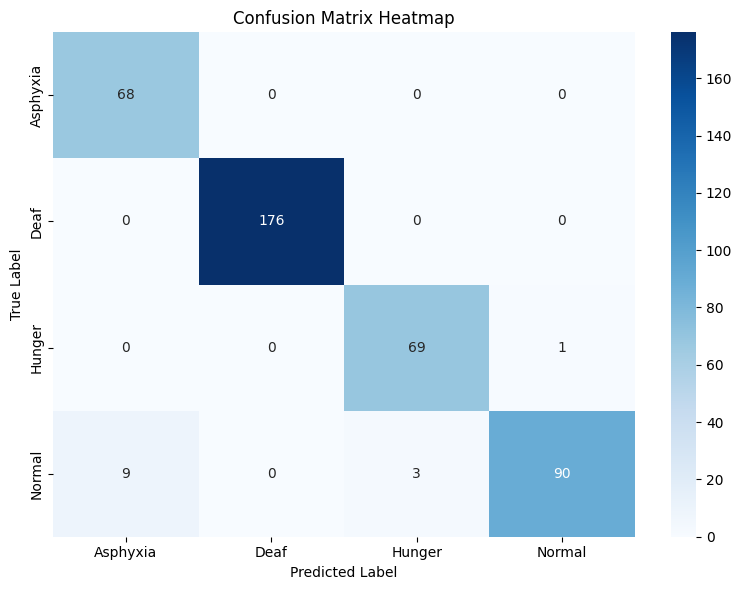

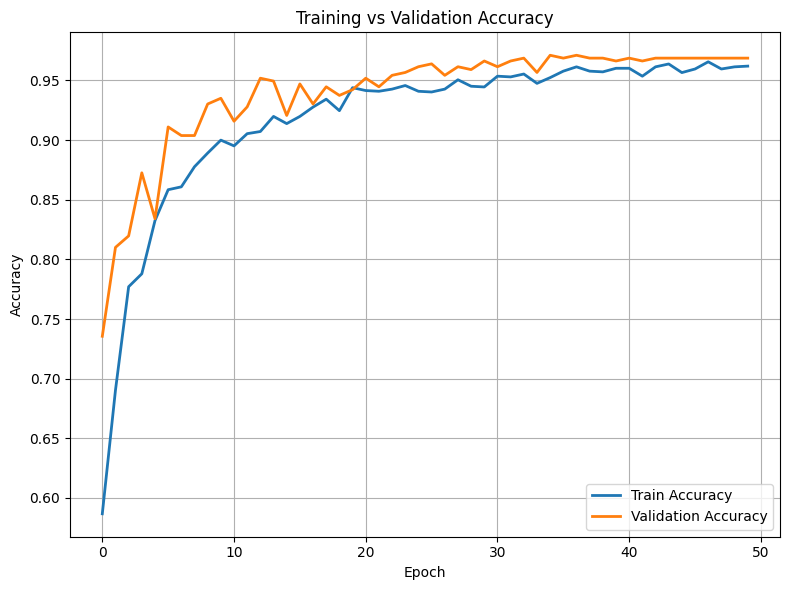

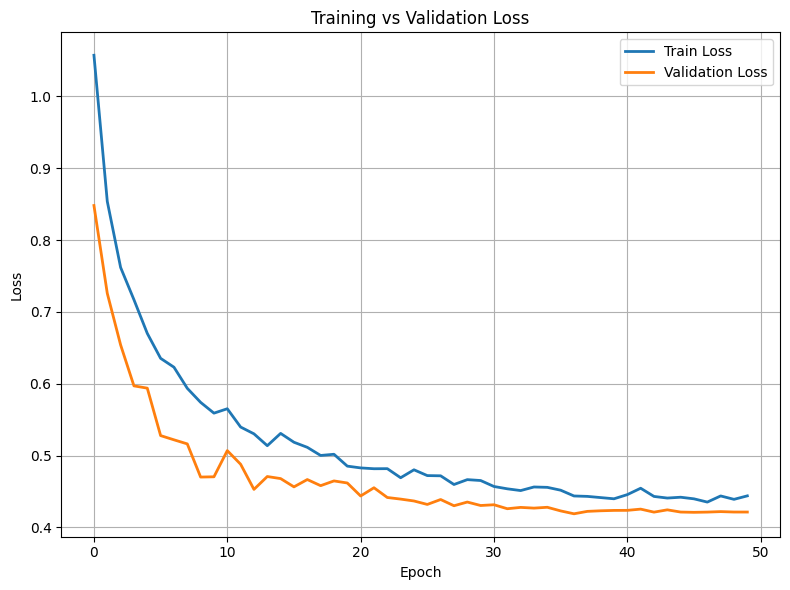

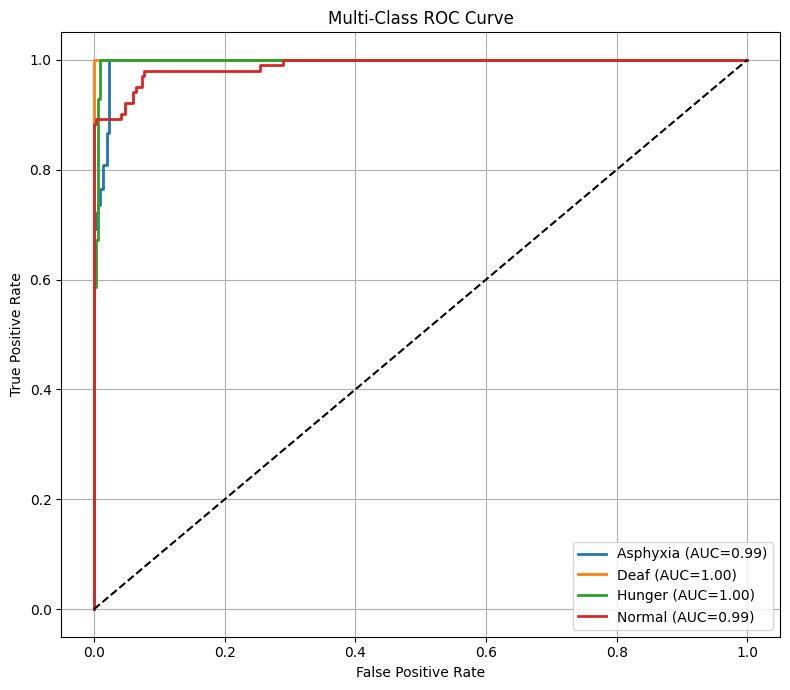


INFERENCE PERFORMANCE
Latency : 3.44 ms/image
FPS     : 290.77

TRAINING TIME
Epoch 01: 22.62 sec
Epoch 02: 22.51 sec
Epoch 03: 22.53 sec
Epoch 04: 22.64 sec
Epoch 05: 22.54 sec
Epoch 06: 22.45 sec
Epoch 07: 22.45 sec
Epoch 08: 22.45 sec
Epoch 09: 22.54 sec
Epoch 10: 22.44 sec
Epoch 11: 22.53 sec
Epoch 12: 22.49 sec
Epoch 13: 22.50 sec
Epoch 14: 22.49 sec
Epoch 15: 22.65 sec
Epoch 16: 22.54 sec
Epoch 17: 22.51 sec
Epoch 18: 22.52 sec
Epoch 19: 22.53 sec
Epoch 20: 22.56 sec
Epoch 21: 22.47 sec
Epoch 22: 22.58 sec
Epoch 23: 22.52 sec
Epoch 24: 22.45 sec
Epoch 25: 22.48 sec
Epoch 26: 22.48 sec
Epoch 27: 22.57 sec
Epoch 28: 22.48 sec
Epoch 29: 22.53 sec
Epoch 30: 22.52 sec
Epoch 31: 22.58 sec
Epoch 32: 22.47 sec
Epoch 33: 22.46 sec
Epoch 34: 22.47 sec
Epoch 35: 22.42 sec
Epoch 36: 22.60 sec
Epoch 37: 22.48 sec
Epoch 38: 22.49 sec
Epoch 39: 22.54 sec
Epoch 40: 22.54 sec
Epoch 41: 22.48 sec
Epoch 42: 22.58 sec
Epoch 43: 22.58 sec
Epoch 44: 22.49 sec
Epoch 45: 22.50 sec
Epoch 46: 22.60 sec
E

In [28]:
# ============================================================
# TinyCryViT - Baby Chillanto RGB Classification
#
# ABLATION CONFIGURATION
#
# Embedding Dimension = 192
# Attention Heads     = 6
# Transformer Blocks  = 2
# GRU Hidden Dimension= 128
# ============================================================

import os
import time
import math
import random

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize

from collections import defaultdict

from thop import profile


# ============================================================
# CONFIGURATION
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# TINYCRYVIT ABLATION CONFIGURATION
# ============================================================

EMBED_DIM = 192
NUM_HEADS = 6
NUM_BLOCKS = 2
GRU_HIDDEN = 128


print("\n==============================================")
print("TinyCryViT Configuration")
print("==============================================")

print("Embedding Dimension :", EMBED_DIM)
print("Attention Heads     :", NUM_HEADS)
print("Transformer Blocks  :", NUM_BLOCKS)
print("GRU Hidden Dimension:", GRU_HIDDEN)
print("Device              :", DEVICE)

print("==============================================")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)


CLASS_NAMES = train_dataset_full.classes
NUM_CLASSES = len(CLASS_NAMES)


print("\nDetected Classes:")
print(CLASS_NAMES)

print(
    "Number of Classes:",
    NUM_CLASSES
)


# ============================================================
# CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(
    train_dataset_full.targets
):
    indices_by_class[label].append(idx)


train_idx = []
val_idx = []


for label, idxs in indices_by_class.items():

    idxs = idxs.copy()

    np.random.shuffle(idxs)

    split = int(
        0.8 * len(idxs)
    )

    train_idx.extend(
        idxs[:split]
    )

    val_idx.extend(
        idxs[split:]
    )


# ============================================================
# DATASET SUBSETS
# ============================================================

train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print(
    "\nTrain Samples      :",
    len(train_ds)
)

print(
    "Validation Samples :",
    len(val_ds)
)


# ============================================================
# PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        embed_dim=192
    ):

        super().__init__()

        self.proj = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=16,
            stride=16
        )


    def forward(self, x):

        # Input:
        # [Batch, 3, 224, 224]

        x = self.proj(x)

        # [Batch, 192, 14, 14]

        x = x.flatten(2)

        # [Batch, 192, 196]

        x = x.transpose(1, 2)

        # [Batch, 196, 192]

        return x


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim=192,
        heads=6
    ):

        super().__init__()


        # Layer normalization

        self.norm1 = nn.LayerNorm(
            dim
        )


        # Multi-head self-attention

        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=heads,
            batch_first=True
        )


        # Second normalization

        self.norm2 = nn.LayerNorm(
            dim
        )


        # Feed-forward network

        self.mlp = nn.Sequential(

            nn.Linear(
                dim,
                dim * 4
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                dim * 4,
                dim
            )
        )


    def forward(self, x):

        # ----------------------------------------
        # Self Attention
        # ----------------------------------------

        normalized_x = self.norm1(x)

        attn_output, _ = self.attn(
            normalized_x,
            normalized_x,
            normalized_x
        )

        x = x + attn_output


        # ----------------------------------------
        # Feed Forward Network
        # ----------------------------------------

        x = x + self.mlp(
            self.norm2(x)
        )


        return x


# ============================================================
# TinyCryViT MODEL
# ============================================================

class TinyCryViT(nn.Module):

    def __init__(
        self,
        embed_dim=192,
        num_blocks=2,
        num_heads=6,
        gru_hidden=128,
        num_classes=NUM_CLASSES
    ):

        super().__init__()


        # ----------------------------------------
        # Patch Embedding
        # ----------------------------------------

        self.patch = PatchEmbedding(
            embed_dim=embed_dim
        )


        # ----------------------------------------
        # Transformer Blocks
        # ----------------------------------------

        transformer_layers = []


        for _ in range(num_blocks):

            transformer_layers.append(

                TransformerBlock(

                    dim=embed_dim,

                    heads=num_heads
                )
            )


        self.blocks = nn.Sequential(
            *transformer_layers
        )


        # ----------------------------------------
        # Bidirectional GRU
        # ----------------------------------------

        self.bigru = nn.GRU(

            input_size=embed_dim,

            hidden_size=gru_hidden,

            bidirectional=True,

            batch_first=True
        )


        # ----------------------------------------
        # Classification Head
        # ----------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(
                gru_hidden * 2,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(self, x):

        # Patch embedding

        x = self.patch(x)


        # Transformer blocks

        x = self.blocks(x)


        # BiGRU

        _, h = self.bigru(x)


        # Concatenate forward and backward
        # hidden states

        h = torch.cat(
            [
                h[-2],
                h[-1]
            ],
            dim=1
        )


        # Classification

        out = self.fc(h)


        return out


# ============================================================
# CREATE MODEL
# ============================================================

model = TinyCryViT(

    embed_dim=EMBED_DIM,

    num_blocks=NUM_BLOCKS,

    num_heads=NUM_HEADS,

    gru_hidden=GRU_HIDDEN,

    num_classes=NUM_CLASSES

).to(DEVICE)


print("\nModel created successfully.")


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


non_trainable_params = (
    total_params -
    trainable_params
)


# ============================================================
# GFLOPs
# ============================================================

dummy = torch.randn(
    1,
    3,
    IMG_SIZE,
    IMG_SIZE
).to(DEVICE)


model.eval()


flops, params = profile(
    model,
    inputs=(dummy,),
    verbose=False
)


gflops = flops / 1e9


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_file = "temp_model.pth"


torch.save(
    model.state_dict(),
    temp_model_file
)


model_size_mb = (
    os.path.getsize(
        temp_model_file
    )
    /
    (1024 * 1024)
)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

print("\n==============================================")
print("MODEL COMPLEXITY")
print("==============================================")


print(
    "Embedding Dimension     :",
    EMBED_DIM
)

print(
    "Attention Heads         :",
    NUM_HEADS
)

print(
    "Transformer Blocks      :",
    NUM_BLOCKS
)

print(
    "GRU Hidden Dimension    :",
    GRU_HIDDEN
)

print(
    "Total Parameters        :",
    f"{total_params:,}"
)

print(
    "Trainable Parameters    :",
    f"{trainable_params:,}"
)

print(
    "Non-Trainable Parameters:",
    f"{non_trainable_params:,}"
)

print(
    "GFLOPs                  :",
    f"{gflops:.4f}"
)

print(
    "Model Size              :",
    f"{model_size_mb:.2f} MB"
)

print("==============================================")


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LR,

    weight_decay=1e-4
)


# ============================================================
# LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS
)


# ============================================================
# TRAINING HISTORY
# ============================================================

history = {

    "train_acc": [],

    "val_acc": [],

    "train_loss": [],

    "val_loss": [],

    "epoch_time": []

}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(
    loader,
    train=True
):

    if train:
        model.train()
    else:
        model.eval()


    total_loss = 0.0

    correct = 0

    total = 0


    y_true = []

    y_pred = []

    y_score = []


    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )


        if train:

            optimizer.zero_grad()


        with torch.set_grad_enabled(train):

            out = model(x)

            loss = criterion(
                out,
                y
            )


            if train:

                loss.backward()

                optimizer.step()


        total_loss += loss.item()


        preds = out.argmax(
            dim=1
        )


        correct += (
            preds == y
        ).sum().item()


        total += y.size(0)


        y_true.extend(

            y.detach()
            .cpu()
            .numpy()
        )


        y_pred.extend(

            preds.detach()
            .cpu()
            .numpy()
        )


        probabilities = torch.softmax(
            out,
            dim=1
        )


        y_score.extend(

            probabilities.detach()
            .cpu()
            .numpy()
        )


    avg_loss = (
        total_loss /
        len(loader)
    )


    accuracy = (
        correct /
        total
    )


    return (
        avg_loss,
        accuracy,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


# ============================================================
# TRAINING
# ============================================================

print("\n==============================================")
print("TRAINING STARTED")
print("==============================================")


training_start = time.time()


for epoch in range(EPOCHS):

    epoch_start = time.time()


    # ----------------------------------------
    # Training
    # ----------------------------------------

    (
        train_loss,
        train_acc,
        _,
        _,
        _
    ) = run_epoch(
        train_loader,
        train=True
    )


    # ----------------------------------------
    # Validation
    # ----------------------------------------

    (
        val_loss,
        val_acc,
        y_true,
        y_pred,
        y_score
    ) = run_epoch(
        val_loader,
        train=False
    )


    # ----------------------------------------
    # Scheduler
    # ----------------------------------------

    scheduler.step()


    # ----------------------------------------
    # Epoch time
    # ----------------------------------------

    epoch_time = (
        time.time() -
        epoch_start
    )


    # ----------------------------------------
    # Save history
    # ----------------------------------------

    history[
        "train_acc"
    ].append(
        train_acc
    )


    history[
        "val_acc"
    ].append(
        val_acc
    )


    history[
        "train_loss"
    ].append(
        train_loss
    )


    history[
        "val_loss"
    ].append(
        val_loss
    )


    history[
        "epoch_time"
    ].append(
        epoch_time
    )


    # ----------------------------------------
    # Print epoch
    # ----------------------------------------

    print(

        f"Epoch [{epoch + 1}/{EPOCHS}] | "

        f"Train Acc: {train_acc:.4f} | "

        f"Val Acc: {val_acc:.4f} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Time: {epoch_time:.2f} sec"

    )


training_end = time.time()


total_training_time = (
    training_end -
    training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(
    y_true,
    y_pred
)


overall_prec, overall_rec, overall_f1, _ = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average="macro",

        zero_division=0

    )
)


overall_std = np.std(
    y_pred == y_true
)


overall_rmse = math.sqrt(

    mean_squared_error(
        y_true,
        y_pred
    )
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc:.4f}"
)


print(
    f"Accuracy (%)        : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Precision           : "
    f"{overall_prec:.4f}"
)


print(
    f"Recall              : "
    f"{overall_rec:.4f}"
)


print(
    f"F1-Score            : "
    f"{overall_f1:.4f}"
)


print(
    f"Standard Deviation  : "
    f"{overall_std:.4f}"
)


print(
    f"RMSE                : "
    f"{overall_rmse:.4f}"
)


print(
    f"Total Parameters    : "
    f"{total_params:,}"
)


print(
    f"Trainable Parameters: "
    f"{trainable_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print(
    f"Model Size          : "
    f"{model_size_mb:.2f} MB"
)


print(
    f"Training Time       : "
    f"{total_training_time:.2f} sec"
)


print("==============================================")


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average=None,

        zero_division=0

    )
)


print("\n==============================================")
print("CLASSWISE METRICS")
print("==============================================")


for i, name in enumerate(CLASS_NAMES):

    idx = (
        y_true == i
    )


    class_acc = np.mean(
        y_pred[idx] == i
    )


    class_std = np.std(
        y_pred[idx] == i
    )


    class_rmse = math.sqrt(

        mean_squared_error(

            y_true[idx],

            y_pred[idx]

        )
    )


    print(
        f"\nClass: {name}"
    )


    print(
        f"Accuracy     : "
        f"{class_acc:.4f}"
    )


    print(
        f"Precision    : "
        f"{class_prec[i]:.4f}"
    )


    print(
        f"Recall       : "
        f"{class_rec[i]:.4f}"
    )


    print(
        f"F1-Score     : "
        f"{class_f1[i]:.4f}"
    )


    print(
        f"Standard Dev : "
        f"{class_std:.4f}"
    )


    print(
        f"RMSE         : "
        f"{class_rmse:.4f}"
    )


    print(
        f"Samples      : "
        f"{support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")


print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES

)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Confusion Matrix Heatmap"
)


plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_acc"],

    label="Train Accuracy",

    linewidth=2

)


plt.plot(

    history["val_acc"],

    label="Validation Accuracy",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_loss"],

    label="Train Loss",

    linewidth=2

)


plt.plot(

    history["val_loss"],

    label="Validation Loss",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training vs Validation Loss"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(

    y_true,

    classes=range(NUM_CLASSES)

)


plt.figure(
    figsize=(8, 7)
)


for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(

        y_bin[:, i],

        y_score[:, i]

    )


    roc_auc = auc(

        fpr,

        tpr

    )


    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=(

            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"

        )

    )


plt.plot(

    [0, 1],

    [0, 1],

    "k--"

)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Multi-Class ROC Curve"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# INFERENCE LATENCY AND FPS
# ============================================================

model.eval()


# Warm-up

with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


end = time.time()


latency = (
    end - start
) / 30


fps = 1 / latency


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")


print(
    f"Latency : "
    f"{latency * 1000:.2f} ms/image"
)


print(
    f"FPS     : "
    f"{fps:.2f}"
)


# ============================================================
# TRAINING TIME
# ============================================================

print("\n==============================================")
print("TRAINING TIME")
print("==============================================")


for i, t in enumerate(
    history["epoch_time"]
):

    print(

        f"Epoch {i + 1:02d}: "
        f"{t:.2f} sec"

    )


print(

    f"\nTotal Training Time: "
    f"{total_training_time:.2f} sec"

)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_NAME = (
    "TinyCryViT_E192_H6_B2_GRU128.pth"
)


torch.save(

    model.state_dict(),

    MODEL_NAME

)


print("\n==============================================")
print("MODEL SAVED")
print("==============================================")


print(
    "File:",
    MODEL_NAME
)


# ============================================================
# FINAL ABLATION SUMMARY
# ============================================================

print("\n==============================================")
print("ABLATION SUMMARY")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Parameters          : "
    f"{total_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print("==============================================")



TinyCryViT Configuration
Embedding Dimension : 192
Attention Heads     : 6
Transformer Blocks  : 3
GRU Hidden Dimension: 64
Device              : cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

Model created successfully.

MODEL COMPLEXITY
Embedding Dimension     : 192
Attention Heads         : 6
Transformer Blocks      : 3
GRU Hidden Dimension    : 64
Total Parameters        : 1,598,340
Trainable Parameters    : 1,598,340
Non-Trainable Parameters: 0
GFLOPs                  : 0.2228
Model Size              : 6.12 MB

TRAINING STARTED
Epoch [1/50] | Train Acc: 0.5958 | Val Acc: 0.6731 | Train Loss: 1.0927 | Val Loss: 0.8712 | Time: 22.54 sec
Epoch [2/50] | Train Acc: 0.7102 | Val Acc: 0.7356 | Train Loss: 0.8621 | Val Loss: 0.7396 | Time: 22.42 sec
Epoch [3/50] | Train Acc: 0.7663 | Val Acc: 0.7139 | Train Loss: 0.7699 | Val Loss: 0.7427 | Time: 22.55 sec
Epoch [4/50] | Train Acc: 0.7880 | Val Ac

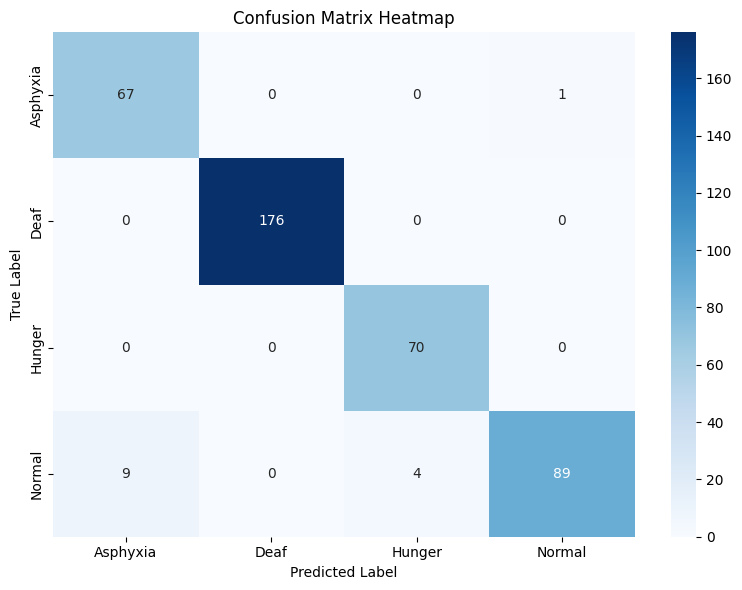

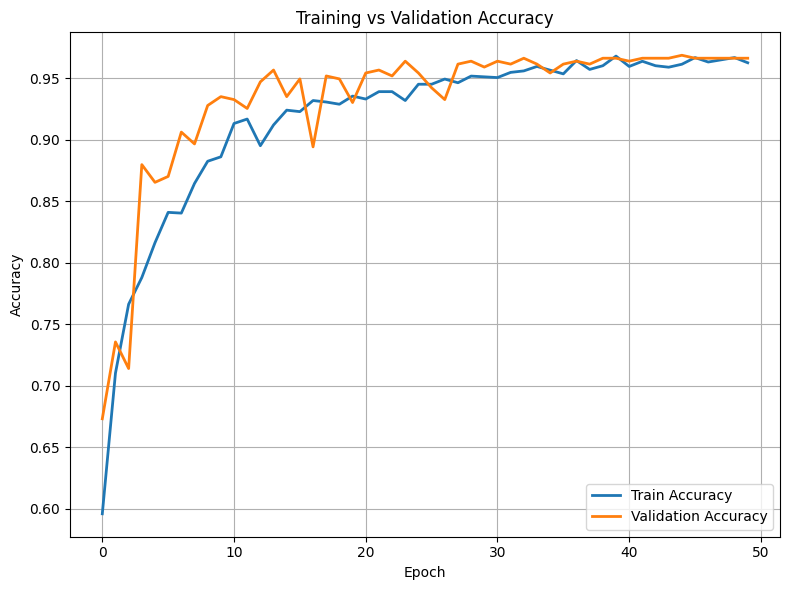

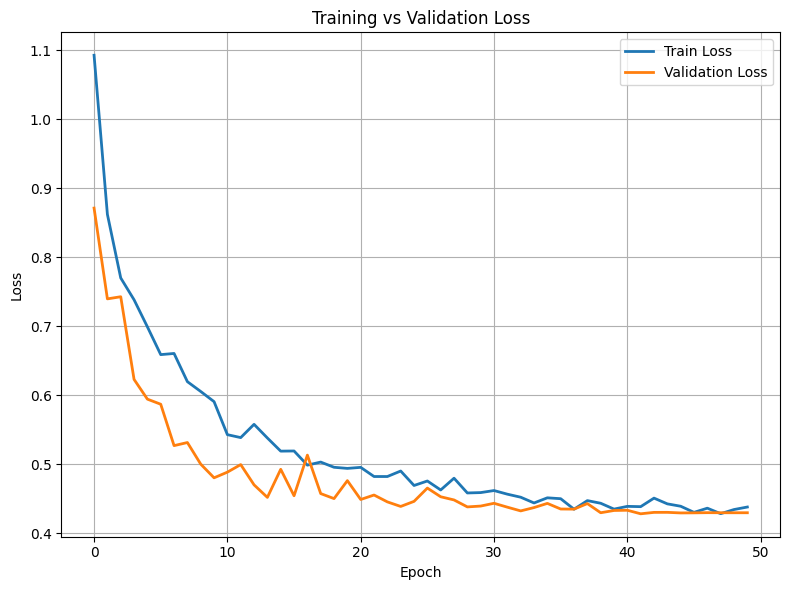

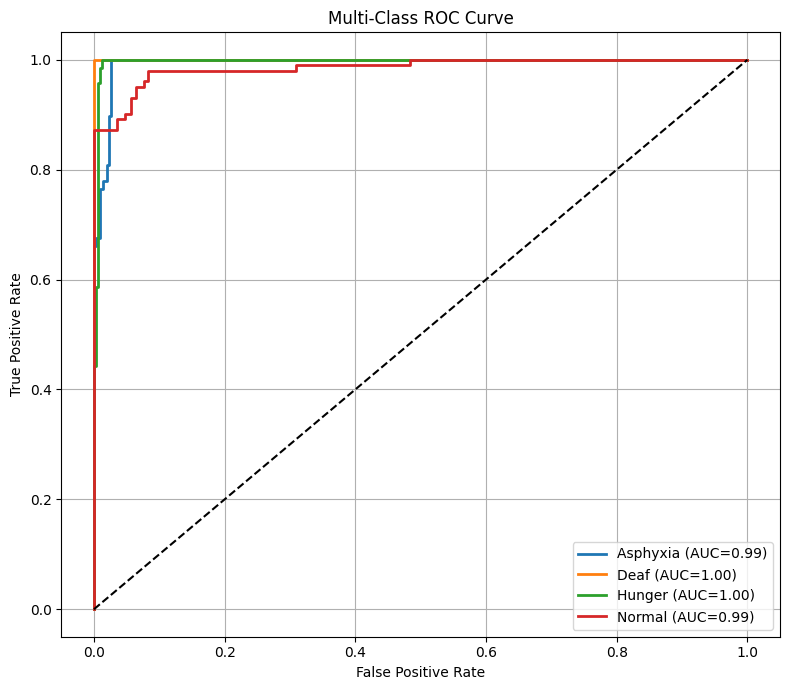


INFERENCE PERFORMANCE
Latency : 4.20 ms/image
FPS     : 237.84

TRAINING TIME
Epoch 01: 22.54 sec
Epoch 02: 22.42 sec
Epoch 03: 22.55 sec
Epoch 04: 22.58 sec
Epoch 05: 22.45 sec
Epoch 06: 22.46 sec
Epoch 07: 22.46 sec
Epoch 08: 22.58 sec
Epoch 09: 22.43 sec
Epoch 10: 22.45 sec
Epoch 11: 22.54 sec
Epoch 12: 22.60 sec
Epoch 13: 22.52 sec
Epoch 14: 22.42 sec
Epoch 15: 22.43 sec
Epoch 16: 22.53 sec
Epoch 17: 22.58 sec
Epoch 18: 22.45 sec
Epoch 19: 22.59 sec
Epoch 20: 22.53 sec
Epoch 21: 22.43 sec
Epoch 22: 22.42 sec
Epoch 23: 22.50 sec
Epoch 24: 22.40 sec
Epoch 25: 22.57 sec
Epoch 26: 22.41 sec
Epoch 27: 22.48 sec
Epoch 28: 22.53 sec
Epoch 29: 22.52 sec
Epoch 30: 22.53 sec
Epoch 31: 22.47 sec
Epoch 32: 22.56 sec
Epoch 33: 22.56 sec
Epoch 34: 22.48 sec
Epoch 35: 22.48 sec
Epoch 36: 22.43 sec
Epoch 37: 22.45 sec
Epoch 38: 22.59 sec
Epoch 39: 22.49 sec
Epoch 40: 22.47 sec
Epoch 41: 22.58 sec
Epoch 42: 22.46 sec
Epoch 43: 22.60 sec
Epoch 44: 22.43 sec
Epoch 45: 22.46 sec
Epoch 46: 22.40 sec
E

In [29]:
# ============================================================
# TinyCryViT - Baby Chillanto RGB Classification
#
# ABLATION CONFIGURATION
#
# Embedding Dimension = 192
# Attention Heads     = 6
# Transformer Blocks  = 3
# GRU Hidden Dimension= 64
# ============================================================

import os
import time
import math
import random

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize

from collections import defaultdict

from thop import profile


# ============================================================
# CONFIGURATION
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# TINYCRYVIT ABLATION CONFIGURATION
# ============================================================

EMBED_DIM = 192
NUM_HEADS = 6
NUM_BLOCKS = 3
GRU_HIDDEN = 64


print("\n==============================================")
print("TinyCryViT Configuration")
print("==============================================")

print("Embedding Dimension :", EMBED_DIM)
print("Attention Heads     :", NUM_HEADS)
print("Transformer Blocks  :", NUM_BLOCKS)
print("GRU Hidden Dimension:", GRU_HIDDEN)
print("Device              :", DEVICE)

print("==============================================")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)


CLASS_NAMES = train_dataset_full.classes
NUM_CLASSES = len(CLASS_NAMES)


print("\nDetected Classes:")
print(CLASS_NAMES)

print(
    "Number of Classes:",
    NUM_CLASSES
)


# ============================================================
# CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(
    train_dataset_full.targets
):
    indices_by_class[label].append(idx)


train_idx = []
val_idx = []


for label, idxs in indices_by_class.items():

    idxs = idxs.copy()

    np.random.shuffle(idxs)

    split = int(
        0.8 * len(idxs)
    )

    train_idx.extend(
        idxs[:split]
    )

    val_idx.extend(
        idxs[split:]
    )


# ============================================================
# DATASET SUBSETS
# ============================================================

train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print(
    "\nTrain Samples      :",
    len(train_ds)
)

print(
    "Validation Samples :",
    len(val_ds)
)


# ============================================================
# PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        embed_dim=192
    ):

        super().__init__()

        self.proj = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=16,
            stride=16
        )


    def forward(self, x):

        # [B, 3, 224, 224]
        x = self.proj(x)

        # [B, 192, 14, 14]
        x = x.flatten(2)

        # [B, 192, 196]
        x = x.transpose(1, 2)

        # [B, 196, 192]
        return x


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim=192,
        heads=6
    ):

        super().__init__()


        self.norm1 = nn.LayerNorm(
            dim
        )


        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=heads,
            batch_first=True
        )


        self.norm2 = nn.LayerNorm(
            dim
        )


        self.mlp = nn.Sequential(

            nn.Linear(
                dim,
                dim * 4
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                dim * 4,
                dim
            )
        )


    def forward(self, x):

        # Self-attention

        normalized_x = self.norm1(x)

        attn_output, _ = self.attn(
            normalized_x,
            normalized_x,
            normalized_x
        )

        x = x + attn_output


        # Feed-forward network

        x = x + self.mlp(
            self.norm2(x)
        )


        return x


# ============================================================
# TinyCryViT MODEL
# ============================================================

class TinyCryViT(nn.Module):

    def __init__(
        self,
        embed_dim=192,
        num_blocks=3,
        num_heads=6,
        gru_hidden=64,
        num_classes=NUM_CLASSES
    ):

        super().__init__()


        # ----------------------------------------
        # Patch Embedding
        # ----------------------------------------

        self.patch = PatchEmbedding(
            embed_dim=embed_dim
        )


        # ----------------------------------------
        # Transformer Blocks
        # ----------------------------------------

        transformer_layers = []


        for _ in range(num_blocks):

            transformer_layers.append(

                TransformerBlock(

                    dim=embed_dim,

                    heads=num_heads
                )
            )


        self.blocks = nn.Sequential(
            *transformer_layers
        )


        # ----------------------------------------
        # Bidirectional GRU
        # ----------------------------------------

        self.bigru = nn.GRU(

            input_size=embed_dim,

            hidden_size=gru_hidden,

            bidirectional=True,

            batch_first=True
        )


        # ----------------------------------------
        # Classification Head
        # ----------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(
                gru_hidden * 2,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(self, x):

        # Patch embedding

        x = self.patch(x)


        # Transformer blocks

        x = self.blocks(x)


        # BiGRU

        _, h = self.bigru(x)


        # Forward + backward hidden states

        h = torch.cat(
            [
                h[-2],
                h[-1]
            ],
            dim=1
        )


        # Classification

        out = self.fc(h)


        return out


# ============================================================
# CREATE MODEL
# ============================================================

model = TinyCryViT(

    embed_dim=EMBED_DIM,

    num_blocks=NUM_BLOCKS,

    num_heads=NUM_HEADS,

    gru_hidden=GRU_HIDDEN,

    num_classes=NUM_CLASSES

).to(DEVICE)


print("\nModel created successfully.")


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


non_trainable_params = (
    total_params -
    trainable_params
)


# ============================================================
# GFLOPs
# ============================================================

dummy = torch.randn(
    1,
    3,
    IMG_SIZE,
    IMG_SIZE
).to(DEVICE)


model.eval()


flops, params = profile(
    model,
    inputs=(dummy,),
    verbose=False
)


gflops = flops / 1e9


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_file = "temp_model.pth"


torch.save(
    model.state_dict(),
    temp_model_file
)


model_size_mb = (
    os.path.getsize(
        temp_model_file
    )
    /
    (1024 * 1024)
)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

print("\n==============================================")
print("MODEL COMPLEXITY")
print("==============================================")


print(
    "Embedding Dimension     :",
    EMBED_DIM
)

print(
    "Attention Heads         :",
    NUM_HEADS
)

print(
    "Transformer Blocks      :",
    NUM_BLOCKS
)

print(
    "GRU Hidden Dimension    :",
    GRU_HIDDEN
)

print(
    "Total Parameters        :",
    f"{total_params:,}"
)

print(
    "Trainable Parameters    :",
    f"{trainable_params:,}"
)

print(
    "Non-Trainable Parameters:",
    f"{non_trainable_params:,}"
)

print(
    "GFLOPs                  :",
    f"{gflops:.4f}"
)

print(
    "Model Size              :",
    f"{model_size_mb:.2f} MB"
)

print("==============================================")


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LR,

    weight_decay=1e-4
)


# ============================================================
# LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS
)


# ============================================================
# TRAINING HISTORY
# ============================================================

history = {

    "train_acc": [],

    "val_acc": [],

    "train_loss": [],

    "val_loss": [],

    "epoch_time": []

}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(
    loader,
    train=True
):

    if train:
        model.train()
    else:
        model.eval()


    total_loss = 0.0

    correct = 0

    total = 0


    y_true = []

    y_pred = []

    y_score = []


    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )


        if train:

            optimizer.zero_grad()


        with torch.set_grad_enabled(train):

            out = model(x)

            loss = criterion(
                out,
                y
            )


            if train:

                loss.backward()

                optimizer.step()


        total_loss += loss.item()


        preds = out.argmax(
            dim=1
        )


        correct += (
            preds == y
        ).sum().item()


        total += y.size(0)


        y_true.extend(

            y.detach()
            .cpu()
            .numpy()
        )


        y_pred.extend(

            preds.detach()
            .cpu()
            .numpy()
        )


        probabilities = torch.softmax(
            out,
            dim=1
        )


        y_score.extend(

            probabilities.detach()
            .cpu()
            .numpy()
        )


    avg_loss = (
        total_loss /
        len(loader)
    )


    accuracy = (
        correct /
        total
    )


    return (
        avg_loss,
        accuracy,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


# ============================================================
# TRAINING
# ============================================================

print("\n==============================================")
print("TRAINING STARTED")
print("==============================================")


training_start = time.time()


for epoch in range(EPOCHS):

    epoch_start = time.time()


    # ----------------------------------------
    # Training
    # ----------------------------------------

    (
        train_loss,
        train_acc,
        _,
        _,
        _
    ) = run_epoch(
        train_loader,
        train=True
    )


    # ----------------------------------------
    # Validation
    # ----------------------------------------

    (
        val_loss,
        val_acc,
        y_true,
        y_pred,
        y_score
    ) = run_epoch(
        val_loader,
        train=False
    )


    # ----------------------------------------
    # Scheduler
    # ----------------------------------------

    scheduler.step()


    # ----------------------------------------
    # Epoch time
    # ----------------------------------------

    epoch_time = (
        time.time() -
        epoch_start
    )


    # ----------------------------------------
    # Save history
    # ----------------------------------------

    history[
        "train_acc"
    ].append(
        train_acc
    )


    history[
        "val_acc"
    ].append(
        val_acc
    )


    history[
        "train_loss"
    ].append(
        train_loss
    )


    history[
        "val_loss"
    ].append(
        val_loss
    )


    history[
        "epoch_time"
    ].append(
        epoch_time
    )


    # ----------------------------------------
    # Print epoch
    # ----------------------------------------

    print(

        f"Epoch [{epoch + 1}/{EPOCHS}] | "

        f"Train Acc: {train_acc:.4f} | "

        f"Val Acc: {val_acc:.4f} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Time: {epoch_time:.2f} sec"

    )


training_end = time.time()


total_training_time = (
    training_end -
    training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(
    y_true,
    y_pred
)


overall_prec, overall_rec, overall_f1, _ = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average="macro",

        zero_division=0

    )
)


overall_std = np.std(
    y_pred == y_true
)


overall_rmse = math.sqrt(

    mean_squared_error(
        y_true,
        y_pred
    )
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc:.4f}"
)


print(
    f"Accuracy (%)        : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Precision           : "
    f"{overall_prec:.4f}"
)


print(
    f"Recall              : "
    f"{overall_rec:.4f}"
)


print(
    f"F1-Score            : "
    f"{overall_f1:.4f}"
)


print(
    f"Standard Deviation  : "
    f"{overall_std:.4f}"
)


print(
    f"RMSE                : "
    f"{overall_rmse:.4f}"
)


print(
    f"Total Parameters    : "
    f"{total_params:,}"
)


print(
    f"Trainable Parameters: "
    f"{trainable_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print(
    f"Model Size          : "
    f"{model_size_mb:.2f} MB"
)


print(
    f"Training Time       : "
    f"{total_training_time:.2f} sec"
)


print("==============================================")


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average=None,

        zero_division=0

    )
)


print("\n==============================================")
print("CLASSWISE METRICS")
print("==============================================")


for i, name in enumerate(CLASS_NAMES):

    idx = (
        y_true == i
    )


    class_acc = np.mean(
        y_pred[idx] == i
    )


    class_std = np.std(
        y_pred[idx] == i
    )


    class_rmse = math.sqrt(

        mean_squared_error(

            y_true[idx],

            y_pred[idx]

        )
    )


    print(
        f"\nClass: {name}"
    )


    print(
        f"Accuracy     : "
        f"{class_acc:.4f}"
    )


    print(
        f"Precision    : "
        f"{class_prec[i]:.4f}"
    )


    print(
        f"Recall       : "
        f"{class_rec[i]:.4f}"
    )


    print(
        f"F1-Score     : "
        f"{class_f1[i]:.4f}"
    )


    print(
        f"Standard Dev : "
        f"{class_std:.4f}"
    )


    print(
        f"RMSE         : "
        f"{class_rmse:.4f}"
    )


    print(
        f"Samples      : "
        f"{support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")


print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES

)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Confusion Matrix Heatmap"
)


plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_acc"],

    label="Train Accuracy",

    linewidth=2

)


plt.plot(

    history["val_acc"],

    label="Validation Accuracy",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_loss"],

    label="Train Loss",

    linewidth=2

)


plt.plot(

    history["val_loss"],

    label="Validation Loss",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training vs Validation Loss"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(

    y_true,

    classes=range(NUM_CLASSES)

)


plt.figure(
    figsize=(8, 7)
)


for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(

        y_bin[:, i],

        y_score[:, i]

    )


    roc_auc = auc(

        fpr,

        tpr

    )


    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=(

            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"

        )

    )


plt.plot(

    [0, 1],

    [0, 1],

    "k--"

)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Multi-Class ROC Curve"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# INFERENCE LATENCY AND FPS
# ============================================================

model.eval()


# Warm-up

with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


end = time.time()


latency = (
    end - start
) / 30


fps = 1 / latency


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")


print(
    f"Latency : "
    f"{latency * 1000:.2f} ms/image"
)


print(
    f"FPS     : "
    f"{fps:.2f}"
)


# ============================================================
# TRAINING TIME
# ============================================================

print("\n==============================================")
print("TRAINING TIME")
print("==============================================")


for i, t in enumerate(
    history["epoch_time"]
):

    print(

        f"Epoch {i + 1:02d}: "
        f"{t:.2f} sec"

    )


print(

    f"\nTotal Training Time: "
    f"{total_training_time:.2f} sec"

)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_NAME = (
    "TinyCryViT_E192_H6_B3_GRU64.pth"
)


torch.save(

    model.state_dict(),

    MODEL_NAME

)


print("\n==============================================")
print("MODEL SAVED")
print("==============================================")


print(
    "File:",
    MODEL_NAME
)


# ============================================================
# FINAL ABLATION SUMMARY
# ============================================================

print("\n==============================================")
print("ABLATION SUMMARY")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Parameters          : "
    f"{total_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print("==============================================")



TinyCryViT Configuration
Embedding Dimension : 192
Attention Heads     : 6
Transformer Blocks  : 3
GRU Hidden Dimension: 96
Device              : cuda

Detected Classes:
['Asphyxia', 'Deaf', 'Hunger', 'Normal']
Number of Classes: 4

Train Samples      : 1660
Validation Samples : 416

Model created successfully.

MODEL COMPLEXITY
Embedding Dimension     : 192
Attention Heads         : 6
Transformer Blocks      : 3
GRU Hidden Dimension    : 96
Total Parameters        : 1,674,500
Trainable Parameters    : 1,674,500
Non-Trainable Parameters: 0
GFLOPs                  : 0.2362
Model Size              : 6.41 MB

TRAINING STARTED
Epoch [1/50] | Train Acc: 0.5886 | Val Acc: 0.7596 | Train Loss: 1.0651 | Val Loss: 0.8326 | Time: 22.58 sec
Epoch [2/50] | Train Acc: 0.7012 | Val Acc: 0.8029 | Train Loss: 0.8455 | Val Loss: 0.7110 | Time: 22.47 sec
Epoch [3/50] | Train Acc: 0.7729 | Val Acc: 0.8269 | Train Loss: 0.7685 | Val Loss: 0.6704 | Time: 22.58 sec
Epoch [4/50] | Train Acc: 0.7801 | Val Ac

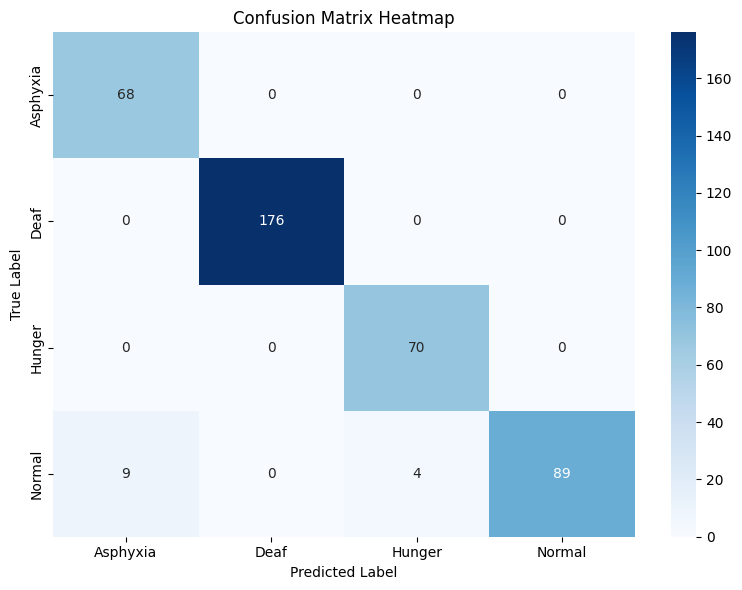

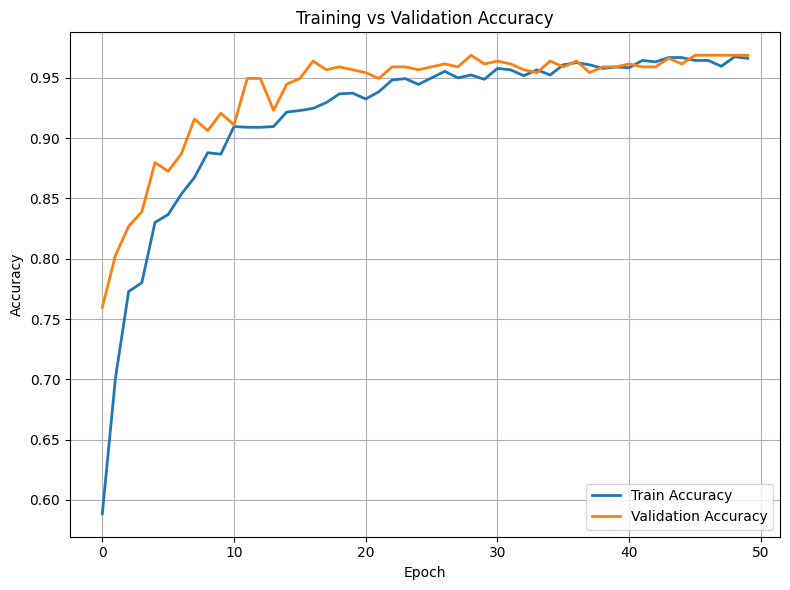

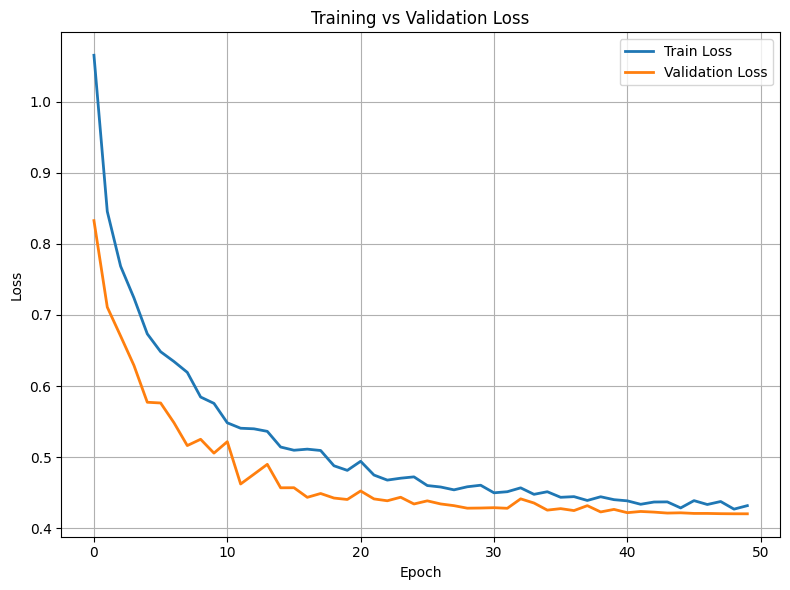

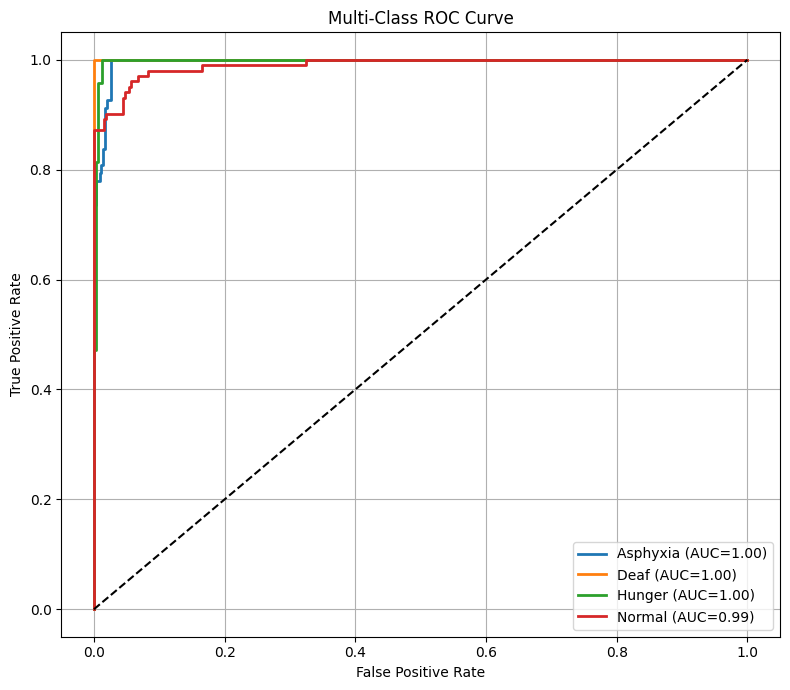


INFERENCE PERFORMANCE
Latency : 4.31 ms/image
FPS     : 231.89

TRAINING TIME
Epoch 01: 22.58 sec
Epoch 02: 22.47 sec
Epoch 03: 22.58 sec
Epoch 04: 22.57 sec
Epoch 05: 22.53 sec
Epoch 06: 22.52 sec
Epoch 07: 22.42 sec
Epoch 08: 22.56 sec
Epoch 09: 22.45 sec
Epoch 10: 22.58 sec
Epoch 11: 22.55 sec
Epoch 12: 22.53 sec
Epoch 13: 22.47 sec
Epoch 14: 22.53 sec
Epoch 15: 22.54 sec
Epoch 16: 22.53 sec
Epoch 17: 22.45 sec
Epoch 18: 22.45 sec
Epoch 19: 22.38 sec
Epoch 20: 22.46 sec
Epoch 21: 22.48 sec
Epoch 22: 22.43 sec
Epoch 23: 22.57 sec
Epoch 24: 22.46 sec
Epoch 25: 22.52 sec
Epoch 26: 22.52 sec
Epoch 27: 22.56 sec
Epoch 28: 22.44 sec
Epoch 29: 22.47 sec
Epoch 30: 22.52 sec
Epoch 31: 22.51 sec
Epoch 32: 22.51 sec
Epoch 33: 22.56 sec
Epoch 34: 22.45 sec
Epoch 35: 22.41 sec
Epoch 36: 22.53 sec
Epoch 37: 22.51 sec
Epoch 38: 22.47 sec
Epoch 39: 22.52 sec
Epoch 40: 22.61 sec
Epoch 41: 22.45 sec
Epoch 42: 22.55 sec
Epoch 43: 22.55 sec
Epoch 44: 22.58 sec
Epoch 45: 22.48 sec
Epoch 46: 22.48 sec
E

In [30]:
# ============================================================
# TinyCryViT - Baby Chillanto RGB Classification
#
# ABLATION CONFIGURATION
#
# Embedding Dimension = 192
# Attention Heads     = 6
# Transformer Blocks  = 3
# GRU Hidden Dimension= 96
# ============================================================

import os
import time
import math
import random

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error
)

from sklearn.preprocessing import label_binarize

from collections import defaultdict

from thop import profile


# ============================================================
# CONFIGURATION
# ============================================================

DATA_ROOT = "/workspace/4class/"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# TINYCRYVIT ABLATION CONFIGURATION
# ============================================================

EMBED_DIM = 192
NUM_HEADS = 6
NUM_BLOCKS = 3
GRU_HIDDEN = 96


print("\n==============================================")
print("TinyCryViT Configuration")
print("==============================================")

print("Embedding Dimension :", EMBED_DIM)
print("Attention Heads     :", NUM_HEADS)
print("Transformer Blocks  :", NUM_BLOCKS)
print("GRU Hidden Dimension:", GRU_HIDDEN)
print("Device              :", DEVICE)

print("==============================================")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# TRANSFORMS
# ============================================================

train_tf = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


val_tf = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


# ============================================================
# LOAD DATASET
# ============================================================

train_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=train_tf
)

val_dataset_full = datasets.ImageFolder(
    DATA_ROOT,
    transform=val_tf
)


CLASS_NAMES = train_dataset_full.classes
NUM_CLASSES = len(CLASS_NAMES)


print("\nDetected Classes:")
print(CLASS_NAMES)

print(
    "Number of Classes:",
    NUM_CLASSES
)


# ============================================================
# CLASSWISE 80:20 SPLIT
# ============================================================

indices_by_class = defaultdict(list)

for idx, label in enumerate(
    train_dataset_full.targets
):
    indices_by_class[label].append(idx)


train_idx = []
val_idx = []


for label, idxs in indices_by_class.items():

    idxs = idxs.copy()

    np.random.shuffle(idxs)

    split = int(
        0.8 * len(idxs)
    )

    train_idx.extend(
        idxs[:split]
    )

    val_idx.extend(
        idxs[split:]
    )


# ============================================================
# DATASET SUBSETS
# ============================================================

train_ds = Subset(
    train_dataset_full,
    train_idx
)

val_ds = Subset(
    val_dataset_full,
    val_idx
)


# ============================================================
# DATA LOADERS
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print(
    "\nTrain Samples      :",
    len(train_ds)
)

print(
    "Validation Samples :",
    len(val_ds)
)


# ============================================================
# PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        embed_dim=192
    ):

        super().__init__()

        self.proj = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=16,
            stride=16
        )


    def forward(self, x):

        # [B, 3, 224, 224]
        x = self.proj(x)

        # [B, 192, 14, 14]
        x = x.flatten(2)

        # [B, 192, 196]
        x = x.transpose(1, 2)

        # [B, 196, 192]
        return x


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim=192,
        heads=6
    ):

        super().__init__()


        self.norm1 = nn.LayerNorm(
            dim
        )


        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=heads,
            batch_first=True
        )


        self.norm2 = nn.LayerNorm(
            dim
        )


        self.mlp = nn.Sequential(

            nn.Linear(
                dim,
                dim * 4
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                dim * 4,
                dim
            )
        )


    def forward(self, x):

        # Self-attention

        normalized_x = self.norm1(x)

        attn_output, _ = self.attn(
            normalized_x,
            normalized_x,
            normalized_x
        )

        x = x + attn_output


        # Feed-forward network

        x = x + self.mlp(
            self.norm2(x)
        )


        return x


# ============================================================
# TinyCryViT MODEL
# ============================================================

class TinyCryViT(nn.Module):

    def __init__(
        self,
        embed_dim=192,
        num_blocks=3,
        num_heads=6,
        gru_hidden=96,
        num_classes=NUM_CLASSES
    ):

        super().__init__()


        # ----------------------------------------
        # Patch Embedding
        # ----------------------------------------

        self.patch = PatchEmbedding(
            embed_dim=embed_dim
        )


        # ----------------------------------------
        # Transformer Blocks
        # ----------------------------------------

        transformer_layers = []


        for _ in range(num_blocks):

            transformer_layers.append(

                TransformerBlock(

                    dim=embed_dim,

                    heads=num_heads
                )
            )


        self.blocks = nn.Sequential(
            *transformer_layers
        )


        # ----------------------------------------
        # Bidirectional GRU
        # ----------------------------------------

        self.bigru = nn.GRU(

            input_size=embed_dim,

            hidden_size=gru_hidden,

            bidirectional=True,

            batch_first=True
        )


        # ----------------------------------------
        # Classification Head
        # ----------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(
                gru_hidden * 2,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(self, x):

        # Patch embedding

        x = self.patch(x)


        # Transformer blocks

        x = self.blocks(x)


        # BiGRU

        _, h = self.bigru(x)


        # Forward + backward hidden states

        h = torch.cat(
            [
                h[-2],
                h[-1]
            ],
            dim=1
        )


        # Classification

        out = self.fc(h)


        return out


# ============================================================
# CREATE MODEL
# ============================================================

model = TinyCryViT(

    embed_dim=EMBED_DIM,

    num_blocks=NUM_BLOCKS,

    num_heads=NUM_HEADS,

    gru_hidden=GRU_HIDDEN,

    num_classes=NUM_CLASSES

).to(DEVICE)


print("\nModel created successfully.")


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


non_trainable_params = (
    total_params -
    trainable_params
)


# ============================================================
# GFLOPs
# ============================================================

dummy = torch.randn(
    1,
    3,
    IMG_SIZE,
    IMG_SIZE
).to(DEVICE)


model.eval()


flops, params = profile(
    model,
    inputs=(dummy,),
    verbose=False
)


gflops = flops / 1e9


# ============================================================
# MODEL SIZE
# ============================================================

temp_model_file = "temp_model.pth"


torch.save(
    model.state_dict(),
    temp_model_file
)


model_size_mb = (
    os.path.getsize(
        temp_model_file
    )
    /
    (1024 * 1024)
)


# ============================================================
# MODEL COMPLEXITY
# ============================================================

print("\n==============================================")
print("MODEL COMPLEXITY")
print("==============================================")


print(
    "Embedding Dimension     :",
    EMBED_DIM
)

print(
    "Attention Heads         :",
    NUM_HEADS
)

print(
    "Transformer Blocks      :",
    NUM_BLOCKS
)

print(
    "GRU Hidden Dimension    :",
    GRU_HIDDEN
)

print(
    "Total Parameters        :",
    f"{total_params:,}"
)

print(
    "Trainable Parameters    :",
    f"{trainable_params:,}"
)

print(
    "Non-Trainable Parameters:",
    f"{non_trainable_params:,}"
)

print(
    "GFLOPs                  :",
    f"{gflops:.4f}"
)

print(
    "Model Size              :",
    f"{model_size_mb:.2f} MB"
)

print("==============================================")


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LR,

    weight_decay=1e-4
)


# ============================================================
# LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS
)


# ============================================================
# TRAINING HISTORY
# ============================================================

history = {

    "train_acc": [],

    "val_acc": [],

    "train_loss": [],

    "val_loss": [],

    "epoch_time": []

}


# ============================================================
# TRAIN / VALIDATION FUNCTION
# ============================================================

def run_epoch(
    loader,
    train=True
):

    if train:
        model.train()
    else:
        model.eval()


    total_loss = 0.0

    correct = 0

    total = 0


    y_true = []

    y_pred = []

    y_score = []


    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )


        if train:

            optimizer.zero_grad()


        with torch.set_grad_enabled(train):

            out = model(x)

            loss = criterion(
                out,
                y
            )


            if train:

                loss.backward()

                optimizer.step()


        total_loss += loss.item()


        preds = out.argmax(
            dim=1
        )


        correct += (
            preds == y
        ).sum().item()


        total += y.size(0)


        y_true.extend(

            y.detach()
            .cpu()
            .numpy()
        )


        y_pred.extend(

            preds.detach()
            .cpu()
            .numpy()
        )


        probabilities = torch.softmax(
            out,
            dim=1
        )


        y_score.extend(

            probabilities.detach()
            .cpu()
            .numpy()
        )


    avg_loss = (
        total_loss /
        len(loader)
    )


    accuracy = (
        correct /
        total
    )


    return (
        avg_loss,
        accuracy,
        np.array(y_true),
        np.array(y_pred),
        np.array(y_score)
    )


# ============================================================
# TRAINING
# ============================================================

print("\n==============================================")
print("TRAINING STARTED")
print("==============================================")


training_start = time.time()


for epoch in range(EPOCHS):

    epoch_start = time.time()


    # ----------------------------------------
    # Training
    # ----------------------------------------

    (
        train_loss,
        train_acc,
        _,
        _,
        _
    ) = run_epoch(
        train_loader,
        train=True
    )


    # ----------------------------------------
    # Validation
    # ----------------------------------------

    (
        val_loss,
        val_acc,
        y_true,
        y_pred,
        y_score
    ) = run_epoch(
        val_loader,
        train=False
    )


    # ----------------------------------------
    # Scheduler
    # ----------------------------------------

    scheduler.step()


    # ----------------------------------------
    # Epoch time
    # ----------------------------------------

    epoch_time = (
        time.time() -
        epoch_start
    )


    # ----------------------------------------
    # Save history
    # ----------------------------------------

    history[
        "train_acc"
    ].append(
        train_acc
    )


    history[
        "val_acc"
    ].append(
        val_acc
    )


    history[
        "train_loss"
    ].append(
        train_loss
    )


    history[
        "val_loss"
    ].append(
        val_loss
    )


    history[
        "epoch_time"
    ].append(
        epoch_time
    )


    # ----------------------------------------
    # Print epoch
    # ----------------------------------------

    print(

        f"Epoch [{epoch + 1}/{EPOCHS}] | "

        f"Train Acc: {train_acc:.4f} | "

        f"Val Acc: {val_acc:.4f} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Time: {epoch_time:.2f} sec"

    )


training_end = time.time()


total_training_time = (
    training_end -
    training_start
)


# ============================================================
# OVERALL METRICS
# ============================================================

overall_acc = accuracy_score(
    y_true,
    y_pred
)


overall_prec, overall_rec, overall_f1, _ = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average="macro",

        zero_division=0

    )
)


overall_std = np.std(
    y_pred == y_true
)


overall_rmse = math.sqrt(

    mean_squared_error(
        y_true,
        y_pred
    )
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc:.4f}"
)


print(
    f"Accuracy (%)        : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Precision           : "
    f"{overall_prec:.4f}"
)


print(
    f"Recall              : "
    f"{overall_rec:.4f}"
)


print(
    f"F1-Score            : "
    f"{overall_f1:.4f}"
)


print(
    f"Standard Deviation  : "
    f"{overall_std:.4f}"
)


print(
    f"RMSE                : "
    f"{overall_rmse:.4f}"
)


print(
    f"Total Parameters    : "
    f"{total_params:,}"
)


print(
    f"Trainable Parameters: "
    f"{trainable_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print(
    f"Model Size          : "
    f"{model_size_mb:.2f} MB"
)


print(
    f"Training Time       : "
    f"{total_training_time:.2f} sec"
)


print("==============================================")


# ============================================================
# CLASSWISE METRICS
# ============================================================

class_prec, class_rec, class_f1, support = (

    precision_recall_fscore_support(

        y_true,

        y_pred,

        average=None,

        zero_division=0

    )
)


print("\n==============================================")
print("CLASSWISE METRICS")
print("==============================================")


for i, name in enumerate(CLASS_NAMES):

    idx = (
        y_true == i
    )


    class_acc = np.mean(
        y_pred[idx] == i
    )


    class_std = np.std(
        y_pred[idx] == i
    )


    class_rmse = math.sqrt(

        mean_squared_error(

            y_true[idx],

            y_pred[idx]

        )
    )


    print(
        f"\nClass: {name}"
    )


    print(
        f"Accuracy     : "
        f"{class_acc:.4f}"
    )


    print(
        f"Precision    : "
        f"{class_prec[i]:.4f}"
    )


    print(
        f"Recall       : "
        f"{class_rec[i]:.4f}"
    )


    print(
        f"F1-Score     : "
        f"{class_f1[i]:.4f}"
    )


    print(
        f"Standard Dev : "
        f"{class_std:.4f}"
    )


    print(
        f"RMSE         : "
        f"{class_rmse:.4f}"
    )


    print(
        f"Samples      : "
        f"{support[i]}"
    )


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")


print(cm)


# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES

)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Confusion Matrix Heatmap"
)


plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_acc"],

    label="Train Accuracy",

    linewidth=2

)


plt.plot(

    history["val_acc"],

    label="Validation Accuracy",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(

    history["train_loss"],

    label="Train Loss",

    linewidth=2

)


plt.plot(

    history["val_loss"],

    label="Validation Loss",

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training vs Validation Loss"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# ROC CURVE
# ============================================================

y_bin = label_binarize(

    y_true,

    classes=range(NUM_CLASSES)

)


plt.figure(
    figsize=(8, 7)
)


for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(

        y_bin[:, i],

        y_score[:, i]

    )


    roc_auc = auc(

        fpr,

        tpr

    )


    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=(

            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.2f})"

        )

    )


plt.plot(

    [0, 1],

    [0, 1],

    "k--"

)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Multi-Class ROC Curve"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# INFERENCE LATENCY AND FPS
# ============================================================

model.eval()


# Warm-up

with torch.no_grad():

    for _ in range(10):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


start = time.time()


with torch.no_grad():

    for _ in range(30):

        _ = model(dummy)


if DEVICE == "cuda":

    torch.cuda.synchronize()


end = time.time()


latency = (
    end - start
) / 30


fps = 1 / latency


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")


print(
    f"Latency : "
    f"{latency * 1000:.2f} ms/image"
)


print(
    f"FPS     : "
    f"{fps:.2f}"
)


# ============================================================
# TRAINING TIME
# ============================================================

print("\n==============================================")
print("TRAINING TIME")
print("==============================================")


for i, t in enumerate(
    history["epoch_time"]
):

    print(

        f"Epoch {i + 1:02d}: "
        f"{t:.2f} sec"

    )


print(

    f"\nTotal Training Time: "
    f"{total_training_time:.2f} sec"

)


# ============================================================
# SAVE MODEL
# ============================================================

MODEL_NAME = (
    "TinyCryViT_E192_H6_B3_GRU96.pth"
)


torch.save(

    model.state_dict(),

    MODEL_NAME

)


print("\n==============================================")
print("MODEL SAVED")
print("==============================================")


print(
    "File:",
    MODEL_NAME
)


# ============================================================
# FINAL ABLATION SUMMARY
# ============================================================

print("\n==============================================")
print("ABLATION SUMMARY")
print("==============================================")


print(
    f"Embedding Dimension : "
    f"{EMBED_DIM}"
)


print(
    f"Attention Heads     : "
    f"{NUM_HEADS}"
)


print(
    f"Transformer Blocks  : "
    f"{NUM_BLOCKS}"
)


print(
    f"GRU Hidden Dimension: "
    f"{GRU_HIDDEN}"
)


print(
    f"Accuracy            : "
    f"{overall_acc * 100:.2f}%"
)


print(
    f"Parameters          : "
    f"{total_params:,}"
)


print(
    f"GFLOPs              : "
    f"{gflops:.4f}"
)


print("==============================================")
